# AI Lab 2026 - scRNA-seq Hypoxia Classification

Bocconi MMML AI Lab 2026. This notebook analyses single-cell RNA-sequence data for binary classification of **hypoxia versus normoxia** in two breast-cancer cell lines, MCF7 and HCC1806, profiled using two technologies, SmartSeq and DropSeq.

The report proceeds from data loading and quality control to distributional EDA, analysis-ready data preparation, unsupervised structure discovery, supervised classification, cross-domain generalisation, and final test-set prediction. Each section documents the relevant preprocessing choices, outputs, and interpretation needed to reproduce the analysis.

## 0. Setup

Imports, plot defaults, and project paths.

In [2]:
import sys
import time
import warnings
from pathlib import Path

from scipy.stats import skew, kurtosis, kruskal, mannwhitneyu
from scipy.cluster.hierarchy import linkage, dendrogram
from scipy.sparse.csgraph import connected_components
import networkx as nx
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.base import clone
from sklearn.decomposition import PCA, KernelPCA, FactorAnalysis, FastICA, MiniBatchSparsePCA
from sklearn.cross_decomposition import PLSRegression
from sklearn.cluster import KMeans, MiniBatchKMeans, AgglomerativeClustering, DBSCAN
from sklearn.metrics import (
    silhouette_score, adjusted_rand_score, normalized_mutual_info_score, accuracy_score, balanced_accuracy_score, f1_score, 
    roc_auc_score, confusion_matrix, ConfusionMatrixDisplay, precision_score, recall_score, average_precision_score
    )
from sklearn.neighbors import NearestNeighbors, KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.random_projection import GaussianRandomProjection
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.model_selection import StratifiedKFold, RepeatedStratifiedKFold, GridSearchCV, cross_val_predict
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC, SVC
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier

from itertools import combinations
from collections import Counter

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings(
    "ignore",
    message="Features .* are constant.",
    category=UserWarning,
)

warnings.filterwarnings(
    "ignore",
    message="invalid value encountered in divide",
    category=RuntimeWarning,
)

SUPERVISED_RANDOM_STATE = 42
N_JOBS = -1

SUPERVISED_RUN_MODE = "fast" 

try:
    import umap.umap_ as umap
except ImportError as exc:
    umap = None
    UMAP_IMPORT_ERROR = exc
else:
    UMAP_IMPORT_ERROR = None

# Notebook-wide plot defaults.
%matplotlib inline
sns.set_theme(color_codes=True)
plt.rcParams["figure.dpi"] = 100

# Project paths.
DATA_ROOT = Path(".")
SMARTSEQ  = DATA_ROOT / "SmartSeq"
DROPSEQ   = DATA_ROOT / "DropSeq"

print(f"Python {sys.version.split()[0]}, pandas {pd.__version__}, numpy {np.__version__}")
print("SmartSeq folder exists:", SMARTSEQ.exists())
print("DropSeq folder exists: ", DROPSEQ.exists())
if UMAP_IMPORT_ERROR is not None:
    print("Optional dependency unavailable: umap-learn. Section 6.4 will be skipped unless it is installed.")


Python 3.12.13, pandas 3.0.2, numpy 2.0.1
SmartSeq folder exists: True
DropSeq folder exists:  True


## 1. Introduction

Hypoxia means that cells are growing in a low-oxygen environment. This is important in solid tumours because cancer cells exposed to low oxygen often become harder to treat, more likely to spread, and are linked to worse patient outcomes. In this project, we use single-cell RNA sequencing data, which measures gene activity in individual cells, to investigate whether we can predict whether a cancer cell was grown in hypoxia or normoxia using only its gene-expression profile.

The data come from two breast-cancer cell lines, MCF7 and HCC1806, grown under hypoxic and normoxic conditions. Each cell line was measured using two single-cell sequencing technologies: SmartSeq, which measures fewer cells in greater detail, and DropSeq, which measures many more cells but with sparser information per cell. The main prediction task is therefore a binary classification problem: assigning each cell to either `Hypoxia` or `Normoxia`. The analysis begins by checking the structure and quality of the data, then prepares clean and comparable matrices for later unsupervised learning, supervised learning, and final prediction.

## 2. Materials and Methods

**Data.** This analysis uses four training datasets, covering each combination of breast-cancer cell line and sequencing method: MCF7 SmartSeq, HCC1806 SmartSeq, MCF7 DropSeq, and HCC1806 DropSeq. Each dataset contains measurements for 3000 selected genes across many single cells. For SmartSeq, additional metadata and earlier unfiltered/filtered files are also available, which makes it possible to examine how filtering changes the data. The four anonymised test datasets are kept separate for final prediction and are only checked at this stage to make sure they match the training data structure.

**Labels.** Each cell is labelled as either `Hypoxia` or `Normoxia`. For SmartSeq, these labels are taken from the metadata file. For DropSeq, they are extracted from the cell names, where the condition is included at the end of each identifier. Different spellings of the same condition are standardised so that all datasets use the same two labels.

**Preprocessing and quality control.** The notebook first checks that the files have the expected dimensions, that every cell has a matching label, that the training and test files contain genes in the same order, and that the two classes are represented in the data. It also compares the available SmartSeq unfiltered and filtered files to understand what the filtering step removes before the data are used for later analysis.

## 3. Data loading and inventory

This section loads the source data files and records their structure before analysis. We check dimensions, labels, and train/test compatibility so that later EDA and modelling use correctly aligned datasets.

### 3.1 Load SmartSeq metadata

The SmartSeq files are accompanied by metadata tables describing each sequenced cell. These metadata are important because they contain the experimental condition for each cell, which is later used as the binary label: hypoxia or normoxia.

In [2]:
# Load SmartSeq metadata tables (one row per cell).
meta_hcc = pd.read_csv(SMARTSEQ / "HCC1806_SmartS_MetaData.tsv", sep="\t", engine="python", index_col=0)
meta_mcf = pd.read_csv(SMARTSEQ / "MCF7_SmartS_MetaData.tsv",    sep="\t", engine="python", index_col=0)

print("HCC1806 metadata:", meta_hcc.shape)
print("MCF7 metadata:   ", meta_mcf.shape)

meta_hcc.head(3)

HCC1806 metadata: (243, 8)
MCF7 metadata:    (383, 8)


,Cell Line,PCR Plate,Pos,Condition,Hours,Cell name,PreprocessingTag,ProcessingComments
Filename,,,,,,,,
output.STAR.PCRPlate1A10_Normoxia_S123_Aligned.sortedByCoord.out.bam,HCC1806,1,A10,Normo,24,S123,Aligned.sortedByCoord.out.bam,"STAR,FeatureCounts"
output.STAR.PCRPlate1A12_Normoxia_S26_Aligned.sortedByCoord.out.bam,HCC1806,1,A12,Normo,24,S26,Aligned.sortedByCoord.out.bam,"STAR,FeatureCounts"
output.STAR.PCRPlate1A1_Hypoxia_S97_Aligned.sortedByCoord.out.bam,HCC1806,1,A1,Hypo,24,S97,Aligned.sortedByCoord.out.bam,"STAR,FeatureCounts"


The metadata tables contain one row per sequenced SmartSeq cell. The key field is `Condition`, which identifies hypoxia or normoxia and is later standardised for use as the binary target.

### 3.2 Load expression matrices

The expression matrices are loaded with genes as rows and cells as columns, matching the original file format. We preserve this orientation throughout the EDA and QC sections, since gene-level operations (per-gene zero fractions, duplicate detection, gene-order checks against the test files) are more natural in that layout.

In [3]:
def _strip_quotes(idx):
    """Strip surrounding single/double quotes from an index of strings."""
    return idx.str.strip('"').str.strip("'")


def load_expression(path):
    """Load an expression matrix in genes x cells format."""
    df = pd.read_csv(path, sep=r"\s+", engine="python", index_col=0)
    df.columns = _strip_quotes(df.columns)
    df.index = _strip_quotes(df.index)
    return df


# Filtered, normalised 3000-gene training matrices.
ss_hcc_train = load_expression(SMARTSEQ / "HCC1806_SmartS_Filtered_Normalised_3000_Data_train.txt")
ss_mcf_train = load_expression(SMARTSEQ / "MCF7_SmartS_Filtered_Normalised_3000_Data_train.txt")
ds_hcc_train = load_expression(DROPSEQ / "HCC1806_Filtered_Normalised_3000_Data_train.txt")
ds_mcf_train = load_expression(DROPSEQ / "MCF7_Filtered_Normalised_3000_Data_train.txt")

# SmartSeq unfiltered and filtered count matrices.
ss_hcc_unf = load_expression(SMARTSEQ / "HCC1806_SmartS_Unfiltered_Data.txt")
ss_mcf_unf = load_expression(SMARTSEQ / "MCF7_SmartS_Unfiltered_Data.txt")
ss_hcc_flt = load_expression(SMARTSEQ / "HCC1806_SmartS_Filtered_Data.txt")
ss_mcf_flt = load_expression(SMARTSEQ / "MCF7_SmartS_Filtered_Data.txt")

# Dataset registry: matrix and descriptive fields per dataset name.
DATASETS = {
    "MCF7_SmartSeq":    {"matrix": ss_mcf_train, "cell_line": "MCF7",    "technology": "SmartSeq"},
    "HCC1806_SmartSeq": {"matrix": ss_hcc_train, "cell_line": "HCC1806", "technology": "SmartSeq"},
    "MCF7_DropSeq":     {"matrix": ds_mcf_train, "cell_line": "MCF7",    "technology": "DropSeq"},
    "HCC1806_DropSeq":  {"matrix": ds_hcc_train, "cell_line": "HCC1806", "technology": "DropSeq"},
}

# {name: matrix} view of DATASETS.
downstream_inputs = {name: spec["matrix"] for name, spec in DATASETS.items()}

for name, df in downstream_inputs.items():
    print(name, df.shape, "(genes x cells)")


MCF7_SmartSeq (3000, 250) (genes x cells)
HCC1806_SmartSeq (3000, 182) (genes x cells)
MCF7_DropSeq (3000, 21626) (genes x cells)
HCC1806_DropSeq (3000, 14682) (genes x cells)


All four downstream training matrices share the same orientation: genes as rows and cells as columns. Each contains the 3000 filtered and normalised genes used for downstream analysis. The additional SmartSeq count matrices are retained only for the unfiltered-versus-filtered QC comparison.

### 3.3 Construct training labels

Training labels are constructed from the source most appropriate for each technology. For SmartSeq, the condition is taken from the metadata tables. For DropSeq, the condition is parsed from the cell identifiers. All raw condition names are then standardised to the common labels `Hypoxia` and `Normoxia`.

In [4]:
# Map raw condition spellings to the standard labels.
label_map = {
    "Hypo":  "Hypoxia",
    "Norm":  "Normoxia",
    "Normo": "Normoxia",
}

# Raw condition source per dataset:
#  - SmartSeq: metadata column, matched by cell filename.
#  - DropSeq:  suffix after the final underscore in each cell ID.
raw_labels = {
    "MCF7_SmartSeq":    meta_mcf.loc[ss_mcf_train.columns, "Condition"],
    "HCC1806_SmartSeq": meta_hcc.loc[ss_hcc_train.columns, "Condition"],
    "MCF7_DropSeq":     pd.Series([c.split("_")[-1] for c in ds_mcf_train.columns], index=ds_mcf_train.columns),
    "HCC1806_DropSeq":  pd.Series([c.split("_")[-1] for c in ds_hcc_train.columns], index=ds_hcc_train.columns),
}


def _standardise(s):
    # Map known aliases; leave already-canonical values unchanged.
    return s.map(label_map).fillna(s)


# Long-form label table: one row per cell across all four datasets.
labels = pd.concat(
    [
        pd.DataFrame({
            "cell_id":    DATASETS[name]["matrix"].columns,
            "dataset":    name,
            "cell_line":  DATASETS[name]["cell_line"],
            "technology": DATASETS[name]["technology"],
            "condition":  _standardise(raw_labels[name]).values,
        })
        for name in DATASETS
    ],
    ignore_index=True,
)

print("Total labeled cells:", len(labels))
display(labels.head(3).style.hide(axis="index"))


Total labeled cells: 36740


cell_id,dataset,cell_line,technology,condition
output.STAR.2_B3_Norm_S57_Aligned.sortedByCoord.out.bam,MCF7_SmartSeq,MCF7,SmartSeq,Normoxia
output.STAR.2_B4_Norm_S58_Aligned.sortedByCoord.out.bam,MCF7_SmartSeq,MCF7,SmartSeq,Normoxia
output.STAR.2_B5_Norm_S59_Aligned.sortedByCoord.out.bam,MCF7_SmartSeq,MCF7,SmartSeq,Normoxia


The label table now gives one standardised condition label for every training cell across both technologies. This common label format allows the four datasets to be compared and modelled consistently.

### 3.4 Dataset inventory and label balance

We now summarise the loaded matrices and their associated labels. This inventory checks that each expression matrix has the expected number of genes and cells, and that every training cell has a matching condition label. We also inspect the hypoxia/normoxia balance within each dataset, since class imbalance can influence later model training and performance metrics.

In [5]:
# Inventory table: dimensions and class balance per dataset.

# Hypoxia/Normoxia counts per dataset.
condition_counts = pd.crosstab(labels["dataset"], labels["condition"])

base = (
    labels
    .groupby("dataset")
    .agg(
        cell_line=("cell_line", "first"),
        technology=("technology", "first"),
        cells=("cell_id", "size"),
    )
)

class_balance = base.join(
    condition_counts.rename(columns={
        "Hypoxia":  "hypoxia_cells",
        "Normoxia": "normoxia_cells",
    })
)

class_balance["genes"] = [DATASETS[d]["matrix"].shape[0] for d in class_balance.index]
class_balance["pct_hypoxia"] = (
    100 * class_balance["hypoxia_cells"] / class_balance["cells"]
)

inventory_df = (
    class_balance
    .reindex(list(DATASETS))
    .reset_index()
    [["dataset", "cell_line", "technology", "genes", "cells",
      "hypoxia_cells", "normoxia_cells", "pct_hypoxia"]]
)

display(inventory_df.style.hide(axis="index").format({"pct_hypoxia": "{:.2f}"}))


dataset,cell_line,technology,genes,cells,hypoxia_cells,normoxia_cells,pct_hypoxia
MCF7_SmartSeq,MCF7,SmartSeq,3000,250,124,126,49.60
HCC1806_SmartSeq,HCC1806,SmartSeq,3000,182,97,85,53.30
MCF7_DropSeq,MCF7,DropSeq,3000,21626,8921,12705,41.25
HCC1806_DropSeq,HCC1806,DropSeq,3000,14682,8899,5783,60.61


In [6]:
# Check that each matrix column has exactly one label.
for name, df in downstream_inputs.items():
    n_cells = df.shape[1]
    n_labels = len(labels[labels["dataset"] == name])
    print(name, "matrix cells:", n_cells, "labels:", n_labels)
    assert n_cells == n_labels, f"Mismatch in {name}: {n_cells} cells but {n_labels} labels"

MCF7_SmartSeq matrix cells: 250 labels: 250
HCC1806_SmartSeq matrix cells: 182 labels: 182
MCF7_DropSeq matrix cells: 21626 labels: 21626
HCC1806_DropSeq matrix cells: 14682 labels: 14682


The inventory table summarises the size and class composition of the four training datasets. All matrices contain 3000 genes, but the number of cells differs substantially across technologies: DropSeq contains roughly 60–90 times as many cells as SmartSeq. The SmartSeq datasets are close to balanced (MCF7 49.6% hypoxia, HCC1806 53.3% hypoxia), while the DropSeq datasets are noticeably imbalanced in opposite directions. MCF7 DropSeq is normoxia-heavy (41.3% hypoxia) and HCC1806 DropSeq is hypoxia-heavy (60.6% hypoxia). The alignment check above confirms that every cell column has exactly one corresponding condition label. These differences in sample size and class balance should be carried into later comparisons of model performance across datasets.

### 3.5 Missing values and numeric-type checks

Before moving to QC plots and preprocessing, we verify that the expression matrices are numerically well formed. This check confirms whether all expression columns are numeric, whether any `NaN` values are present, and whether sparsity is represented as explicit zeros rather than missing values. This is important because downstream QC metrics, transformations, and machine-learning methods assume numeric matrices without missing entries.

We run the check both on the four downstream `Filtered_Normalised_3000` training matrices and on the additional SmartSeq unfiltered/filtered count matrices used for QC comparison.

In [7]:
# Check missing values and numeric types for all loaded expression matrices.

matrix_integrity_inputs = {
    **downstream_inputs,
    "MCF7_SmartSeq_unfiltered":    ss_mcf_unf,
    "MCF7_SmartSeq_filtered":      ss_mcf_flt,
    "HCC1806_SmartSeq_unfiltered": ss_hcc_unf,
    "HCC1806_SmartSeq_filtered":   ss_hcc_flt,
}

integrity_rows = []
for name, df in matrix_integrity_inputs.items():
    non_numeric_cols = df.columns.difference(df.select_dtypes(include=[np.number]).columns)
    integrity_rows.append({
        "matrix": name,
        "all_columns_numeric": len(non_numeric_cols) == 0,
        "non_numeric_columns": len(non_numeric_cols),
        "missing_values": int(df.isna().sum().sum()),
    })

integrity_df = pd.DataFrame(integrity_rows)
display(integrity_df.style.hide(axis="index"))

matrix,all_columns_numeric,non_numeric_columns,missing_values
MCF7_SmartSeq,True,0,0
HCC1806_SmartSeq,True,0,0
MCF7_DropSeq,True,0,0
HCC1806_DropSeq,True,0,0
MCF7_SmartSeq_unfiltered,True,0,0
MCF7_SmartSeq_filtered,True,0,0
HCC1806_SmartSeq_unfiltered,True,0,0
HCC1806_SmartSeq_filtered,True,0,0


The integrity check shows that the loaded expression matrices are suitable for downstream EDA and preprocessing: all expression columns are numeric, no missing values are present, and sparsity is encoded as explicit zero counts/values rather than `NaN`. This means that no missing-value imputation or row/column deletion is required at this stage.

### 3.6 Test-file compatibility check

The test files are checked only for structural compatibility with the corresponding training files. Specifically, we verify that the same genes appear in the same order. We do not summarise, transform, or use test-set expression values during preprocessing, which avoids leakage into later modelling steps.

In [8]:
def read_gene_index(path):
    """Read only the gene index from an expression matrix."""
    idx = pd.read_csv(path, sep=r"\s+", engine="python", usecols=[0], index_col=0).index
    return _strip_quotes(idx)


test_files = {
    "MCF7_SmartSeq":    SMARTSEQ / "MCF7_SmartS_Filtered_Normalised_3000_Data_test_anonim.txt",
    "HCC1806_SmartSeq": SMARTSEQ / "HCC1806_SmartS_Filtered_Normalised_3000_Data_test_anonim.txt",
    "MCF7_DropSeq":     DROPSEQ / "MCF7_Filtered_Normalised_3000_Data_test_anonim.txt",
    "HCC1806_DropSeq":  DROPSEQ / "HCC1806_Filtered_Normalised_3000_Data_test_anonim.txt",
}

# Confirm that each test matrix uses the same gene order as its training matrix.
for name, path in test_files.items():
    test_genes = read_gene_index(path)
    train_genes = downstream_inputs[name].index
    if not test_genes.equals(train_genes):
        raise ValueError(f"{name}: train and test genes are not in the same order")
    print(name, "OK")


MCF7_SmartSeq OK
HCC1806_SmartSeq OK
MCF7_DropSeq OK
HCC1806_DropSeq OK


All four test files have the same gene order as their corresponding training files. This confirms that future predictions can be generated without additional gene matching or reordering. Since only the gene index was checked, the test-set expression values were not used during preprocessing.

Together, these checks establish a consistent labelled training structure and confirm that the held-out test files use the same gene ordering as their matching training files. The next section examines SmartSeq filtering effects before moving to the filtered and normalised matrices used downstream.

## 4. Quality control: unfiltered vs filtered SmartSeq data

SmartSeq is provided at both unfiltered and filtered count-matrix levels, while DropSeq is only available after filtering and normalisation. This section therefore uses SmartSeq to inspect what the filtering step removed before moving to the four downstream `Filtered_Normalised_3000` training matrices.

### 4.1 Compute per-cell QC metrics

For each SmartSeq count matrix, we summarise cell-level quality using total counts, detected genes, zero fraction, and mitochondrial fraction. These metrics capture sequencing depth, transcript detection, sparsity, and potential cell stress, and provide a compact basis for comparing unfiltered and filtered data.

In [9]:
# Compute per-cell QC metrics for each SmartSeq count matrix.
qc_rows = []
for cell_line, status, X in [
    ("HCC1806", "unfiltered", ss_hcc_unf),
    ("HCC1806", "filtered",   ss_hcc_flt),
    ("MCF7",    "unfiltered", ss_mcf_unf),
    ("MCF7",    "filtered",   ss_mcf_flt),
]:
    mt_mask = X.index.astype(str).str.startswith("MT-")
    total = X.sum(axis=0)

    if mt_mask.any():
        mt_frac = X.loc[mt_mask].sum(axis=0) / total.replace(0, np.nan)
    else:
        mt_frac = pd.Series(np.nan, index=X.columns)

    qc_rows.append(pd.DataFrame({
        "cell_id":        X.columns,
        "cell_line":      cell_line,
        "status":         status,
        "n_mt_genes":     int(mt_mask.sum()),
        "library_size":   total.values,
        "genes_detected": (X > 0).sum(axis=0).values,
        "frac_zeros":     (X == 0).mean(axis=0).values,
        "mito_fraction":  mt_frac.values,
    }))

qc_df = pd.concat(qc_rows, ignore_index=True)
print("QC table shape:", qc_df.shape)
display(qc_df.head().style.hide(axis="index").format({
    "frac_zeros": "{:.2f}",
    "mito_fraction": "{:.3f}",
}))


QC table shape: (1166, 8)


cell_id,cell_line,status,n_mt_genes,library_size,genes_detected,frac_zeros,mito_fraction
output.STAR.PCRPlate1A10_Normoxia_S123_Aligned.sortedByCoord.out.bam,HCC1806,unfiltered,36,2329439,10796,0.54,0.036
output.STAR.PCRPlate1A12_Normoxia_S26_Aligned.sortedByCoord.out.bam,HCC1806,unfiltered,36,4858841,11251,0.52,0.025
output.STAR.PCRPlate1A1_Hypoxia_S97_Aligned.sortedByCoord.out.bam,HCC1806,unfiltered,36,226818,9887,0.58,0.007
output.STAR.PCRPlate1A2_Hypoxia_S104_Aligned.sortedByCoord.out.bam,HCC1806,unfiltered,36,3525520,7597,0.68,0.012
output.STAR.PCRPlate1A3_Hypoxia_S4_Aligned.sortedByCoord.out.bam,HCC1806,unfiltered,36,835249,10136,0.57,0.011


### 4.2 Summarise the filtering effect

We compare cell counts and QC metric ranges before and after filtering for each SmartSeq cell line. This shows how many cells are retained and whether filtering mainly affects low-quality extremes or shifts the full distribution.

In [10]:
# Per-group QC summary: cell counts and key metrics before and after filtering.

def q1(x): return x.quantile(0.25)
def q3(x): return x.quantile(0.75)

print(qc_df.groupby(["cell_line", "status"]).size().to_string())

print("\nSummary statistics:")
qc_summary = (
    qc_df
    .groupby(["cell_line", "status"])
    .agg(
        n_cells=("cell_id", "nunique"),
        library_median=("library_size", "median"),
        library_q1=("library_size", q1),
        genes_median=("genes_detected", "median"),
        genes_q1=("genes_detected", q1),
        zero_median=("frac_zeros", "median"),
        zero_q3=("frac_zeros", q3),
        mito_median=("mito_fraction", "median"),
        mito_max=("mito_fraction", "max"),
    )
    .round(3)
)

# Cast integer-valued columns from float to int.
int_cols = ["n_cells", "library_median", "library_q1", "genes_median", "genes_q1"]
qc_summary[int_cols] = qc_summary[int_cols].round(0).astype(int)

display(qc_summary)


cell_line  status    
HCC1806    filtered      227
           unfiltered    243
MCF7       filtered      313
           unfiltered    383

Summary statistics:


n_cells  library_median  library_q1  genes_median  \
cell_line status                                                          
HCC1806   filtered        227         2157007     1028006         10832   
          unfiltered      243         2067645      991062         10831   
MCF7      filtered        313         1199011      880121         10203   
          unfiltered      383         1129334      598750          9907   

                      genes_q1  zero_median  zero_q3  mito_median  mito_max  
cell_line status                                                             
HCC1806   filtered       10193        0.445    0.477        0.019     0.049  
          unfiltered     10117        0.537    0.568        0.018     0.492  
MCF7      filtered        9264        0.461    0.511        0.017     0.075  
          unfiltered      8456        0.568    0.631        0.015     0.310

Filtering removed 16 HCC1806 cells and 70 MCF7 cells. The main effect was on low-quality tails and outliers: lower-quartile library size and detected-gene counts increased, zero fractions decreased, and maximum mitochondrial fraction dropped sharply. This suggests that filtering mainly removed weakly captured or damaged cells rather than shifting the entire expression distribution.

### 4.3 Interpreting the preprocessing levels

The SmartSeq data are available as unfiltered counts, filtered counts, and filtered-normalised 3000-gene matrices. We use the unfiltered and filtered SmartSeq files to show what QC changed, while the `Filtered_Normalised_3000` files are used as the common downstream input, since this is the only comparable preprocessing level available for both SmartSeq and DropSeq.

The downstream matrices are already normalised, but they remain count-like and zero-heavy: more than half of all entries are zero in all four training matrices, and the largest values are still far above typical nonzero expression values, especially for SmartSeq. This suggests that normalisation alone has not put the data on a log-transformed or variance-stabilised scale.

### 4.4 Check mitochondrial signal

Mitochondrial expression can indicate stressed or damaged cells. We therefore check whether high mitochondrial fraction explains the filtering pattern, or whether filtering is mainly driven by low capture depth.

In [11]:
# Mitochondrial-fraction summary per (cell_line, status) group.

# Add a combined dataset label and a high-MT flag for the aggregation.
qc_for_mt = qc_df.copy()
qc_for_mt["dataset"] = qc_for_mt["cell_line"] + " " + qc_for_mt["status"]
qc_for_mt["above_10pct_mt"] = (qc_for_mt["mito_fraction"] > 0.10).astype(int)

mt_summary = (
    qc_for_mt
    .groupby("dataset")
    .agg(
        n_cells=("cell_id", "nunique"),
        n_mt_genes=("n_mt_genes", "first"),
        median_mt_fraction=("mito_fraction", "median"),
        cells_above_10pct_mt=("above_10pct_mt", "sum"),
    )
    .reset_index()
)

display(mt_summary.style.hide(axis="index").format({"median_mt_fraction": "{:.4f}"}))


dataset,n_cells,n_mt_genes,median_mt_fraction,cells_above_10pct_mt
HCC1806 filtered,227,35,0.0185,0
HCC1806 unfiltered,243,36,0.0184,1
MCF7 filtered,313,36,0.0172,0
MCF7 unfiltered,383,36,0.0153,2


Mitochondrial genes are present in the SmartSeq count matrices (35–36 per matrix), so mitochondrial fraction can be inspected directly. Only a very small number of unfiltered cells exceed 10% mitochondrial fraction: 1 cell in HCC1806 and 2 cells in MCF7. After filtering, no cells remain above this threshold. The median mitochondrial fraction is also low in all four matrices, around 1.5–1.9%. This suggests that **high mitochondrial content is not the dominant quality problem** in these data. Instead, the filtering pattern is more consistent with other QC signals such as low capture depth and low gene detection.

### 4.5 Visualise QC distributions

We visualise the QC metrics to compare the full distributions before and after filtering. This complements the summary table by showing whether filtering removes only extreme cells or changes the overall shape of the quality distributions.

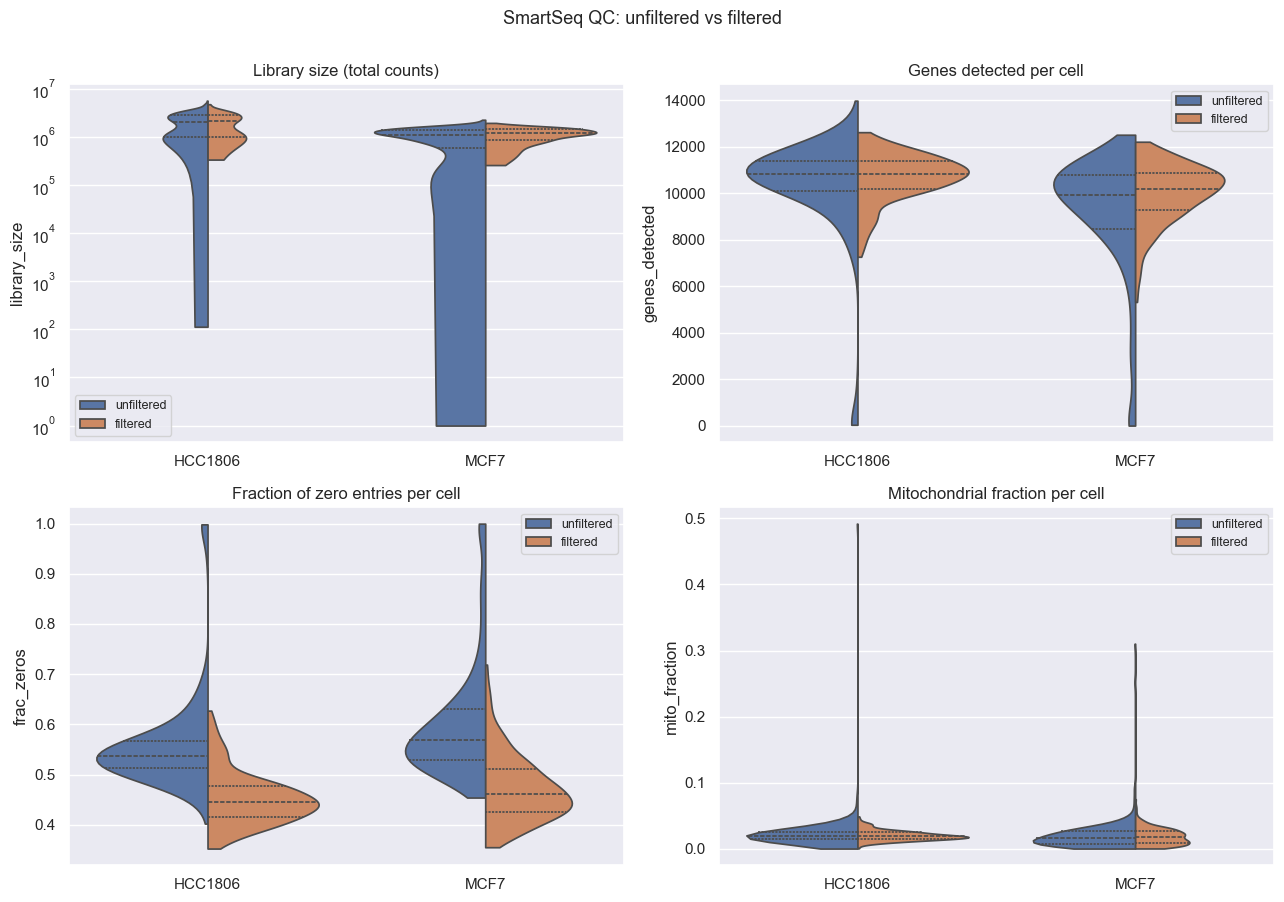

In [12]:
# Plot the main QC metrics before and after filtering.

def plot_qc_violin(ax, metric, title, log_y=False):
    sns.violinplot(
        data=qc_df,
        x="cell_line",
        y=metric,
        hue="status",
        split=True,
        inner="quart",
        cut=0,
        ax=ax,
        order=["HCC1806", "MCF7"],
        hue_order=["unfiltered", "filtered"],
    )

    if log_y:
        ax.set_yscale("log")

    ax.set_title(title)
    ax.set_xlabel("")
    
    ax.legend(title="", loc="best", fontsize=9)


fig, axes = plt.subplots(2, 2, figsize=(13, 9))

plot_qc_violin(
    axes[0, 0],
    metric="library_size",
    title="Library size (total counts)",
    log_y=True,
)

plot_qc_violin(
    axes[0, 1],
    metric="genes_detected",
    title="Genes detected per cell",
)

plot_qc_violin(
    axes[1, 0],
    metric="frac_zeros",
    title="Fraction of zero entries per cell",
)

plot_qc_violin(
    axes[1, 1],
    metric="mito_fraction",
    title="Mitochondrial fraction per cell",
)

fig.suptitle("SmartSeq QC: unfiltered vs filtered", y=1.00, fontsize=13)
fig.tight_layout()

plt.show()

The SmartSeq QC plots show that filtering removes the lowest-quality cells, especially those with very low library size, very low detected-gene counts, and high fractions of zero expression values. After filtering, both HCC1806 and MCF7 have more compact QC distributions, with fewer extreme low-depth or highly sparse cells. The mitochondrial fraction changes less strongly than the other metrics: most cells already have low mitochondrial fractions, although a few unfiltered cells show high mitochondrial outliers. This suggests that filtering is driven mainly by sequencing depth, gene detection, and sparsity rather than by mitochondrial content alone. These checks justify using the filtered/preprocessed matrices for downstream EDA, PCA, clustering, and supervised hypoxia classification.

## 5. Distributional EDA and analysis-ready data preparation

Section 4 examined the effect of filtering using the SmartSeq count matrices. This section now focuses on the four `Filtered_Normalised_3000_train` matrices used in downstream analysis.

We inspect their distributional scale, sparsity, duplicate features, and cross-dataset comparability before saving analysis-ready inputs. The comparison is restricted to the same preprocessing level across all datasets, so differences can be interpreted as dataset or technology effects rather than artefacts of mixing raw and processed matrices.

### 5.1 Distribution scale and log-transformation decision

Before downstream analysis, we check whether the `Filtered_Normalised_3000_train` matrices are already on a modelling-friendly scale or whether they still behave like count-scale expression data. The filename indicates that the matrices are normalised, but normalisation does not necessarily imply log-transformation or variance stabilisation.

We first compare basic value-distribution summaries across the four downstream training matrices, using the unfiltered MCF7 SmartSeq matrix as a raw-count reference. We then quantify per-cell skewness before and after applying `log2(x + 1)`. Strong positive skewness indicates that a small number of large expression values still dominate the scale, supporting log transformation before PCA, clustering, and supervised modelling.

dataset,genes,cells,% zero,mean,nonzero mean,nonzero median,max
MCF7_SmartSeq_unf,22934,383,60.220000,43.370000,109.010000,28.000000,190556
MCF7_SmartSeq_norm3k,3000,250,63.620000,115.900000,318.600000,66.000000,107556
HCC1806_SmartSeq_norm3k,3000,182,70.650000,167.530000,570.860000,103.000000,109881
MCF7_DropSeq_norm3k,3000,21626,97.530000,0.040000,1.450000,1.000000,175
HCC1806_DropSeq_norm3k,3000,14682,97.640000,0.040000,1.500000,1.000000,110


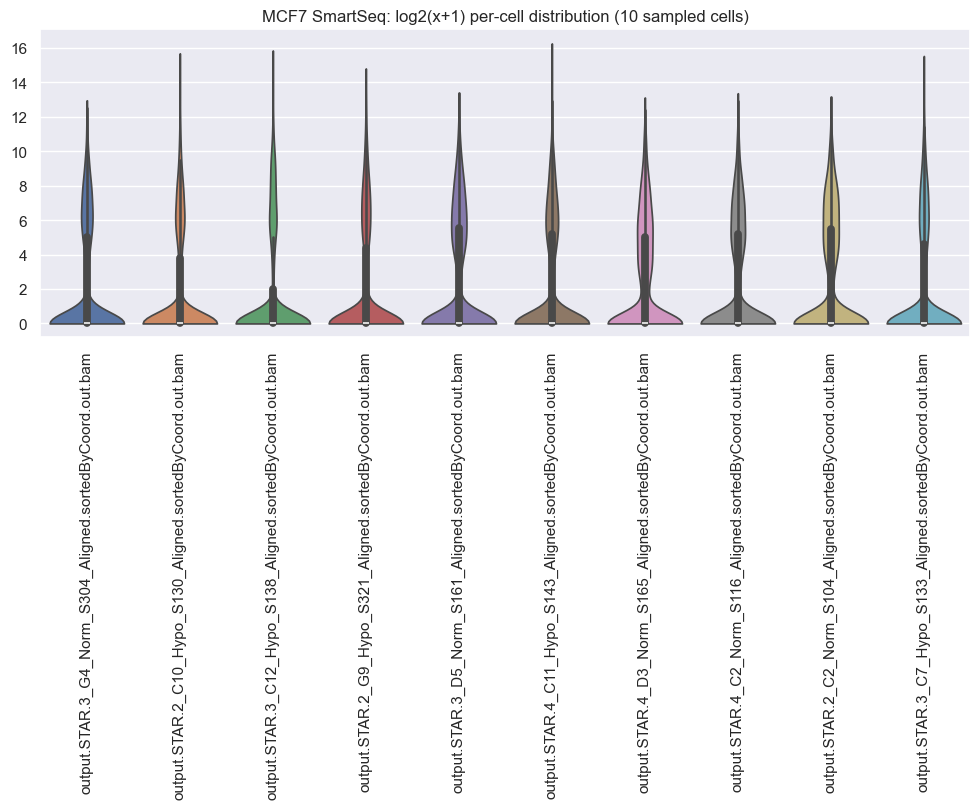

In [13]:
# Value-distribution summary for the four downstream matrices, plus the
# unfiltered MCF7 SmartSeq matrix as a raw-count reference.

inputs_for_dist = {
    "MCF7_SmartSeq_unf": ss_mcf_unf,
    **{f"{name}_norm3k": spec["matrix"] for name, spec in DATASETS.items()},
}

dist_summary = []
for name, X in inputs_for_dist.items():
    vals = X.to_numpy()
    nonzero_vals = vals[vals > 0]
    dist_summary.append({
        "dataset":        name,
        "genes":          X.shape[0],
        "cells":          X.shape[1],
        "% zero":         ((vals == 0).mean() * 100).round(2),
        "mean":           vals.mean().round(2),
        "nonzero mean":   nonzero_vals.mean().round(2),
        "nonzero median": np.median(nonzero_vals).round(0),
        "max":            vals.max().round(2),
    })

dist_summary_df = pd.DataFrame(dist_summary)
display(dist_summary_df.style.hide(axis="index"))

# log2(x+1) per-cell distribution for 10 sampled MCF7 SmartSeq cells.
sample = ss_mcf_train.sample(n=10, axis=1, random_state=42)

plt.figure(figsize=(12, 4))
sns.violinplot(data=np.log2(sample + 1), cut=0)
plt.xticks(rotation=90)
plt.title("MCF7 SmartSeq: log2(x+1) per-cell distribution (10 sampled cells)")
plt.show()


A standard IQR outlier rule is not appropriate here. In sparse single-cell expression data, high values are not necessarily errors. They might be rare but meaningful gene-expression signals. Removing them mechanically would risk deleting biological signal and pushing the matrix further toward zeros. We therefore avoid IQR-based outlier removal and instead evaluate whether a `log2(x + 1)` transformation would reduce skewness without distorting the observed expression values.

The transformation is used here as a diagnostic: the violin above is computed from `log2(x + 1)` on a 10-cell sample, and the table below quantifies per-cell skewness and kurtosis before and after `log2(x + 1)` for all four downstream matrices. The matrices themselves are kept on the file-provided normalised scale at handoff. Applying `log2(x + 1)` before PCA, clustering, and supervised modelling is the recommendation for the downstream sections, where the variance assumptions of those methods matter.

In [14]:
# Per-cell skewness and kurtosis, before and after log2(x + 1).

def _moment_row(name, X):
    vals = X.to_numpy(dtype=float)
    log_vals = np.log2(vals + 1)
    return {
        "Dataset": name,
        "Median skew before":     float(np.median(skew(vals, axis=0))),
        "Median skew after":      float(np.median(skew(log_vals, axis=0))),
        "Median kurtosis before": float(np.median(kurtosis(vals, axis=0, fisher=True))),
        "Median kurtosis after":  float(np.median(kurtosis(log_vals, axis=0, fisher=True))),
    }


moment_summary = pd.DataFrame([_moment_row(n, X) for n, X in downstream_inputs.items()])
moment_summary["Skew reduction"]     = moment_summary["Median skew before"]     - moment_summary["Median skew after"]
moment_summary["Kurtosis reduction"] = moment_summary["Median kurtosis before"] - moment_summary["Median kurtosis after"]

moment_summary = moment_summary[[
    "Dataset",
    "Median skew before", "Median skew after", "Skew reduction",
    "Median kurtosis before", "Median kurtosis after", "Kurtosis reduction",
]]

display(moment_summary.style.hide(axis="index").format({
    col: "{:.2f}" for col in moment_summary.columns if col != "Dataset"
}))


Dataset,Median skew before,Median skew after,Skew reduction,Median kurtosis before,Median kurtosis after,Kurtosis reduction
MCF7_SmartSeq,19.66,1.08,18.58,475.78,-0.23,476.00
HCC1806_SmartSeq,15.16,1.42,13.74,324.68,0.59,324.09
MCF7_DropSeq,11.84,7.83,4.02,186.10,69.59,116.51
HCC1806_DropSeq,11.66,7.97,3.69,177.43,70.81,106.62


The log transformation reduces both median per-cell skewness and kurtosis in all four matrices. This means that `log2(x + 1)` not only makes the expression distributions less asymmetric, but also reduces the influence of extreme high-expression values.

DropSeq remains more skewed and heavy-tailed than SmartSeq after transformation, which is expected given its much higher sparsity and stronger dropout behaviour. We therefore keep the common `log2(x + 1)` transformation for all downstream datasets rather than using technology-specific preprocessing. This keeps the analysis comparable across cell lines and sequencing technologies while reducing the dominance of extreme expression values.

### 5.2 Sparsity

Single-cell RNA-seq matrices contain many zero entries because genes are selectively expressed and because some transcripts are not captured. We quantify sparsity because it affects PCA stability, distance-based clustering, and classifier regularisation.

This comparison also captures a major technology difference. SmartSeq is full-length and deeper per cell, while DropSeq is droplet-based, 3′-tagged, and shallower. We therefore expect DropSeq to have substantially higher sparsity than SmartSeq.

dataset,genes,cells,percent_zero
MCF7_SmartSeq,3000,250,63.62
HCC1806_SmartSeq,3000,182,70.65
MCF7_DropSeq,3000,21626,97.53
HCC1806_DropSeq,3000,14682,97.64


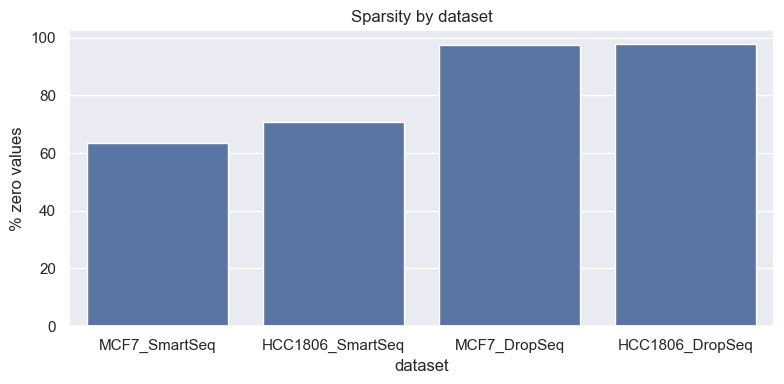

In [15]:
# Quantify zero inflation across the four downstream matrices.
sparsity_df = pd.DataFrame([
    {
        "dataset":      name,
        "genes":        X.shape[0],
        "cells":        X.shape[1],
        "percent_zero": (X == 0).values.mean() * 100,
    }
    for name, X in downstream_inputs.items()
])

display(sparsity_df.style.hide(axis="index").format({"percent_zero": "{:.2f}"}))

plt.figure(figsize=(8, 4))
sns.barplot(data=sparsity_df, x="dataset", y="percent_zero")
plt.ylabel("% zero values")
plt.title("Sparsity by dataset")
plt.tight_layout()
plt.show()


The sparsity comparison shows a clear technology effect. DropSeq matrices contain a much larger fraction of zero entries than SmartSeq, despite all four datasets having the same number of selected genes. This difference is expected from the shallower droplet-based protocol and should be considered when comparing PCA structure, clustering, and classifier performance across technologies.

### 5.3 Duplicate genes

We check for duplicate gene symbols and for rows with identical expression values across all cells. Duplicate features can bias downstream models if they repeat the same signal, but removing them without documentation can make later gene-level interpretation less transparent.

The check is therefore used for reproducibility rather than automatic filtering.

In [16]:
# Count duplicate gene symbols and identical expression rows.
dup_df = pd.DataFrame([
    {
        "matrix":            name,
        "n_genes":           X.shape[0],
        "duplicate_symbols": int(X.index.duplicated().sum()),
        "duplicate_rows":    int(X.duplicated().sum()),
    }
    for name, X in downstream_inputs.items()
])

print("Duplicate-gene summary:")
display(dup_df.style.hide(axis="index"))


Duplicate-gene summary:


matrix,n_genes,duplicate_symbols,duplicate_rows
MCF7_SmartSeq,3000,0,1
HCC1806_SmartSeq,3000,0,1
MCF7_DropSeq,3000,0,0
HCC1806_DropSeq,3000,0,0


No duplicate gene symbols are present in the downstream matrices. A single identical-expression row is detected in the SmartSeq datasets, while DropSeq has none. We do not drop them at this stage because only one pair was found per SmartSeq dataset and downstream feature handling can decide.

### 5.4 EDA synthesis: cross-dataset comparison

This table consolidates the main EDA findings from the previous sections into one cross-dataset view. It is not a separate preprocessing step, but a summary used to guide downstream modelling.

The key pattern is technological: DropSeq has many more cells but much higher sparsity, while SmartSeq has fewer cells but deeper per-cell coverage. This means that PCA, clustering, and classifier performance should not be interpreted only as biological differences between MCF7 and HCC1806. They might also reflect technology-driven differences in sparsity, library size, and sample size.

In [17]:
# Summarise dataset size, label balance, sparsity, and library size.
label_counts = (
    labels
    .groupby(["dataset", "condition"])
    .size()
    .unstack(fill_value=0)
)

summary_df = pd.DataFrame([
    {
        "dataset":             name,
        "genes":               X.shape[0],
        "cells":               X.shape[1],
        "hypoxia":             int(label_counts.loc[name, "Hypoxia"]),
        "normoxia":            int(label_counts.loc[name, "Normoxia"]),
        "percent_zero":        (X == 0).values.mean() * 100,
        "median_library_size": int(X.sum(axis=0).median()),
    }
    for name, X in downstream_inputs.items()
])

print("Cross-dataset summary table:")
display(summary_df.style.hide(axis="index").format({"percent_zero": "{:.2f}"}))


Cross-dataset summary table:


dataset,genes,cells,hypoxia,normoxia,percent_zero,median_library_size
MCF7_SmartSeq,3000,250,124,126,63.62,330296
HCC1806_SmartSeq,3000,182,97,85,70.65,497586
MCF7_DropSeq,3000,21626,8921,12705,97.53,100
HCC1806_DropSeq,3000,14682,8899,5783,97.64,102


The cross-dataset summary confirms that the analysis-ready matrices have the same feature dimension: 3,000 selected genes. However, they differ substantially in the number of cells, class balance, sparsity, and per-cell expression depth.

The strongest difference is technological. DropSeq contains far more cells than SmartSeq, but the measurements are much sparser, with about 97.5% zero entries. SmartSeq contains fewer cells, but has lower sparsity and much larger median library sizes, indicating deeper per-cell coverage.

These differences are important for downstream interpretation. Differences in PCA structure, clustering behaviour, or classifier performance may reflect not only biological differences between MCF7 and HCC1806, but also technology-driven effects from SmartSeq versus DropSeq and differences in class balance. Therefore, later model comparisons should be interpreted as cross-dataset comparisons rather than purely biological comparisons.

### 5.5 Section summary

The four downstream matrices are aligned in gene dimension but differ substantially in cell count, class balance, sparsity, and expression scale. All contain 3000 selected genes, but DropSeq provides many more cells than SmartSeq and is much sparser. This technology difference should be carried into the interpretation of any downstream PCA, clustering, and classifier results.

Although the matrices are labelled as normalised, their distributions remain count-like, with zero-heavy values and strong positive skewness. The diagnostic in §5.1 showed that `log2(x + 1)` substantially reduces per-cell skewness and kurtosis, especially on SmartSeq. We therefore recommend applying `log2(x + 1)` in the downstream sections before PCA, clustering, and supervised modelling. At this stage the matrices are left on the file-provided normalised scale in genes × cells orientation, so that the downstream sections can choose the transformation and orientation that suit their methods.

Duplicate gene symbols are absent. A small number of identical-expression rows occur in the SmartSeq matrices, but they are rare, so we record them without modifying the lecturer-provided 3000-gene feature sets.

## 6. Dimensionality reduction, per dataset

The dimensionality-reduction workflow keeps the four training datasets separate. This avoids accidental mixing across cell line or sequencing technology and preserves each dataset's own 3,000-gene feature space.


Methodology and rationale. Sections 6.x are exploratory and dataset-specific: each training matrix is transformed independently, PCA is used as the main denoising baseline, and UMAP is used only for qualitative visualization on PCA scores. The component grid uses powers of two because these values give broad scale coverage without an expensive fine-grained search. Figures comparing all four datasets use a 2x2 layout so differences across cell line and technology are visible without pooling incompatible matrices.


### 6.1 Dataset-specific preprocessing for DR

We prepare each dataset independently by transposing from genes x cells to cells x genes, applying the same `log2(x + 1)` transformation recommended in Section 5, and aligning metadata to the resulting cell index. The output objects are deliberately named per dataset so later PCA and prediction cells cannot pool them accidentally.


In [18]:
dr_source_matrices = {
    "MCF7_SmartSeq": ss_mcf_train,
    "HCC1806_SmartSeq": ss_hcc_train,
    "MCF7_DropSeq": ds_mcf_train,
    "HCC1806_DropSeq": ds_hcc_train,
}


In [19]:
def make_dr_ready_matrix(dataset_name, genes_by_cells, labels_df, log_transform=True):
    X = genes_by_cells.T.copy()
    X.index = X.index.astype(str)
    X.index.name = "cell_id"
    X.columns = pd.Index(genes_by_cells.index.astype(str)).str.strip().str.strip('"').str.strip("'")

    assert X.shape[1] == 3000, f"{dataset_name}: expected 3000 genes, got {X.shape[1]}"
    assert X.columns.is_unique, f"{dataset_name}: duplicate gene labels"
    assert all(pd.api.types.is_numeric_dtype(X[col]) for col in X.columns), f"{dataset_name}: non-numeric expression columns"

    if log_transform:
        X = np.log2(X + 1)

    meta = (
        labels_df.assign(cell_id=labels_df["cell_id"].astype(str))
        .query("dataset == @dataset_name")
        .set_index("cell_id")[["dataset", "cell_line", "technology", "condition"]]
        .reindex(X.index)
    )

    assert X.index.equals(meta.index), f"{dataset_name}: metadata index mismatch"
    assert meta["condition"].notna().all(), f"{dataset_name}: missing condition labels"
    return X, meta


In [20]:
dr_tables = {}
dr_meta = {}

for dataset_name, matrix in dr_source_matrices.items():
    X_dr, meta_dr = make_dr_ready_matrix(dataset_name, matrix, labels)
    dr_tables[dataset_name] = X_dr
    dr_meta[dataset_name] = meta_dr

X_mcf7_smartseq_dr = dr_tables["MCF7_SmartSeq"]
X_hcc1806_smartseq_dr = dr_tables["HCC1806_SmartSeq"]
X_mcf7_dropseq_dr = dr_tables["MCF7_DropSeq"]
X_hcc1806_dropseq_dr = dr_tables["HCC1806_DropSeq"]

print("DR-ready matrices:")
for dataset_name, X in dr_tables.items():
    print(f"{dataset_name:<16}: {X.shape[0]} cells x {X.shape[1]} genes")


DR-ready matrices:
MCF7_SmartSeq   : 250 cells x 3000 genes
HCC1806_SmartSeq: 182 cells x 3000 genes
MCF7_DropSeq    : 21626 cells x 3000 genes
HCC1806_DropSeq : 14682 cells x 3000 genes


### 6.2 Baseline PCA on each dataset

We fit PCA independently for each dataset after within-dataset standardisation. The component search now uses powers of two (`32, 64, 128, 256, 512, 1024`) where each value is feasible for the dataset size. PCA itself is fit once per dataset up to the largest feasible value in that grid, so later cells can slice the fitted scores instead of refitting repeatedly. The scree diagnostics include raw explained variance, cumulative variance with 80% and 90% thresholds, a threshold-focused zoom, and a log-scaled scree chart to make the long tail of components easier to inspect.


In [21]:
DATASET_ORDER = [
    "MCF7_SmartSeq",
    "HCC1806_SmartSeq",
    "MCF7_DropSeq",
    "HCC1806_DropSeq",
]

DATASET_TITLES = {
    "MCF7_SmartSeq": "MCF7 SmartSeq",
    "HCC1806_SmartSeq": "HCC1806 SmartSeq",
    "MCF7_DropSeq": "MCF7 DropSeq",
    "HCC1806_DropSeq": "HCC1806 DropSeq",
}

DR_COMPONENT_GRID = [32, 64, 128, 256, 512, 1024]
PCA_VARIANCE_THRESHOLDS = [0.80, 0.90]


In [22]:
def standardize_matrix_for_pca(X):
    assert isinstance(X, pd.DataFrame), "X must be a pandas DataFrame"
    assert X.shape[0] > 1 and X.shape[1] > 1, "X must have at least two cells and two genes"
    assert X.index.is_unique, "cell index must be unique before PCA"
    assert X.columns.is_unique, "gene columns must be unique before PCA"
    assert np.isfinite(X.to_numpy(dtype=np.float32, copy=False)).all(), "X contains NaN or infinite values"

    values = X.to_numpy(dtype=np.float32, copy=True)
    means = values.mean(axis=0)
    stds = values.std(axis=0)
    stds[stds == 0] = 1.0
    values -= means
    values /= stds

    assert values.shape == X.shape, "standardized matrix shape changed unexpectedly"
    assert np.isfinite(values).all(), "standardization produced NaN or infinite values"
    return values, pd.DataFrame({"mean": means, "std": stds}, index=X.columns)


def feasible_component_grid(X, requested_grid=DR_COMPONENT_GRID):
    assert isinstance(X, pd.DataFrame), "X must be a pandas DataFrame"
    assert all(isinstance(k, int) and k > 0 for k in requested_grid), "component grid must contain positive integers"
    max_valid = min(X.shape[0] - 1, X.shape[1])
    assert max_valid >= 1, "at least one component must be feasible"
    return [k for k in requested_grid if k <= max_valid]


In [23]:
pca_models = {}
pca_scores = {}
pca_variance = {}
pca_scalers = {}
pca_fit_components = {}
pca_threshold_summary = []

for dataset_name in DATASET_ORDER:
    X = dr_tables[dataset_name]
    grid = feasible_component_grid(X)
    n_components = max(grid) if grid else min(X.shape[0] - 1, X.shape[1])
    X_scaled, scaler_stats = standardize_matrix_for_pca(X)

    pca = PCA(
        n_components=n_components,
        svd_solver="randomized",
        iterated_power=3,
        random_state=42,
    )
    scores = pca.fit_transform(X_scaled)

    pca_models[dataset_name] = pca
    pca_scalers[dataset_name] = scaler_stats
    pca_fit_components[dataset_name] = n_components
    pca_scores[dataset_name] = pd.DataFrame(
        scores,
        index=X.index,
        columns=[f"PC{i}" for i in range(1, n_components + 1)],
    )
    pca_variance[dataset_name] = pd.DataFrame({
        "component": np.arange(1, n_components + 1),
        "explained_variance_ratio": pca.explained_variance_ratio_,
        "cumulative_variance": np.cumsum(pca.explained_variance_ratio_),
    })

    row = {"dataset": dataset_name, "fitted_components": n_components, "candidate_grid": grid}
    for threshold in PCA_VARIANCE_THRESHOLDS:
        reached = pca_variance[dataset_name].loc[
            pca_variance[dataset_name]["cumulative_variance"] >= threshold,
            "component",
        ]
        row[f"components_for_{int(threshold * 100)}pct"] = int(reached.iloc[0]) if len(reached) else np.nan
    pca_threshold_summary.append(row)

pca_threshold_summary = pd.DataFrame(pca_threshold_summary)
display(pca_threshold_summary.style.hide(axis="index"))


dataset,fitted_components,candidate_grid,components_for_80pct,components_for_90pct
MCF7_SmartSeq,128,"[32, 64, 128]",nan,nan
HCC1806_SmartSeq,128,"[32, 64, 128]",118.000000,nan
MCF7_DropSeq,1024,"[32, 64, 128, 256, 512, 1024]",nan,nan
HCC1806_DropSeq,1024,"[32, 64, 128, 256, 512, 1024]",nan,nan


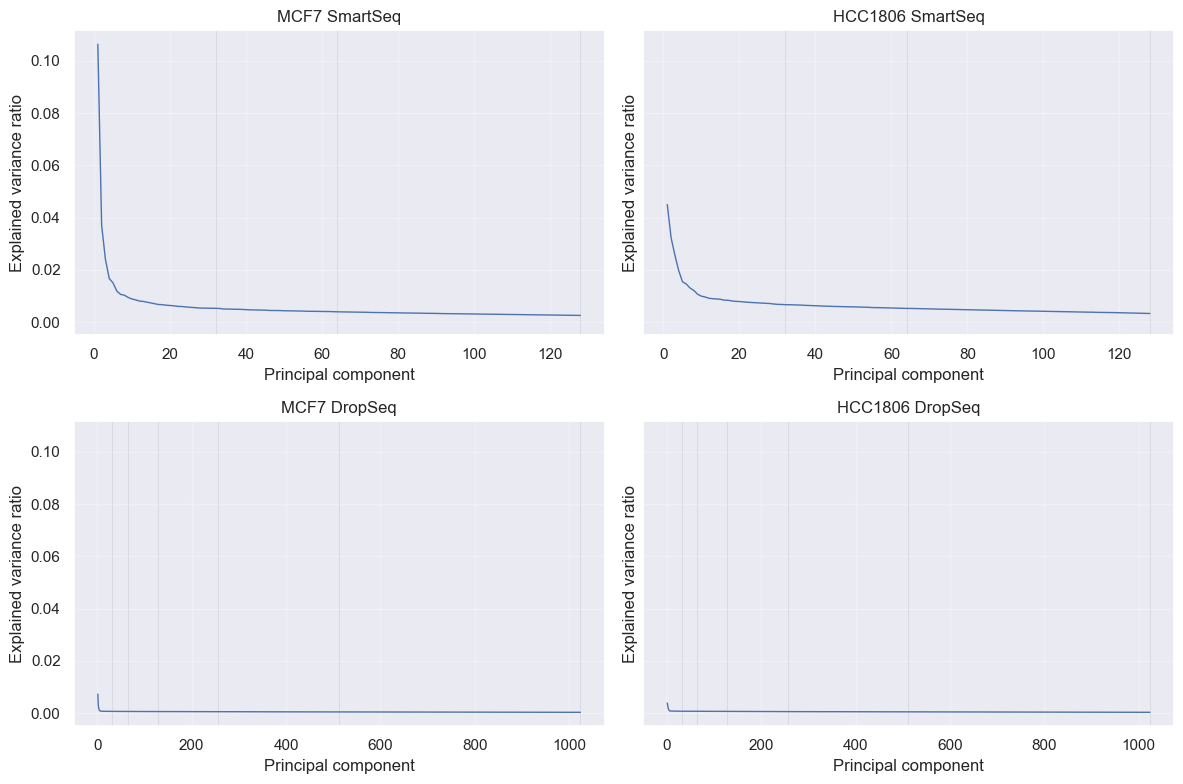

In [24]:
# Raw scree plot across all fitted components.
fig, axes = plt.subplots(2, 2, figsize=(12, 8), sharex=False, sharey=True)
for ax, dataset_name in zip(axes.ravel(), DATASET_ORDER):
    variance = pca_variance[dataset_name]
    ax.plot(variance["component"], variance["explained_variance_ratio"], linewidth=1)
    for k in feasible_component_grid(dr_tables[dataset_name]):
        ax.axvline(k, color="grey", alpha=0.15, linewidth=0.8)
    ax.set_title(DATASET_TITLES[dataset_name])
    ax.set_xlabel("Principal component")
    ax.set_ylabel("Explained variance ratio")
    ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()


The raw scree plots show how quickly each dataset's PCA variance decays. A steep early drop means a small number of components capture the dominant expression patterns; a long flat tail means information is spread across many weak axes. For this project, a flat tail is expected because single-cell RNA-seq data are sparse and noisy. The practical conclusion is that low individual PC variance does not make PCA useless, but it warns against relying only on PC1/PC2 visual separation.

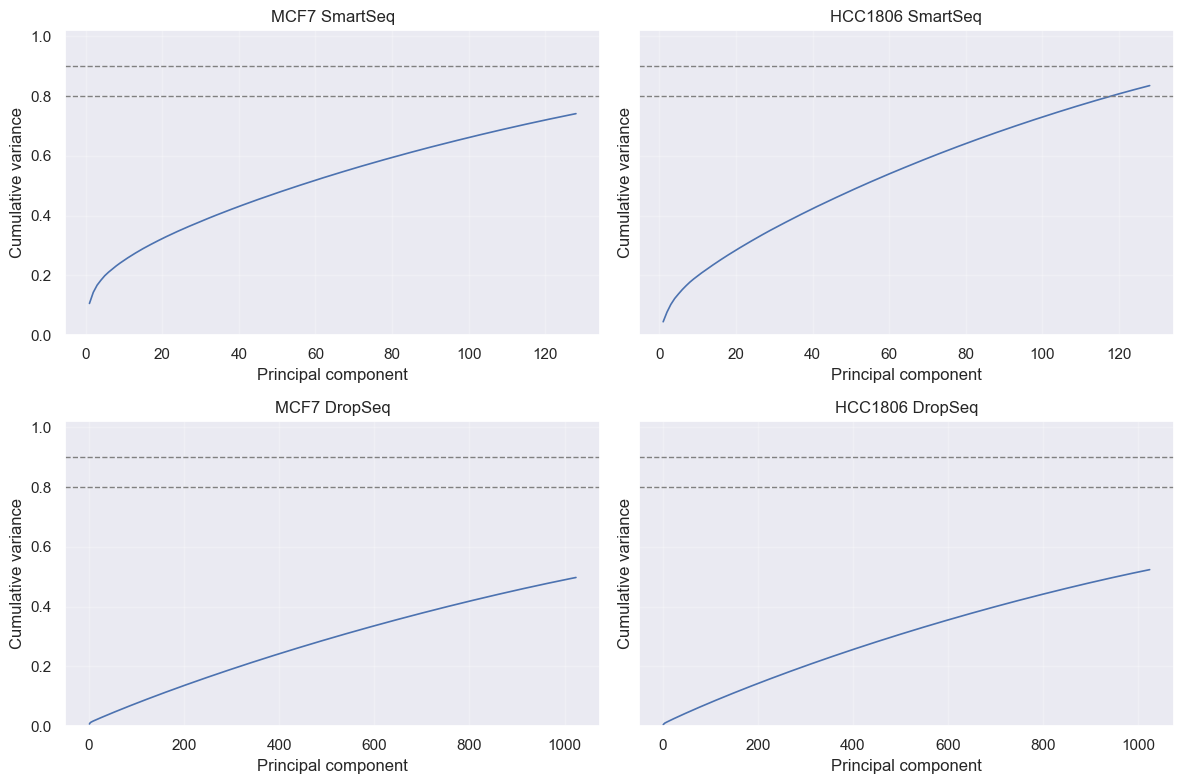

In [25]:
# Cumulative variance over all fitted components.
fig, axes = plt.subplots(2, 2, figsize=(12, 8), sharex=False, sharey=True)
for ax, dataset_name in zip(axes.ravel(), DATASET_ORDER):
    variance = pca_variance[dataset_name]
    ax.plot(variance["component"], variance["cumulative_variance"], linewidth=1.2)
    for threshold in PCA_VARIANCE_THRESHOLDS:
        ax.axhline(threshold, color="grey", linestyle="--", linewidth=1)
    ax.set_title(DATASET_TITLES[dataset_name])
    ax.set_xlabel("Principal component")
    ax.set_ylabel("Cumulative variance")
    ax.set_ylim(0, 1.02)
    ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()


The cumulative-variance plots answer whether the selected component grid reaches conventional reconstruction thresholds such as 80% or 90%. If a dataset does not reach those thresholds even at high component counts, variance is distributed broadly across many genes and cells. The conclusion is methodological: downstream component choices should be judged by classifier performance and stability, not by forcing every dataset to hit an arbitrary reconstruction threshold.

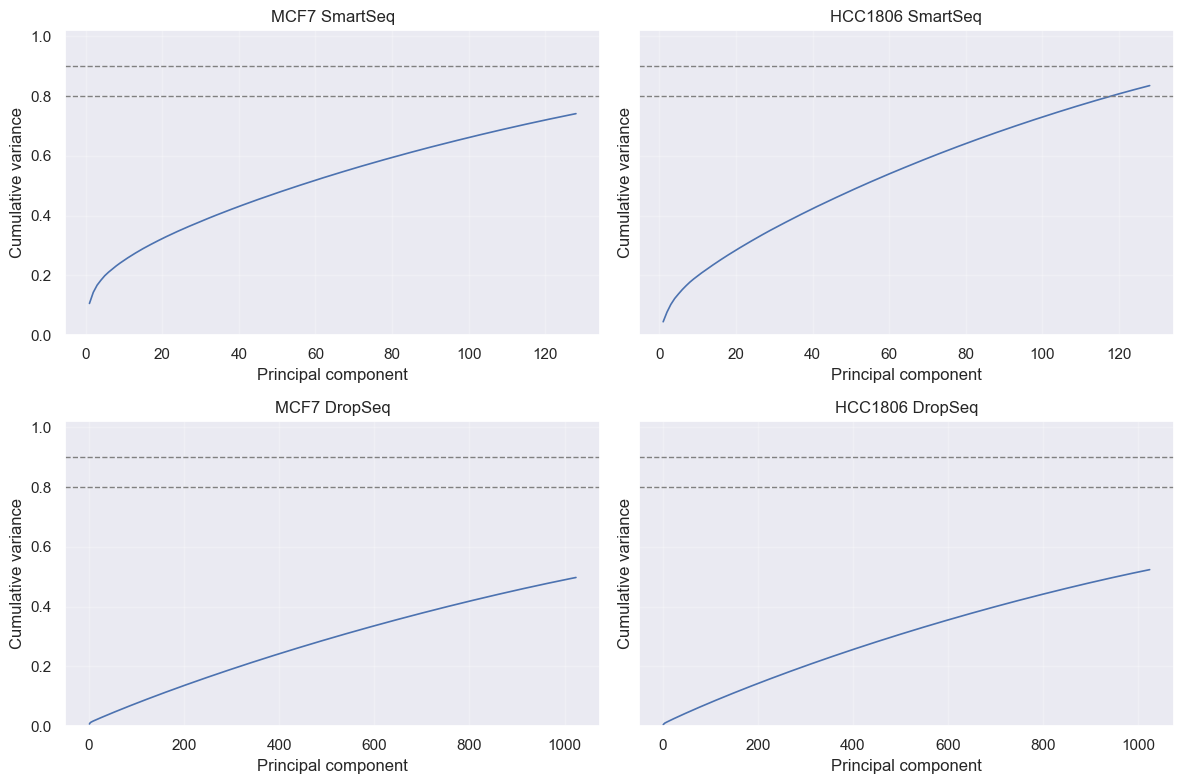

In [26]:
# Threshold-focused cumulative plot: show components until 90% is reached, or all fitted components if not reached.
fig, axes = plt.subplots(2, 2, figsize=(12, 8), sharex=False, sharey=True)
for ax, dataset_name in zip(axes.ravel(), DATASET_ORDER):
    variance = pca_variance[dataset_name]
    reached_90 = variance.loc[variance["cumulative_variance"] >= 0.90, "component"]
    x_max = int(reached_90.iloc[0] * 1.10) if len(reached_90) else int(variance["component"].max())
    x_max = min(x_max, int(variance["component"].max()))
    plot_df = variance.query("component <= @x_max")
    ax.plot(plot_df["component"], plot_df["cumulative_variance"], linewidth=1.2)
    for threshold in PCA_VARIANCE_THRESHOLDS:
        ax.axhline(threshold, color="grey", linestyle="--", linewidth=1)
    ax.set_title(DATASET_TITLES[dataset_name])
    ax.set_xlabel("Principal component")
    ax.set_ylabel("Cumulative variance")
    ax.set_ylim(0, 1.02)
    ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()


The threshold-focused cumulative plot makes the 80% and 90% targets easier to inspect. If the curve approaches a threshold slowly, then adding more components gives diminishing but still nonzero reconstruction value. This supports the power-of-two grid strategy: it is more useful to test broad scales such as 64, 128, 256, and 512 than to overinterpret a single exact component count from a noisy curve.

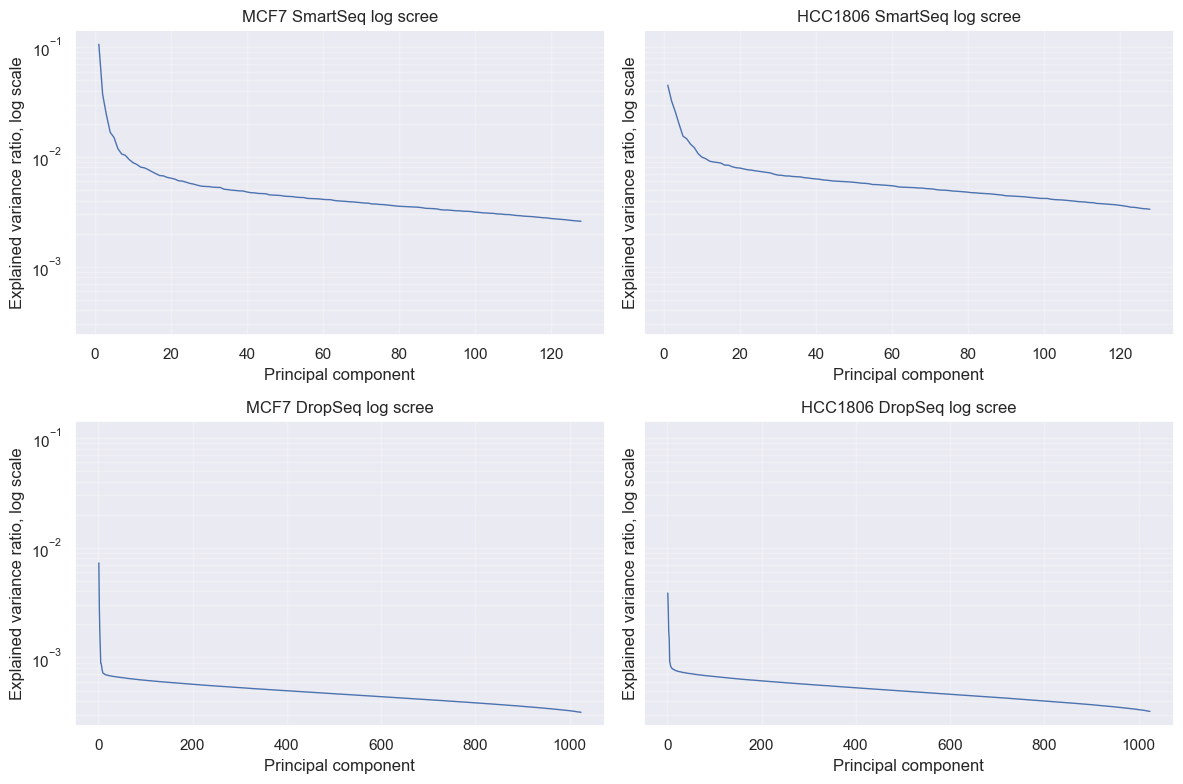

In [27]:
# Log-scale scree plot for the long tail of explained variance.
fig, axes = plt.subplots(2, 2, figsize=(12, 8), sharex=False, sharey=True)
for ax, dataset_name in zip(axes.ravel(), DATASET_ORDER):
    variance = pca_variance[dataset_name]
    ax.plot(variance["component"], variance["explained_variance_ratio"], linewidth=1)
    ax.set_yscale("log")
    ax.set_title(f"{DATASET_TITLES[dataset_name]} log scree")
    ax.set_xlabel("Principal component")
    ax.set_ylabel("Explained variance ratio, log scale")
    ax.grid(alpha=0.25, which="both")
plt.tight_layout()
plt.show()


The log-scale scree plot exposes the small but persistent variance carried by later PCs. On a linear scale this tail can look almost flat, but on a log scale it shows whether later components still contain structured signal rather than pure numerical residue. The cautious conclusion is that later PCs may still help supervised classification, especially if condition-related information is not aligned with the first few high-variance axes.

### 6.3 PCA visualizations in 2D and 3D

The leading PCA coordinates provide the first qualitative check of hypoxia/normoxia structure. These plots are not used as performance estimates; they show whether the strongest variance axes already separate labels or whether label information may live in higher-order components. The full coordinate tables are kept for downstream reuse, while large DropSeq panels are downsampled only for plotting so the notebook remains readable.


In [28]:
CONDITION_COLORS = {
    "Normoxia": "#2f6f9f",
    "Hypoxia": "#c44e52",
}


def attach_pca_metadata(dataset_name, n_components):
    assert dataset_name in pca_scores, f"Missing PCA scores for {dataset_name}"
    assert dataset_name in dr_meta, f"Missing metadata for {dataset_name}"
    assert isinstance(n_components, int) and n_components >= 2, "n_components must be an integer >= 2"
    coord_cols = [f"PC{i}" for i in range(1, n_components + 1)]
    missing_cols = [c for c in coord_cols if c not in pca_scores[dataset_name].columns]
    assert not missing_cols, f"Missing PCA columns for {dataset_name}: {missing_cols}"
    coords = pca_scores[dataset_name][coord_cols].copy()
    joined = coords.join(dr_meta[dataset_name])
    assert joined.index.equals(pca_scores[dataset_name].index), f"Metadata join changed row order for {dataset_name}"
    assert joined["condition"].notna().all(), f"Missing condition labels in PCA coordinates for {dataset_name}"
    return joined


def sample_for_plot(df, max_points=8000):
    assert isinstance(df, pd.DataFrame), "plot input must be a DataFrame"
    assert isinstance(max_points, int) and max_points > 0, "max_points must be a positive integer"
    if len(df) <= max_points:
        return df
    return df.sample(max_points, random_state=42)


In [29]:
pca_2d_coords = {dataset_name: attach_pca_metadata(dataset_name, 2) for dataset_name in DATASET_ORDER}
pca_3d_coords = {dataset_name: attach_pca_metadata(dataset_name, 3) for dataset_name in DATASET_ORDER}


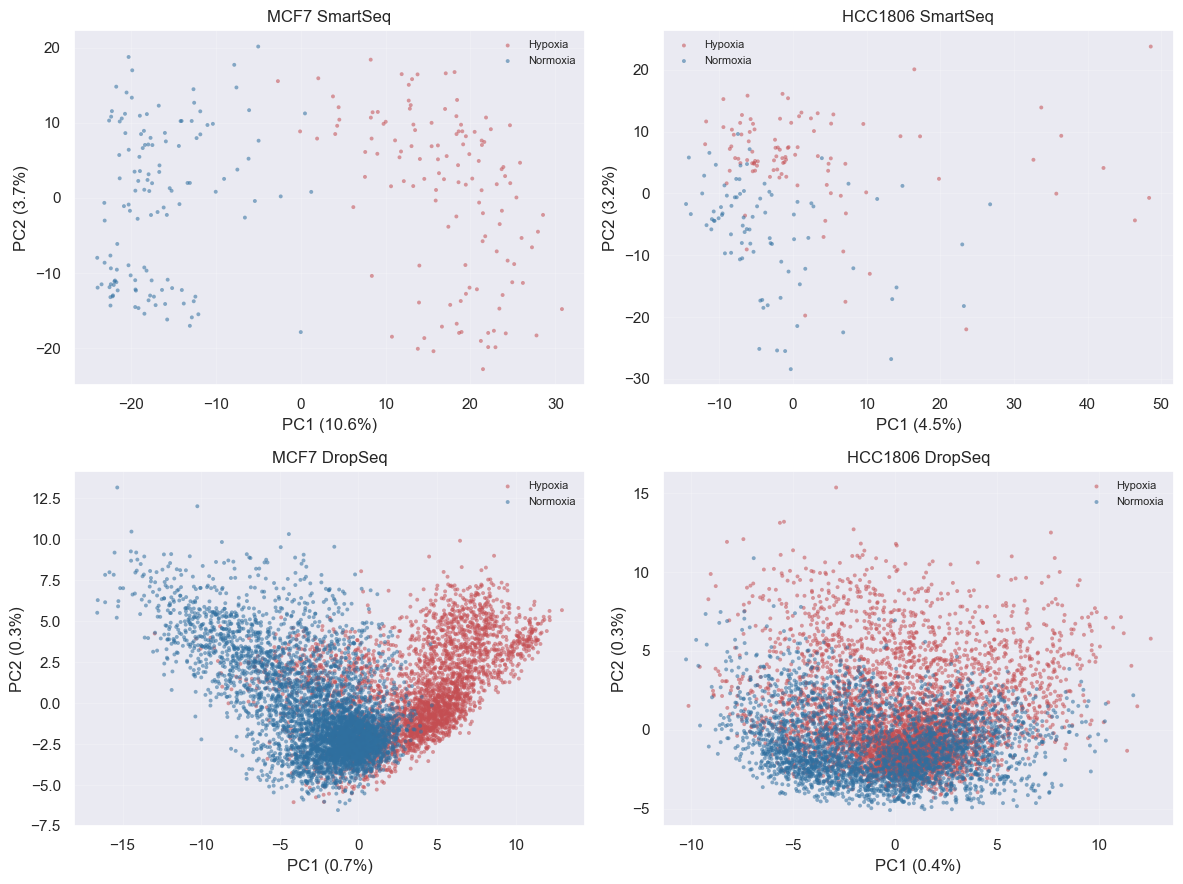

In [30]:
fig, axes = plt.subplots(2, 2, figsize=(12, 9))
for ax, dataset_name in zip(axes.ravel(), DATASET_ORDER):
    plot_df = sample_for_plot(pca_2d_coords[dataset_name])
    for condition, group in plot_df.groupby("condition"):
        ax.scatter(
            group["PC1"],
            group["PC2"],
            s=8,
            alpha=0.55,
            label=condition,
            color=CONDITION_COLORS.get(condition),
            edgecolors="none",
        )
    var = pca_variance[dataset_name]["explained_variance_ratio"]
    ax.set_title(DATASET_TITLES[dataset_name])
    ax.set_xlabel(f"PC1 ({var.iloc[0] * 100:.1f}%)")
    ax.set_ylabel(f"PC2 ({var.iloc[1] * 100:.1f}%)")
    ax.grid(alpha=0.2)
    ax.legend(frameon=False, fontsize=8)

plt.tight_layout()
plt.show()


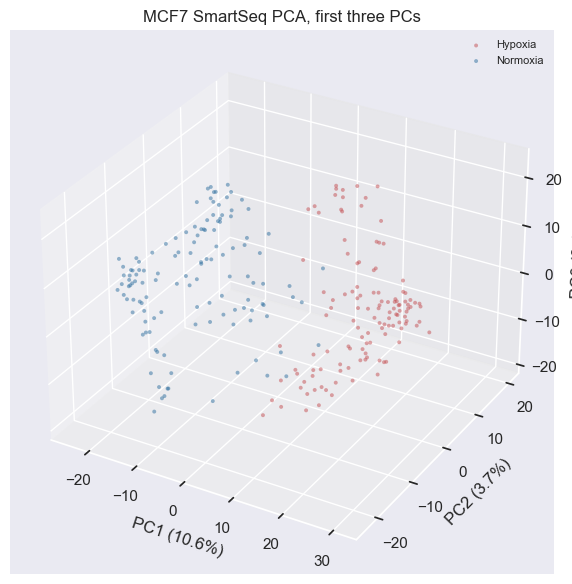

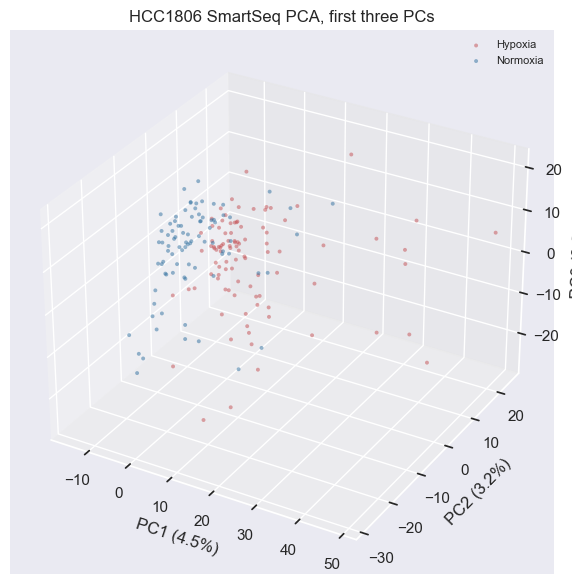

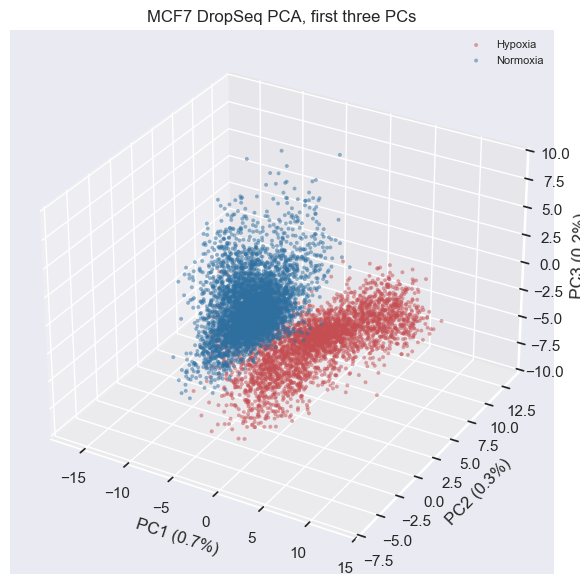

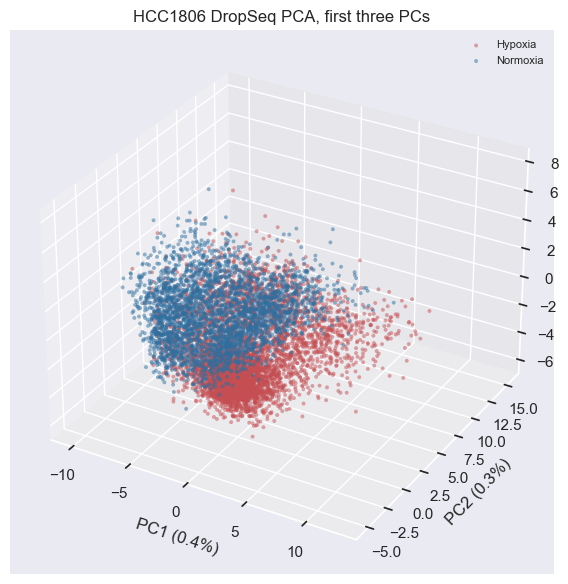

In [31]:
for dataset_name in DATASET_ORDER:
    plot_df = sample_for_plot(pca_3d_coords[dataset_name])
    var = pca_variance[dataset_name]["explained_variance_ratio"]

    fig = plt.figure(figsize=(8, 6))
    ax = fig.add_subplot(111, projection="3d")
    for condition, group in plot_df.groupby("condition"):
        ax.scatter(
            group["PC1"],
            group["PC2"],
            group["PC3"],
            s=8,
            alpha=0.5,
            label=condition,
            color=CONDITION_COLORS.get(condition),
            edgecolors="none",
        )
    ax.set_title(f"{DATASET_TITLES[dataset_name]} PCA, first three PCs")
    ax.set_xlabel(f"PC1 ({var.iloc[0] * 100:.1f}%)")
    ax.set_ylabel(f"PC2 ({var.iloc[1] * 100:.1f}%)")
    ax.set_zlabel(f"PC3 ({var.iloc[2] * 100:.1f}%)")
    ax.legend(frameon=False, fontsize=8)
    plt.tight_layout()
    plt.show()


The PCA scatter plots above should be read as a low-dimensional diagnostic, not as a final statement about separability. The first two or three PCs often explain only a small fraction of total expression variance, so overlap in these views does not prove that hypoxia/normoxia is impossible to classify. The practical reading is: clear separation in PC1/PC2 would be strong evidence that the condition dominates the largest variance axes, while mixed colors mean the signal is either weaker, distributed across many PCs, nonlinear, or better captured by supervised projections such as PLS-DA.

The preliminary pattern is that MCF7 appears to show cleaner condition-related separation than HCC1806, while technology-specific differences remain visible when comparing SmartSeq and DropSeq. That is biologically and technically plausible: cell line can change the transcriptional response to hypoxia, and sequencing technology changes sparsity/noise. The main conclusion is therefore cautious: PCA gives useful structure checks, but it should not be used alone to decide whether dimensionality reduction helps prediction.


### 6.4 UMAP on PCA scores

UMAP is used only as a visualization layer on PCA scores, not on the original 3,000-gene matrices. The input is the first 32 PCs where available, matching the smallest value in the high-range component grid. This keeps PCA as the denoising step and makes UMAP more tractable. The embeddings are qualitative views of local structure and should later be compared with supervised model results rather than treated as proof of predictive performance.


In [32]:
umap_grid = [
    {"n_neighbors": 10, "min_dist": 0.01},
    {"n_neighbors": 15, "min_dist": 0.01},
    {"n_neighbors": 30, "min_dist": 0.10},
]
default_umap_params = {"n_neighbors": 15, "min_dist": 0.01}
max_umap_fit_cells = 5000
umap_max_large_dataset_settings = 1

umap_input_components = {
    dataset_name: min(32, pca_scores[dataset_name].shape[1])
    for dataset_name in DATASET_ORDER
}

umap_embeddings = {}
umap_status = []


In [33]:
def stratified_cell_sample(meta, max_cells, random_state=42):
    assert "condition" in meta.columns, "metadata must contain condition for stratified sampling"
    assert max_cells > 0, "max_cells must be positive"
    if len(meta) <= max_cells:
        return meta.index

    rng = np.random.default_rng(random_state)
    sampled = []
    per_class = max_cells // meta["condition"].nunique()

    for _, idx in meta.groupby("condition").groups.items():
        idx = pd.Index(idx)
        n_take = min(len(idx), per_class)
        sampled.extend(rng.choice(idx.to_numpy(), size=n_take, replace=False).tolist())

    remaining = max_cells - len(sampled)
    if remaining > 0:
        unused = meta.index.difference(pd.Index(sampled))
        sampled.extend(rng.choice(unused.to_numpy(), size=min(remaining, len(unused)), replace=False).tolist())

    return pd.Index(sampled)


In [34]:
if umap is None:
    print("UMAP is not installed. Install `umap-learn` to run Section 6.4.")
else:
    for dataset_name in DATASET_ORDER:
        assert dataset_name in pca_scores, f"Missing PCA scores for {dataset_name}"
        assert dataset_name in dr_meta, f"Missing metadata for {dataset_name}"

        settings_to_run = umap_grid
        if len(pca_scores[dataset_name]) > max_umap_fit_cells:
            settings_to_run = [default_umap_params]

        skipped_settings = [p for p in umap_grid if p not in settings_to_run]
        for params in skipped_settings:
            umap_status.append({
                "dataset": dataset_name,
                "n_neighbors": params["n_neighbors"],
                "min_dist": params["min_dist"],
                "status": "skipped",
                "n_cells_embedded": 0,
                "details": f"Skipped for large dataset; only {umap_max_large_dataset_settings} default UMAP setting is run",
            })

        sample_index = stratified_cell_sample(dr_meta[dataset_name], max_umap_fit_cells)
        X_pca = pca_scores[dataset_name].loc[sample_index].iloc[:, :umap_input_components[dataset_name]]
        assert X_pca.shape[1] >= 2, f"{dataset_name}: UMAP needs at least two PCA input dimensions"
        assert X_pca.index.equals(dr_meta[dataset_name].loc[sample_index].index), f"{dataset_name}: UMAP sample metadata mismatch"

        for params in settings_to_run:
            key = (dataset_name, params["n_neighbors"], params["min_dist"])
            reducer = umap.UMAP(
                n_components=2,
                metric="euclidean",
                n_epochs=150,
                low_memory=True,
                random_state=42,
                **params,
            )
            embedding = reducer.fit_transform(X_pca)
            assert embedding.shape == (len(X_pca), 2), f"{dataset_name}: unexpected UMAP embedding shape"

            umap_embeddings[key] = pd.DataFrame(
                embedding,
                index=X_pca.index,
                columns=["UMAP1", "UMAP2"],
            ).join(dr_meta[dataset_name].loc[X_pca.index])
            umap_status.append({
                "dataset": dataset_name,
                "n_neighbors": params["n_neighbors"],
                "min_dist": params["min_dist"],
                "status": "stored",
                "n_cells_embedded": len(X_pca),
                "details": f"UMAP fitted on stratified sample of at most {max_umap_fit_cells} cells using {umap_input_components[dataset_name]} PCs",
            })

    umap_status_df = pd.DataFrame(umap_status)
    display(umap_status_df.style.hide(axis="index"))


dataset,n_neighbors,min_dist,status,n_cells_embedded,details
MCF7_SmartSeq,10,0.010000,stored,250,UMAP fitted on stratified sample of at most 5000 cells using 32 PCs
MCF7_SmartSeq,15,0.010000,stored,250,UMAP fitted on stratified sample of at most 5000 cells using 32 PCs
MCF7_SmartSeq,30,0.100000,stored,250,UMAP fitted on stratified sample of at most 5000 cells using 32 PCs
HCC1806_SmartSeq,10,0.010000,stored,182,UMAP fitted on stratified sample of at most 5000 cells using 32 PCs
HCC1806_SmartSeq,15,0.010000,stored,182,UMAP fitted on stratified sample of at most 5000 cells using 32 PCs
HCC1806_SmartSeq,30,0.100000,stored,182,UMAP fitted on stratified sample of at most 5000 cells using 32 PCs
MCF7_DropSeq,10,0.010000,skipped,0,Skipped for large dataset; only 1 default UMAP setting is run
MCF7_DropSeq,30,0.100000,skipped,0,Skipped for large dataset; only 1 default UMAP setting is run
MCF7_DropSeq,15,0.010000,stored,5000,UMAP fitted on stratified sample of at most 5000 cells using 32 PCs
HCC1806_DropSeq,10,0.010000,skipped,0,Skipped for large dataset; only 1 default UMAP setting is run


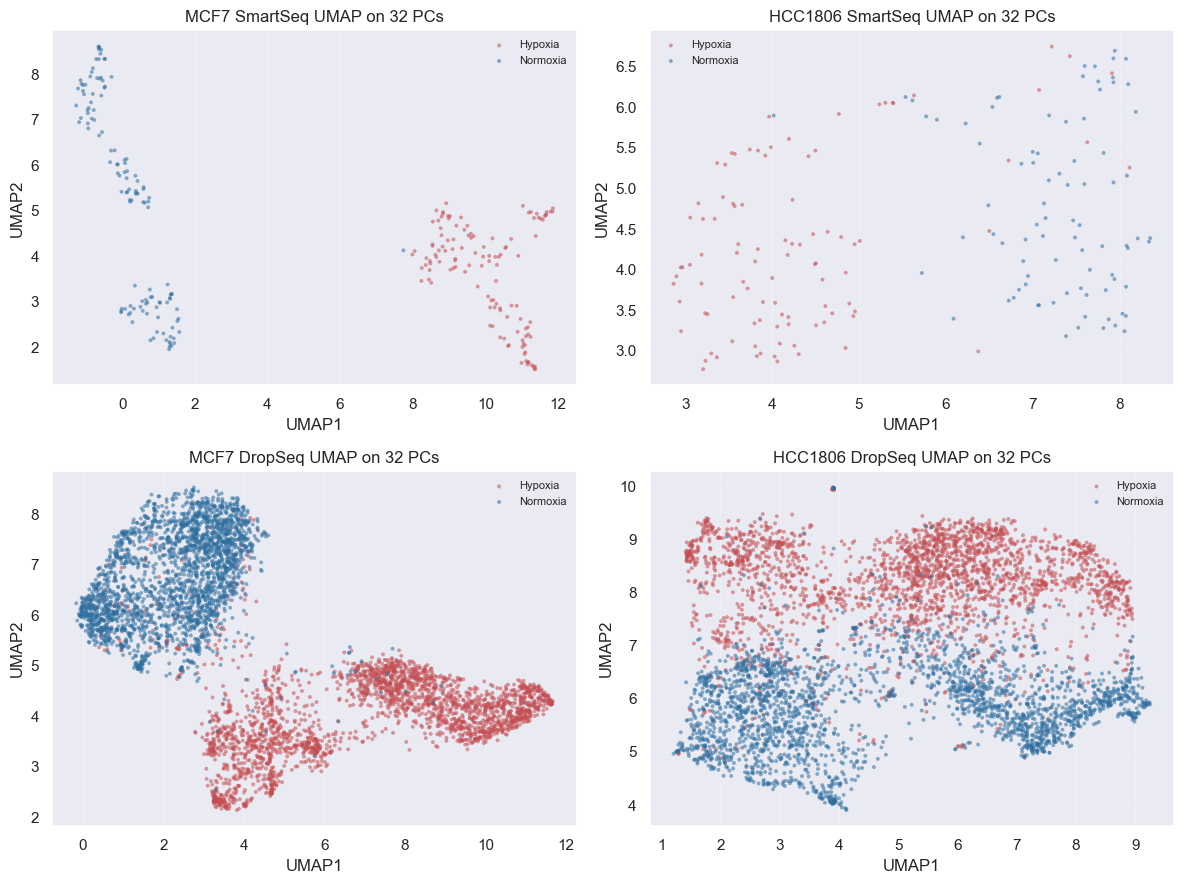

In [35]:
if umap is not None and umap_embeddings:
    fig, axes = plt.subplots(2, 2, figsize=(12, 9))
    for ax, dataset_name in zip(axes.ravel(), DATASET_ORDER):
        key = (dataset_name, default_umap_params["n_neighbors"], default_umap_params["min_dist"])
        if key not in umap_embeddings:
            ax.set_title(f"{DATASET_TITLES[dataset_name]} UMAP unavailable")
            ax.axis("off")
            continue

        plot_df = sample_for_plot(umap_embeddings[key])
        for condition, group in plot_df.groupby("condition"):
            ax.scatter(
                group["UMAP1"],
                group["UMAP2"],
                s=8,
                alpha=0.55,
                label=condition,
                color=CONDITION_COLORS.get(condition),
                edgecolors="none",
            )
        ax.set_title(f"{DATASET_TITLES[dataset_name]} UMAP on {umap_input_components[dataset_name]} PCs")
        ax.set_xlabel("UMAP1")
        ax.set_ylabel("UMAP2")
        ax.grid(alpha=0.2)
        ax.legend(frameon=False, fontsize=8)

    plt.tight_layout()
    plt.show()
elif umap is None:
    print("UMAP plot skipped because umap-learn is not installed.")
else:
    print("UMAP plot skipped because no embeddings were stored.")


The UMAP panel should be interpreted as a local-neighborhood view of the PCA-denoised data. Compact islands with consistent condition coloring suggest local biological structure; mixed islands suggest that the main local neighborhoods are not condition-pure. Because UMAP is stochastic and parameter-sensitive, the plot is useful for hypothesis generation, while the final decision still needs cross-validated prediction scores.

The UMAP views support the same cautious interpretation as the PCA plots, but with stronger emphasis on local neighborhoods. MCF7 shows more visually coherent condition-related grouping than HCC1806, whereas HCC1806 appears more mixed in the low-dimensional view. Because UMAP is fitted on PCA scores and partly sampled for large datasets, the plot is best treated as a qualitative map of local structure rather than a quantitative score.

The useful conclusion is not that UMAP is automatically better than PCA, but that the datasets differ in how visibly hypoxia structure appears after denoising. If UMAP separates a dataset where PCA is mixed, that suggests nonlinear or local-neighborhood structure may matter. If both PCA and UMAP are mixed, supervised validation becomes even more important because the condition signal may not be visually dominant.


### 6.5 Decide component counts

The reusable component grid is now the power-of-two range `32, 64, 128, 256, 512, 1024`. Each dataset receives the subset that is feasible given its number of cells and fitted PCA components. We keep threshold summaries next to the grid: if 80% or 90% cumulative variance is reached inside the fitted range, the corresponding component count is recorded; otherwise it remains missing, which means the selected grid should be treated as a range evaluation rather than a variance-complete representation.


In [36]:
requested_component_grid = DR_COMPONENT_GRID

component_grid_by_dataset = {
    dataset_name: [k for k in requested_component_grid if k <= pca_scores[dataset_name].shape[1]]
    for dataset_name in DATASET_ORDER
}

component_choice_rows = []
for dataset_name in DATASET_ORDER:
    variance = pca_variance[dataset_name]
    row = {
        "dataset": dataset_name,
        "available_components": pca_scores[dataset_name].shape[1],
        "candidate_grid": component_grid_by_dataset[dataset_name],
    }
    for threshold in PCA_VARIANCE_THRESHOLDS:
        reached = variance.loc[variance["cumulative_variance"] >= threshold, "component"]
        row[f"components_for_{int(threshold * 100)}pct_variance"] = int(reached.iloc[0]) if len(reached) else np.nan
    component_choice_rows.append(row)

component_choice_summary = pd.DataFrame(component_choice_rows)
display(component_choice_summary.style.hide(axis="index"))

component_grid_by_dataset


dataset,available_components,candidate_grid,components_for_80pct_variance,components_for_90pct_variance
MCF7_SmartSeq,128,"[32, 64, 128]",nan,nan
HCC1806_SmartSeq,128,"[32, 64, 128]",118.000000,nan
MCF7_DropSeq,1024,"[32, 64, 128, 256, 512, 1024]",nan,nan
HCC1806_DropSeq,1024,"[32, 64, 128, 256, 512, 1024]",nan,nan


{'MCF7_SmartSeq': [32, 64, 128],
 'HCC1806_SmartSeq': [32, 64, 128],
 'MCF7_DropSeq': [32, 64, 128, 256, 512, 1024],
 'HCC1806_DropSeq': [32, 64, 128, 256, 512, 1024]}

## 7. Prediction-oriented DR comparisons, per dataset

This section turns the dimensionality-reduction methods into reusable feature matrices for later supervised classification. Each method is fit separately per dataset. Outputs are stored in `dr_feature_sets`, keyed by dataset, method, and component count, while `dr_method_status` records what was fitted or skipped. Runtime-heavy methods use explicit guards so the notebook does not accidentally launch impractical decompositions on the large DropSeq matrices.


Methodology and rationale. Sections 7.x convert exploratory DR outputs into reusable feature matrices for later classifiers. Methods are still fit separately per dataset. Expensive algorithms use explicit caps, sampling, or PCA-denoised inputs so the notebook records feasible representations instead of spending excessive time in one cell. Skipped settings are not failures; they are documented runtime decisions that later comparison tables can audit.


### 7.1 PCA as the predictive baseline

PCA is the baseline prediction-oriented representation. We reuse the PCA scores fitted in Section 6, slice them to each selected component count, and store them in the shared DR feature registry. These feature sets are cheap to produce and form the reference point for all later DR methods.


In [37]:
dr_feature_sets = {}
dr_method_status = []


In [38]:
def register_dr_features(dataset_name, method, n_components, features, supervised=False, scaling_required=True, details=""):
    assert dataset_name in dr_tables, f"Unknown dataset: {dataset_name}"
    assert isinstance(method, str) and method, "method must be a non-empty string"
    assert isinstance(features, pd.DataFrame), "features must be a pandas DataFrame"
    assert int(n_components) > 0, "n_components must be positive"
    assert features.shape[1] == int(n_components), "feature columns must match n_components"
    assert features.index.equals(dr_meta[dataset_name].index), f"feature index mismatch for {dataset_name}"
    assert np.isfinite(features.to_numpy(dtype=np.float32, copy=False)).all(), "features contain NaN or infinite values"

    key = (dataset_name, method, int(n_components))
    dr_feature_sets[key] = features
    dr_method_status.append({
        "dataset": dataset_name,
        "method": method,
        "n_components": int(n_components),
        "status": "stored",
        "supervised": supervised,
        "scaling_required": scaling_required,
        "n_cells": features.shape[0],
        "n_features_out": features.shape[1],
        "details": details,
    })


def register_dr_skip(dataset_name, method, n_components, reason, supervised=False, scaling_required=True):
    assert dataset_name in dr_tables, f"Unknown dataset: {dataset_name}"
    assert isinstance(method, str) and method, "method must be a non-empty string"
    assert int(n_components) > 0, "n_components must be positive"
    assert isinstance(reason, str) and reason, "skip reason must be a non-empty string"
    dr_method_status.append({
        "dataset": dataset_name,
        "method": method,
        "n_components": int(n_components),
        "status": "skipped",
        "supervised": supervised,
        "scaling_required": scaling_required,
        "n_cells": dr_tables[dataset_name].shape[0],
        "n_features_out": np.nan,
        "details": reason,
    })


def component_columns(prefix, n_components):
    assert isinstance(prefix, str) and prefix, "prefix must be a non-empty string"
    assert int(n_components) > 0, "n_components must be positive"
    return [f"{prefix}{i}" for i in range(1, int(n_components) + 1)]


In [39]:
for dataset_name in DATASET_ORDER:
    for n_components in component_grid_by_dataset[dataset_name]:
        features = pca_scores[dataset_name].iloc[:, :n_components].copy()
        features.columns = component_columns("PCA", n_components)
        register_dr_features(
            dataset_name,
            "PCA",
            n_components,
            features,
            supervised=False,
            scaling_required=True,
            details="Baseline PCA scores from Section 6.2",
        )

pd.DataFrame(dr_method_status).tail()


,dataset,method,n_components,status,supervised,scaling_required,n_cells,n_features_out,details
13,HCC1806_DropSeq,PCA,64,stored,False,True,14682,64,Baseline PCA scores from Section 6.2
14,HCC1806_DropSeq,PCA,128,stored,False,True,14682,128,Baseline PCA scores from Section 6.2
15,HCC1806_DropSeq,PCA,256,stored,False,True,14682,256,Baseline PCA scores from Section 6.2
16,HCC1806_DropSeq,PCA,512,stored,False,True,14682,512,Baseline PCA scores from Section 6.2
17,HCC1806_DropSeq,PCA,1024,stored,False,True,14682,1024,Baseline PCA scores from Section 6.2


### 7.2 Kernel PCA without RBF

Kernel PCA is tested only with `linear` and low-degree `poly` kernels. RBF is excluded because it builds a dense sample-by-sample kernel matrix and is not suitable for the large DropSeq datasets here. Even polynomial Kernel PCA can be expensive, so this cell runs only when the number of cells is below a fixed safety threshold and records skipped settings otherwise.


In [40]:
kernel_pca_kernels = [
    {"kernel": "linear"},
    {"kernel": "poly", "degree": 2, "coef0": 1.0, "gamma": None},
]
max_kernel_pca_cells = 1500

kernel_pca_models = {}


In [41]:
for dataset_name in DATASET_ORDER:
    X = dr_tables[dataset_name]
    if X.shape[0] > max_kernel_pca_cells:
        for kernel_cfg in kernel_pca_kernels:
            method_name = f"KernelPCA_{kernel_cfg['kernel']}"
            for n_components in component_grid_by_dataset[dataset_name]:
                register_dr_skip(
                    dataset_name,
                    method_name,
                    n_components,
                    reason=f"Skipped: {X.shape[0]} cells exceeds max_kernel_pca_cells={max_kernel_pca_cells}",
                    supervised=False,
                    scaling_required=True,
                )
        continue

    X_scaled, _ = standardize_matrix_for_pca(X)
    for kernel_cfg in kernel_pca_kernels:
        method_name = f"KernelPCA_{kernel_cfg['kernel']}"
        for n_components in component_grid_by_dataset[dataset_name]:
            model = KernelPCA(
                n_components=n_components,
                fit_inverse_transform=False,
                eigen_solver="auto",
                random_state=42,
                **kernel_cfg,
            )
            transformed = model.fit_transform(X_scaled)
            features = pd.DataFrame(
                transformed,
                index=X.index,
                columns=component_columns("KPCA", n_components),
            )
            kernel_pca_models[(dataset_name, method_name, n_components)] = model
            register_dr_features(
                dataset_name,
                method_name,
                n_components,
                features,
                supervised=False,
                scaling_required=True,
                details=f"KernelPCA with {kernel_cfg}",
            )

pd.DataFrame(dr_method_status).query("method.str.startswith('KernelPCA')", engine="python").tail()


,dataset,method,n_components,status,supervised,scaling_required,n_cells,n_features_out,details
49,HCC1806_DropSeq,KernelPCA_poly,64,skipped,False,True,14682,NaN,Skipped: 14682 cells exceeds max_kernel_pca_ce...
50,HCC1806_DropSeq,KernelPCA_poly,128,skipped,False,True,14682,NaN,Skipped: 14682 cells exceeds max_kernel_pca_ce...
51,HCC1806_DropSeq,KernelPCA_poly,256,skipped,False,True,14682,NaN,Skipped: 14682 cells exceeds max_kernel_pca_ce...
52,HCC1806_DropSeq,KernelPCA_poly,512,skipped,False,True,14682,NaN,Skipped: 14682 cells exceeds max_kernel_pca_ce...
53,HCC1806_DropSeq,KernelPCA_poly,1024,skipped,False,True,14682,NaN,Skipped: 14682 cells exceeds max_kernel_pca_ce...


### 7.3 PPCA or Factor Analysis

Probabilistic PCA is not directly exposed in sklearn, so this notebook uses `FactorAnalysis` as the closest practical latent Gaussian-factor model. Factor Analysis is fit independently per dataset and stored using the same registry. Large DropSeq fits are guarded by a cell-count threshold because full Factor Analysis can be slow on tens of thousands of cells and 3,000 genes.


In [42]:
max_factor_analysis_cells = 5000
factor_analysis_models = {}


In [43]:
for dataset_name in DATASET_ORDER:
    X = dr_tables[dataset_name]
    if X.shape[0] > max_factor_analysis_cells:
        for n_components in component_grid_by_dataset[dataset_name]:
            register_dr_skip(
                dataset_name,
                "FactorAnalysis",
                n_components,
                reason=f"Skipped: {X.shape[0]} cells exceeds max_factor_analysis_cells={max_factor_analysis_cells}",
                supervised=False,
                scaling_required=True,
            )
        continue

    X_scaled, _ = standardize_matrix_for_pca(X)
    for n_components in component_grid_by_dataset[dataset_name]:
        model = FactorAnalysis(n_components=n_components, random_state=42)
        transformed = model.fit_transform(X_scaled)
        features = pd.DataFrame(
            transformed,
            index=X.index,
            columns=component_columns("FA", n_components),
        )
        factor_analysis_models[(dataset_name, n_components)] = model
        register_dr_features(
            dataset_name,
            "FactorAnalysis",
            n_components,
            features,
            supervised=False,
            scaling_required=True,
            details="sklearn FactorAnalysis used as practical PPCA-style model",
        )

pd.DataFrame(dr_method_status).query("method == 'FactorAnalysis'").tail()


,dataset,method,n_components,status,supervised,scaling_required,n_cells,n_features_out,details
67,HCC1806_DropSeq,FactorAnalysis,64,skipped,False,True,14682,NaN,Skipped: 14682 cells exceeds max_factor_analys...
68,HCC1806_DropSeq,FactorAnalysis,128,skipped,False,True,14682,NaN,Skipped: 14682 cells exceeds max_factor_analys...
69,HCC1806_DropSeq,FactorAnalysis,256,skipped,False,True,14682,NaN,Skipped: 14682 cells exceeds max_factor_analys...
70,HCC1806_DropSeq,FactorAnalysis,512,skipped,False,True,14682,NaN,Skipped: 14682 cells exceeds max_factor_analys...
71,HCC1806_DropSeq,FactorAnalysis,1024,skipped,False,True,14682,NaN,Skipped: 14682 cells exceeds max_factor_analys...


### 7.4 PLS-DA for supervision

PLS-DA is the main supervised dimensionality-reduction candidate in this section. Unlike PCA, it does not try to reconstruct global variance; it tries to find directions that covary with the hypoxia/normoxia label. To keep runtime controlled, the implementation below fits PLS-DA on PCA-denoised scores rather than on the full 3,000-gene matrix. This still gives PLS-DA access to a high-dimensional representation, but avoids repeatedly solving supervised projections on the largest raw DropSeq matrices.

The component grid is capped at 128 components for PLS-DA. That is intentionally generous for a binary target, where hundreds of supervised latent dimensions are usually more than enough for downstream classifiers. Requests above the cap are recorded as skipped instead of being silently compressed, so the comparison table remains honest.


In [44]:
max_pls_components = 128
max_pls_input_pcs = 512
pls_da_models = {}
pls_da_runtime_budget_seconds = 180
pls_da_start_time = time.perf_counter()


In [45]:
for dataset_name in DATASET_ORDER:
    y = dr_meta[dataset_name]["condition"].map({"Normoxia": 0, "Hypoxia": 1}).to_numpy(dtype=np.float32)
    max_input_pcs = min(max_pls_input_pcs, pca_scores[dataset_name].shape[1])
    X_pls_input = pca_scores[dataset_name].iloc[:, :max_input_pcs].to_numpy(dtype=np.float32, copy=True)

    fitted_component_counts = sorted({
        min(k, max_pls_components, X_pls_input.shape[0] - 1, X_pls_input.shape[1])
        for k in component_grid_by_dataset[dataset_name]
        if min(k, max_pls_components, X_pls_input.shape[0] - 1, X_pls_input.shape[1]) >= 1
    })

    for requested_components in component_grid_by_dataset[dataset_name]:
        if requested_components > max_pls_components:
            register_dr_skip(
                dataset_name,
                "PLS_DA",
                requested_components,
                reason=f"Skipped: requested components exceed max_pls_components={max_pls_components}",
                supervised=True,
                scaling_required=True,
            )

    for n_pls in fitted_component_counts:
        if time.perf_counter() - pls_da_start_time > pls_da_runtime_budget_seconds:
            register_dr_skip(
                dataset_name,
                "PLS_DA",
                n_pls,
                reason=f"Stopped: section runtime exceeded {pls_da_runtime_budget_seconds}s budget",
                supervised=True,
                scaling_required=True,
            )
            continue

        model = PLSRegression(n_components=n_pls, scale=False, max_iter=300, tol=1e-5)
        transformed = model.fit_transform(X_pls_input, y)[0]
        features = pd.DataFrame(
            transformed,
            index=pca_scores[dataset_name].index,
            columns=component_columns("PLS", n_pls),
        )
        pls_da_models[(dataset_name, n_pls)] = model
        register_dr_features(
            dataset_name,
            "PLS_DA",
            n_pls,
            features,
            supervised=True,
            scaling_required=True,
            details=(
                f"Fitted on first {max_input_pcs} PCA scores; "
                f"max_iter=300, tol=1e-5, cap={max_pls_components}"
            ),
        )

pd.DataFrame(dr_method_status).query("method == 'PLS_DA'").tail()


,dataset,method,n_components,status,supervised,scaling_required,n_cells,n_features_out,details
85,HCC1806_DropSeq,PLS_DA,512,skipped,True,True,14682,NaN,Skipped: requested components exceed max_pls_c...
86,HCC1806_DropSeq,PLS_DA,1024,skipped,True,True,14682,NaN,Skipped: requested components exceed max_pls_c...
87,HCC1806_DropSeq,PLS_DA,32,stored,True,True,14682,32.0,"Fitted on first 512 PCA scores; max_iter=300, ..."
88,HCC1806_DropSeq,PLS_DA,64,stored,True,True,14682,64.0,"Fitted on first 512 PCA scores; max_iter=300, ..."
89,HCC1806_DropSeq,PLS_DA,128,stored,True,True,14682,128.0,"Fitted on first 512 PCA scores; max_iter=300, ..."


### 7.5 ICA for independent components

FastICA tests whether independent latent sources provide useful prediction features. ICA now inherits the larger power-of-two grid where feasible, but large DropSeq datasets are still skipped by default because ICA can be unstable and expensive at this scale. Skipped settings are recorded in the method-status table instead of being hidden.


In [46]:
max_ica_cells = 5000
max_ica_components = max(DR_COMPONENT_GRID)
ica_models = {}


In [47]:
for dataset_name in DATASET_ORDER:
    X = dr_tables[dataset_name]
    if X.shape[0] > max_ica_cells:
        for n_components in component_grid_by_dataset[dataset_name]:
            register_dr_skip(
                dataset_name,
                "FastICA",
                n_components,
                reason=f"Skipped: {X.shape[0]} cells exceeds max_ica_cells={max_ica_cells}",
                supervised=False,
                scaling_required=True,
            )
        continue

    X_scaled, _ = standardize_matrix_for_pca(X)
    for n_components in component_grid_by_dataset[dataset_name]:
        n_ica = min(n_components, max_ica_components, X.shape[0] - 1, X.shape[1])
        model = FastICA(
            n_components=n_ica,
            random_state=42,
            max_iter=500,
            tol=1e-3,
            whiten="unit-variance",
        )
        transformed = model.fit_transform(X_scaled)
        features = pd.DataFrame(
            transformed,
            index=X.index,
            columns=component_columns("IC", n_ica),
        )
        ica_models[(dataset_name, n_ica)] = model
        register_dr_features(
            dataset_name,
            "FastICA",
            n_ica,
            features,
            supervised=False,
            scaling_required=True,
            details=f"requested {n_components}, fitted {n_ica}; max_iter=500, tol=1e-3",
        )

pd.DataFrame(dr_method_status).query("method == 'FastICA'").tail()


,dataset,method,n_components,status,supervised,scaling_required,n_cells,n_features_out,details
103,HCC1806_DropSeq,FastICA,64,skipped,False,True,14682,NaN,Skipped: 14682 cells exceeds max_ica_cells=5000
104,HCC1806_DropSeq,FastICA,128,skipped,False,True,14682,NaN,Skipped: 14682 cells exceeds max_ica_cells=5000
105,HCC1806_DropSeq,FastICA,256,skipped,False,True,14682,NaN,Skipped: 14682 cells exceeds max_ica_cells=5000
106,HCC1806_DropSeq,FastICA,512,skipped,False,True,14682,NaN,Skipped: 14682 cells exceeds max_ica_cells=5000
107,HCC1806_DropSeq,FastICA,1024,skipped,False,True,14682,NaN,Skipped: 14682 cells exceeds max_ica_cells=5000


### 7.6 Sparse PCA and sparse projections

Sparse PCA is included as a sparse latent projection baseline, but the standard `SparsePCA` solver is too slow for this notebook, especially on DropSeq. The implementation below uses `MiniBatchSparsePCA` on PCA-denoised inputs rather than on the full 3,000-gene matrix. This keeps the representation high-dimensional enough to be useful while avoiding a raw sparse dictionary-learning problem over tens of thousands of cells.

The sparse component cap is 128. That is high enough to test a useful range (`32, 64, 128`) while avoiding the runtime and convergence problems that usually appear at `256+` sparse components. For large datasets, the model is fit on a stratified cell sample and then used to transform all cells. Larger requested component values are recorded as skipped with an explicit reason.


In [48]:
max_sparse_pca_components = 128
max_sparse_pca_input_pcs = 512
max_sparse_pca_fit_cells = 5000
sparse_pca_batch_size = 512
sparse_pca_runtime_budget_seconds = 240
sparse_pca_models = {}


In [49]:
def stratified_sample_indices(meta, max_cells, random_state=42):
    if len(meta) <= max_cells:
        return np.arange(len(meta))

    rng = np.random.default_rng(random_state)
    sampled_positions = []
    per_class = max_cells // meta["condition"].nunique()

    for condition, idx in meta.groupby("condition").groups.items():
        positions = meta.index.get_indexer(idx)
        n_take = min(len(positions), per_class)
        sampled_positions.extend(rng.choice(positions, size=n_take, replace=False).tolist())

    remaining = max_cells - len(sampled_positions)
    if remaining > 0:
        all_positions = np.arange(len(meta))
        unused = np.setdiff1d(all_positions, np.array(sampled_positions), assume_unique=False)
        sampled_positions.extend(rng.choice(unused, size=min(remaining, len(unused)), replace=False).tolist())

    return np.array(sorted(sampled_positions))


In [50]:
sparse_pca_start_time = time.perf_counter()

for dataset_name in DATASET_ORDER:
    max_input_pcs = min(max_sparse_pca_input_pcs, pca_scores[dataset_name].shape[1])
    X_sparse_input = pca_scores[dataset_name].iloc[:, :max_input_pcs].to_numpy(dtype=np.float32, copy=True)
    fit_positions = stratified_sample_indices(dr_meta[dataset_name], max_sparse_pca_fit_cells)
    X_fit = X_sparse_input[fit_positions]

    fitted_component_counts = sorted({
        min(k, max_sparse_pca_components, X_fit.shape[0] - 1, X_fit.shape[1])
        for k in component_grid_by_dataset[dataset_name]
        if k <= max_sparse_pca_components
        and min(k, max_sparse_pca_components, X_fit.shape[0] - 1, X_fit.shape[1]) >= 1
    })

    for requested_components in component_grid_by_dataset[dataset_name]:
        if requested_components > max_sparse_pca_components:
            register_dr_skip(
                dataset_name,
                "MiniBatchSparsePCA",
                requested_components,
                reason=f"Skipped: requested components exceed max_sparse_pca_components={max_sparse_pca_components}",
                supervised=False,
                scaling_required=True,
            )

    for n_sparse in fitted_component_counts:
        if time.perf_counter() - sparse_pca_start_time > sparse_pca_runtime_budget_seconds:
            register_dr_skip(
                dataset_name,
                "MiniBatchSparsePCA",
                n_sparse,
                reason=f"Stopped: section runtime exceeded {sparse_pca_runtime_budget_seconds}s budget",
                supervised=False,
                scaling_required=True,
            )
            continue

        model = MiniBatchSparsePCA(
            n_components=n_sparse,
            alpha=1.0,
            ridge_alpha=0.01,
            batch_size=sparse_pca_batch_size,
            max_iter=100,
            method="cd",
            tol=1e-3,
            max_no_improvement=10,
            random_state=42,
            n_jobs=-1,
        )
        model.fit(X_fit)
        transformed = model.transform(X_sparse_input)
        features = pd.DataFrame(
            transformed,
            index=pca_scores[dataset_name].index,
            columns=component_columns("MBSPCA", n_sparse),
        )
        sparse_pca_models[(dataset_name, n_sparse)] = model
        register_dr_features(
            dataset_name,
            "MiniBatchSparsePCA",
            n_sparse,
            features,
            supervised=False,
            scaling_required=True,
            details=(
                f"Fitted on {len(fit_positions)} stratified cells using first {max_input_pcs} PCA scores; "
                f"transformed all cells; alpha=1.0, method=cd, batch_size={sparse_pca_batch_size}, max_iter=100"
            ),
        )

pd.DataFrame(dr_method_status).query("method == 'MiniBatchSparsePCA'").tail()


,dataset,method,n_components,status,supervised,scaling_required,n_cells,n_features_out,details
121,HCC1806_DropSeq,MiniBatchSparsePCA,512,skipped,False,True,14682,NaN,Skipped: requested components exceed max_spars...
122,HCC1806_DropSeq,MiniBatchSparsePCA,1024,skipped,False,True,14682,NaN,Skipped: requested components exceed max_spars...
123,HCC1806_DropSeq,MiniBatchSparsePCA,32,stored,False,True,14682,32.0,Fitted on 5000 stratified cells using first 51...
124,HCC1806_DropSeq,MiniBatchSparsePCA,64,stored,False,True,14682,64.0,Fitted on 5000 stratified cells using first 51...
125,HCC1806_DropSeq,MiniBatchSparsePCA,128,stored,False,True,14682,128.0,Fitted on 5000 stratified cells using first 51...


### 7.7 Random projection baseline

Random projection is a fast baseline that approximately preserves distances without learning a data-specific latent space. It now uses the same power-of-two component grid as the other methods wherever the requested dimension is smaller than the original 3,000-gene space. This gives a cheap high-dimensional reference against the learned DR methods.


In [51]:
random_projection_models = {}
random_projection_components = DR_COMPONENT_GRID


In [52]:
for dataset_name in DATASET_ORDER:
    X = dr_tables[dataset_name]
    X_scaled, _ = standardize_matrix_for_pca(X)
    valid_components = [k for k in random_projection_components if k < X.shape[1]]

    for n_components in valid_components:
        model = GaussianRandomProjection(n_components=n_components, random_state=42)
        transformed = model.fit_transform(X_scaled)
        features = pd.DataFrame(
            transformed,
            index=X.index,
            columns=component_columns("RP", n_components),
        )
        random_projection_models[(dataset_name, n_components)] = model
        register_dr_features(
            dataset_name,
            "RandomProjection",
            n_components,
            features,
            supervised=False,
            scaling_required=True,
            details="Gaussian random projection baseline; random_state=42",
        )

pd.DataFrame(dr_method_status).tail()


,dataset,method,n_components,status,supervised,scaling_required,n_cells,n_features_out,details
145,HCC1806_DropSeq,RandomProjection,64,stored,False,True,14682,64.0,Gaussian random projection baseline; random_st...
146,HCC1806_DropSeq,RandomProjection,128,stored,False,True,14682,128.0,Gaussian random projection baseline; random_st...
147,HCC1806_DropSeq,RandomProjection,256,stored,False,True,14682,256.0,Gaussian random projection baseline; random_st...
148,HCC1806_DropSeq,RandomProjection,512,stored,False,True,14682,512.0,Gaussian random projection baseline; random_st...
149,HCC1806_DropSeq,RandomProjection,1024,stored,False,True,14682,1024.0,Gaussian random projection baseline; random_st...


## 8. Comparison and reporting

This section consolidates the dimensionality-reduction outputs created in Sections 6 and 7. The goal is not to select a final classifier here, but to make the generated feature sets auditable: which dataset they belong to, which method produced them, how many components they contain, whether labels were used, and whether a setting was skipped for runtime reasons. Analytically, PLS-DA deserves special attention because it is supervised: if sparse/noisy gene expression prevents PCA from retaining high global variance, that does not automatically invalidate dimensionality reduction. PCA variance retention is a reconstruction criterion, while PLS-DA is designed around label discrimination. Final choice still has to come from cross-validated classifier scores, not from the variance curves alone.


Methodology and rationale. Sections 8.x do not choose a final model. They summarize which DR feature sets exist, which settings were skipped, and what each method is analytically meant to test. Final selection should come from cross-validated classifier scores, not from PCA variance curves or visual separation alone.


### 8.1 Method comparison table

We convert the `dr_method_status` registry into a structured summary table. Stored feature sets and skipped settings are kept together so that downstream modelling can distinguish available representations from methods that were intentionally not run. The table also records the shape of every available feature matrix and the reason for any skipped setting. The summary is especially useful after the runtime guards in PLS-DA and MiniBatchSparsePCA, because it shows exactly which high-dimensional settings were feasible.


In [53]:
if "dr_method_status" not in globals():
    raise RuntimeError("Run Section 7 before building the DR method summary.")

status_columns = [
    "dataset",
    "method",
    "n_components",
    "status",
    "supervised",
    "scaling_required",
    "n_cells",
    "n_features_out",
    "details",
]

dr_method_summary = pd.DataFrame(dr_method_status)
if dr_method_summary.empty:
    dr_method_summary = pd.DataFrame(columns=status_columns)
else:
    dr_method_summary = dr_method_summary.reindex(columns=status_columns)
    dr_method_summary = dr_method_summary.sort_values(
        ["dataset", "method", "n_components", "status"],
        kind="stable",
    ).reset_index(drop=True)


In [54]:
# Cross-check registry metadata against the actual saved feature matrices.
for key, features in dr_feature_sets.items():
    dataset_name, method, n_components = key
    assert features.index.equals(dr_meta[dataset_name].index), f"Index mismatch for {key}"
    assert features.shape[1] == int(n_components), f"Feature count mismatch for {key}"

available_feature_sets = (
    dr_method_summary
    .query("status == 'stored'")
    .groupby(["dataset", "method"], as_index=False)
    .agg(
        component_settings=("n_components", lambda s: sorted(s.astype(int).unique().tolist())),
        max_components=("n_components", "max"),
        n_feature_sets=("n_components", "size"),
        supervised=("supervised", "first"),
        scaling_required=("scaling_required", "first"),
    )
)

skip_summary = (
    dr_method_summary
    .query("status == 'skipped'")
    .groupby(["dataset", "method", "details"], as_index=False)
    .agg(skipped_settings=("n_components", lambda s: sorted(s.astype(int).unique().tolist())))
)

method_availability = pd.crosstab(
    dr_method_summary["method"],
    dr_method_summary["status"],
).reset_index()


In [55]:
print("Available DR feature sets:")
display(available_feature_sets.style.hide(axis="index"))

print("Method status counts:")
display(method_availability.style.hide(axis="index"))

if not skip_summary.empty:
    print("Skipped settings and reasons:")
    display(skip_summary.style.hide(axis="index"))

print(f"Total stored feature sets: {len(dr_feature_sets)}")


Available DR feature sets:


dataset,method,component_settings,max_components,n_feature_sets,supervised,scaling_required
HCC1806_DropSeq,MiniBatchSparsePCA,"[32, 64, 128]",128,3,False,True
HCC1806_DropSeq,PCA,"[32, 64, 128, 256, 512, 1024]",1024,6,False,True
HCC1806_DropSeq,PLS_DA,"[32, 64, 128]",128,3,True,True
HCC1806_DropSeq,RandomProjection,"[32, 64, 128, 256, 512, 1024]",1024,6,False,True
HCC1806_SmartSeq,FactorAnalysis,"[32, 64, 128]",128,3,False,True
HCC1806_SmartSeq,FastICA,"[32, 64, 128]",128,3,False,True
HCC1806_SmartSeq,KernelPCA_linear,"[32, 64, 128]",128,3,False,True
HCC1806_SmartSeq,KernelPCA_poly,"[32, 64, 128]",128,3,False,True
HCC1806_SmartSeq,MiniBatchSparsePCA,"[32, 64, 128]",128,3,False,True
HCC1806_SmartSeq,PCA,"[32, 64, 128]",128,3,False,True


Method status counts:


method,skipped,stored
FactorAnalysis,12,6
FastICA,12,6
KernelPCA_linear,12,6
KernelPCA_poly,12,6
MiniBatchSparsePCA,6,12
PCA,0,18
PLS_DA,6,12
RandomProjection,0,24


Skipped settings and reasons:


dataset,method,details,skipped_settings
HCC1806_DropSeq,FactorAnalysis,Skipped: 14682 cells exceeds max_factor_analysis_cells=5000,"[32, 64, 128, 256, 512, 1024]"
HCC1806_DropSeq,FastICA,Skipped: 14682 cells exceeds max_ica_cells=5000,"[32, 64, 128, 256, 512, 1024]"
HCC1806_DropSeq,KernelPCA_linear,Skipped: 14682 cells exceeds max_kernel_pca_cells=1500,"[32, 64, 128, 256, 512, 1024]"
HCC1806_DropSeq,KernelPCA_poly,Skipped: 14682 cells exceeds max_kernel_pca_cells=1500,"[32, 64, 128, 256, 512, 1024]"
HCC1806_DropSeq,MiniBatchSparsePCA,Skipped: requested components exceed max_sparse_pca_components=128,"[256, 512, 1024]"
HCC1806_DropSeq,PLS_DA,Skipped: requested components exceed max_pls_components=128,"[256, 512, 1024]"
MCF7_DropSeq,FactorAnalysis,Skipped: 21626 cells exceeds max_factor_analysis_cells=5000,"[32, 64, 128, 256, 512, 1024]"
MCF7_DropSeq,FastICA,Skipped: 21626 cells exceeds max_ica_cells=5000,"[32, 64, 128, 256, 512, 1024]"
MCF7_DropSeq,KernelPCA_linear,Skipped: 21626 cells exceeds max_kernel_pca_cells=1500,"[32, 64, 128, 256, 512, 1024]"
MCF7_DropSeq,KernelPCA_poly,Skipped: 21626 cells exceeds max_kernel_pca_cells=1500,"[32, 64, 128, 256, 512, 1024]"


Total stored feature sets: 90


### 8.1 Analytical interpretation before CV

Low PCA explained variance is not, by itself, a reason to discard dimensionality reduction. In sparse and noisy scRNA-seq matrices, global reconstruction variance can be a weak proxy for classification value. PCA, Factor Analysis, ICA, Sparse PCA, and Random Projection are mainly unsupervised or reconstruction/distance-oriented. PLS-DA is different because it uses the condition labels and may find discriminative structure even when no unsupervised method preserves more than about 70% variance. This makes PLS-DA a strong analytical candidate for later supervised experiments, but it should not be declared best until cross-validation compares downstream classifier performance across the saved DR feature sets.


### 8.2 Figure formatting rule

The DR section uses one plotting convention throughout: figures comparing all four datasets should use a 2x2 grid and finish with `plt.tight_layout()`. Dedicated single-dataset figures are allowed when a 2x2 layout would hide the relevant structure. The helper functions below standardize this rule for later PCA, UMAP, and classifier-diagnostic plots.


In [56]:
def make_2x2_dataset_axes(figsize=(12, 9), sharex=False, sharey=False):
    assert len(DATASET_ORDER) == 4, "2x2 dataset plot requires exactly four datasets"
    assert len(figsize) == 2 and figsize[0] > 0 and figsize[1] > 0, "figsize must contain positive width and height"
    fig, axes = plt.subplots(2, 2, figsize=figsize, sharex=sharex, sharey=sharey)
    return fig, dict(zip(DATASET_ORDER, axes.ravel()))


def finish_2x2_figure(title=None):
    assert title is None or isinstance(title, str), "title must be None or a string"
    if title is not None:
        plt.suptitle(title, y=1.02)
    plt.tight_layout()
    plt.show()


def plot_dr_feature_availability():
    if available_feature_sets.empty:
        print("No stored DR feature sets available to plot.")
        return

    plot_df = available_feature_sets.pivot_table(
        index="method",
        columns="dataset",
        values="n_feature_sets",
        fill_value=0,
        aggfunc="sum",
    ).reindex(columns=DATASET_ORDER)

    ax = plot_df.plot(kind="bar", figsize=(12, 5), width=0.8)
    ax.set_title("Stored DR feature-set counts by method and dataset")
    ax.set_xlabel("DR method")
    ax.set_ylabel("Number of stored component settings")
    ax.legend(title="Dataset", frameon=False, bbox_to_anchor=(1.02, 1), loc="upper left")
    plt.tight_layout()
    plt.show()


The feature-availability chart is a practicality check. Methods that appear across all datasets and component counts are easier to compare fairly later; methods with many skipped settings are still informative, but their conclusions are narrower. The main takeaway is that PCA and random projection are operationally robust baselines, while supervised or sparse methods should be evaluated only where the registry confirms that valid feature matrices were actually produced.

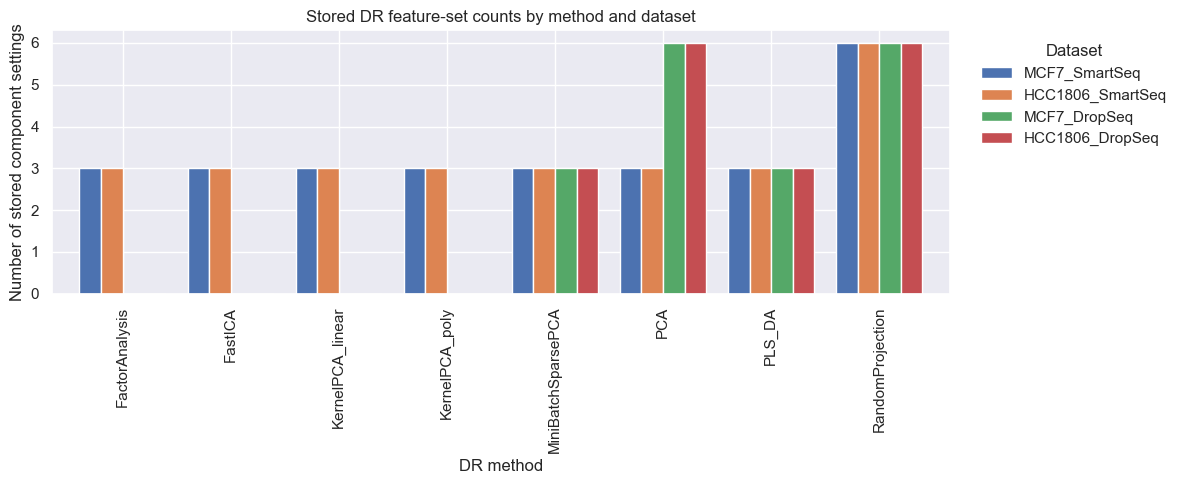

In [57]:
plot_dr_feature_availability()


The feature-availability chart is mainly an audit of practicality. Standard PCA produces the broadest and most reliable set of reduced matrices because it is fast, deterministic enough with a fixed seed, and easy to slice across component counts. Many alternatives are intentionally capped or skipped because their cost grows quickly on large DropSeq matrices. This does not prove PCA is predictively best; it means PCA is the strongest operational baseline and the safest representation to carry into downstream classifiers.

The reporting conclusion is that method availability itself matters. A theoretically attractive method that only runs on the smallest datasets is less useful for a consistent four-dataset workflow. PLS-DA remains analytically important because it is supervised, but final model selection should still depend on cross-validated classification scores rather than on how many feature sets a method produced.


### 8.3 Qualitative best-candidate visual inspection

No classifier scores are available yet, so this cell does not claim a true best-performing representation. Instead, it creates a qualitative inspection grid using the most informative available visual representation: UMAP on PCA scores when Section 6.4 has produced embeddings, otherwise PCA PC1/PC2. This gives a compact visual check of separation patterns while keeping final model selection for the supervised evaluation stage.


In [58]:
def plot_best_available_dr_visuals():
    use_umap = "umap_embeddings" in globals() and len(umap_embeddings) > 0
    default_umap_params = {"n_neighbors": 15, "min_dist": 0.01}

    fig, axes = plt.subplots(2, 2, figsize=(12, 9))
    for ax, dataset_name in zip(axes.ravel(), DATASET_ORDER):
        if use_umap and (dataset_name, default_umap_params["n_neighbors"], default_umap_params["min_dist"]) in umap_embeddings:
            view_name = "UMAP on PCA"
            df = umap_embeddings[(dataset_name, default_umap_params["n_neighbors"], default_umap_params["min_dist"])]
            x_col, y_col = "UMAP1", "UMAP2"
        else:
            view_name = "PCA PC1/PC2"
            df = pca_2d_coords[dataset_name]
            x_col, y_col = "PC1", "PC2"

        plot_df = sample_for_plot(df)
        for condition, group in plot_df.groupby("condition"):
            ax.scatter(
                group[x_col],
                group[y_col],
                s=8,
                alpha=0.55,
                label=condition,
                color=CONDITION_COLORS.get(condition),
                edgecolors="none",
            )
        ax.set_title(f"{DATASET_TITLES[dataset_name]}: {view_name}")
        ax.set_xlabel(x_col)
        ax.set_ylabel(y_col)
        ax.grid(alpha=0.2)
        ax.legend(frameon=False, fontsize=8)

    plt.tight_layout()
    plt.show()


The best-available DR visual grid is a compact qualitative summary of the earlier DR plots. If UMAP is available, it shows local structure; otherwise it falls back to PCA PC1/PC2. A clear visual split supports the idea that the condition signal is easy to expose, but mixed panels are not failures: they simply mean the predictive signal may require more components, supervised DR, or a classifier that uses feature interactions.

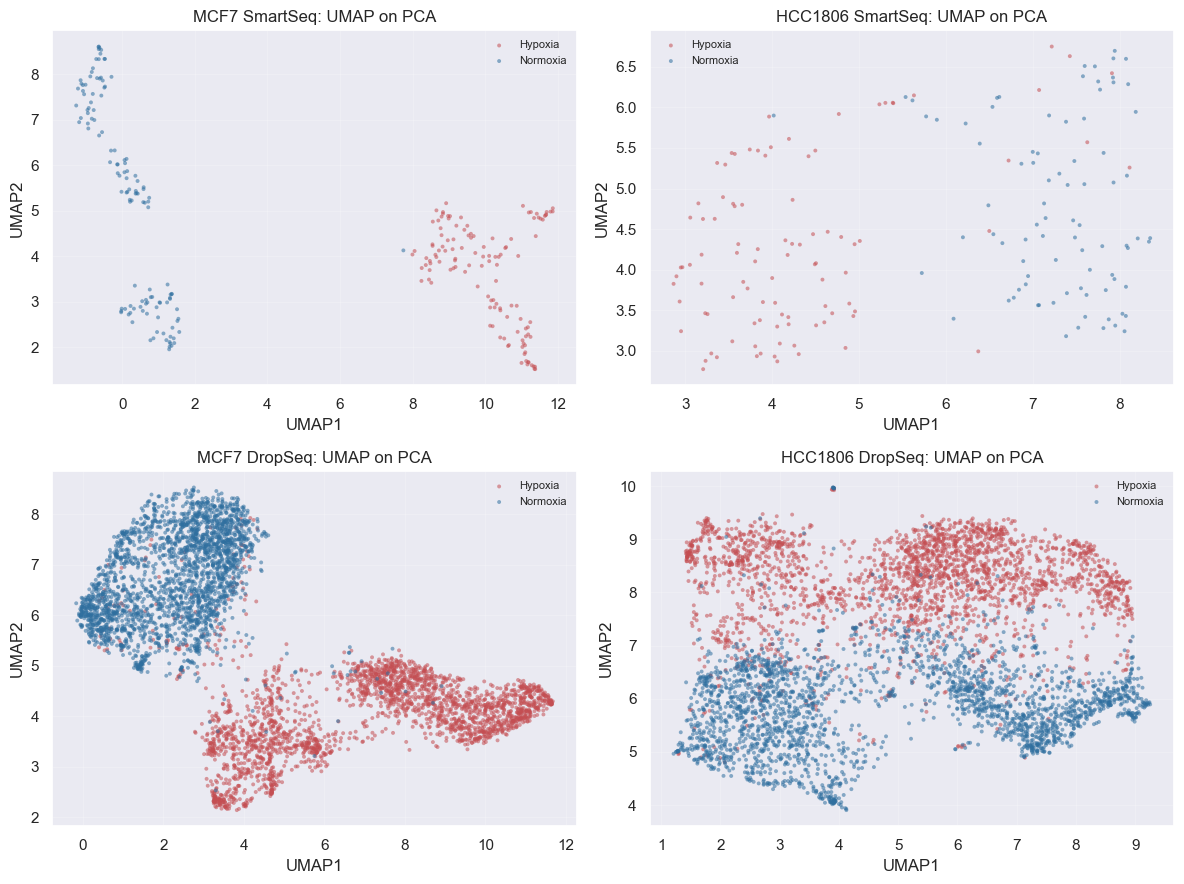

In [59]:
plot_best_available_dr_visuals()
# nothing major changed, UMAP as above.

## 9. DR limitations and conclusions

Sections 6-8 define a pragmatic dimensionality-reduction search, not a final modelling conclusion. Bayesian optimization would be a more adaptive way to tune component counts and method hyperparameters, but it is overkill at this stage because each evaluation would require expensive downstream validation across four datasets. The power-of-two grid is coarse, but it gives useful scale coverage from small to large latent spaces and is usually a good first approximation for finding the right order of magnitude.

A more refined second pass could replace the binary-spaced grid with Fibonacci-style or logarithmic intermediate values between the best lower and upper power-of-two bounds. That would search the promising range more smoothly, but it would cost substantially more runtime and may not improve results. For this kind of sparse, noisy scRNA-seq data, black-box tree models and CatBoost-like methods can often handle many original features directly; dimensionality reduction can help by denoising or compressing, but it can also remove predictive signal. Therefore, these DR outputs should be treated as candidate representations. Cross-validated classifier performance should decide whether PCA, PLS-DA, sparse projections, random projections, or the original gene space is best.


## 10. Clustering, per dataset

This section continues from the dimensionality-reduction workflow rather than replacing it. Clustering is used as a structure-discovery tool: it asks whether cells group naturally before any classifier is trained. The analysis remains per dataset so that cell line and sequencing technology are not mixed prematurely, and full-data checks are added only for methods that can run safely on all cells.


### 10.0 Clustering methodology

The clustering block has two roles. First, it checks whether the DR outputs from Sections 6-8 contain coherent unsupervised structure. Second, it tests whether some structure exists in the full 3,000-gene matrices that PCA may compress away. Labels are never used to fit clusters; hypoxia/normoxia, cell line, and technology are only overlaid after clustering to interpret what the unsupervised groups might represent. A good clustering result here is therefore not just a high metric score: it should also produce interpretable, stable-looking groups without excessive noise or fragile parameters.


### 10.1 Clustering inputs and setup

We keep two clustering input families. The reduced input uses PCA/DR features from Section 7 and is best for readable geometry, fast scoring, and expensive algorithms such as hierarchical clustering. The full input uses the standardized 3,000-gene matrix and is reserved for methods that can handle all cells cheaply enough, especially mini-batch k-means and KNN graph components. This split matters because PCA can remove low-variance or nonlinear structure, while full-gene methods can be noisy but less dependent on the PCA projection.


In [60]:
CLUSTERING_RANDOM_STATE = 42
CLUSTERING_COMPONENT_TARGET = 64
CLUSTERING_K_GRID = [2, 3, 4, 5, 6]
CLUSTERING_MAX_SCORE_CELLS = 3000
CLUSTERING_MAX_DENDROGRAM_CELLS = 300
CLUSTERING_MAX_HIERARCHICAL_CELLS = 6000
CLUSTERING_HIERARCHICAL_RUNTIME_BUDGET_SECONDS = 120
CLUSTERING_DBSCAN_RUNTIME_BUDGET_SECONDS = 90
CLUSTERING_KMEANS_FULL_RUNTIME_BUDGET_SECONDS = 180
CLUSTERING_KNN_RUNTIME_BUDGET_SECONDS = 120
FULL_KMEANS_BATCH_SIZE = 1024
KNN_NEIGHBORS_GRID = [50, 75]
KNN_DISTANCE_QUANTILES = [0.25, 0.40]
KNN_MIN_CLUSTER_SIZE = 20
DBSCAN_EPS_GRID = [0.8, 1.2, 1.6]
DBSCAN_MIN_SAMPLES = 10

cluster_inputs = {}
full_cluster_inputs = {}
cluster_assignments = {}
cluster_metric_rows = []
cluster_summary_rows = []


In [61]:
def select_clustering_features(dataset_name, target_components=CLUSTERING_COMPONENT_TARGET):
    assert dataset_name in DATASET_ORDER, f"Unknown dataset: {dataset_name}"
    assert dataset_name in dr_meta, f"Missing metadata for {dataset_name}"
    assert int(target_components) > 0, "target component count must be positive"

    available_pca_keys = [
        key for key in dr_feature_sets
        if key[0] == dataset_name and key[1] == "PCA" and key[2] <= target_components
    ] if "dr_feature_sets" in globals() else []

    if available_pca_keys:
        chosen_key = max(available_pca_keys, key=lambda key: key[2])
        features = dr_feature_sets[chosen_key].copy()
        source_name = f"dr_feature_sets[{chosen_key}]"
    else:
        n_components = min(target_components, pca_scores[dataset_name].shape[1])
        features = pca_scores[dataset_name].iloc[:, :n_components].copy()
        source_name = f"pca_scores first {n_components} PCs"

    assert features.index.equals(dr_meta[dataset_name].index), f"Metadata mismatch for {dataset_name} clustering input"
    assert np.isfinite(features.to_numpy(dtype=np.float32, copy=False)).all(), f"Non-finite clustering input for {dataset_name}"
    return features, source_name


def make_full_clustering_features(dataset_name):
    assert dataset_name in dr_tables, f"Missing DR-ready table for {dataset_name}"
    X_scaled, _ = standardize_matrix_for_pca(dr_tables[dataset_name])
    features = pd.DataFrame(
        X_scaled,
        index=dr_tables[dataset_name].index,
        columns=dr_tables[dataset_name].columns,
    )
    assert features.index.equals(dr_meta[dataset_name].index), f"Full-data metadata mismatch for {dataset_name}"
    assert features.shape[1] == 3000, f"Expected 3000 full-data features for {dataset_name}"
    return features, "standardized full 3000-gene matrix"


In [62]:
for dataset_name in DATASET_ORDER:
    features, source_name = select_clustering_features(dataset_name)
    full_features, full_source_name = make_full_clustering_features(dataset_name)
    cluster_inputs[dataset_name] = features
    full_cluster_inputs[dataset_name] = full_features
    print(f"{dataset_name:<16}: reduced {features.shape[0]} x {features.shape[1]} from {source_name}")
    print(f"{'':<16}  full    {full_features.shape[0]} x {full_features.shape[1]} from {full_source_name}")


MCF7_SmartSeq   : reduced 250 x 64 from dr_feature_sets[('MCF7_SmartSeq', 'PCA', 64)]
                  full    250 x 3000 from standardized full 3000-gene matrix
HCC1806_SmartSeq: reduced 182 x 64 from dr_feature_sets[('HCC1806_SmartSeq', 'PCA', 64)]
                  full    182 x 3000 from standardized full 3000-gene matrix
MCF7_DropSeq    : reduced 21626 x 64 from dr_feature_sets[('MCF7_DropSeq', 'PCA', 64)]
                  full    21626 x 3000 from standardized full 3000-gene matrix
HCC1806_DropSeq : reduced 14682 x 64 from dr_feature_sets[('HCC1806_DropSeq', 'PCA', 64)]
                  full    14682 x 3000 from standardized full 3000-gene matrix


In [63]:
def safe_silhouette(features, labels, max_cells=CLUSTERING_MAX_SCORE_CELLS):
    labels = pd.Series(labels, index=features.index)
    labels = labels.loc[labels != -1]
    X = features.loc[labels.index]

    if len(labels) < 3 or labels.nunique() < 2 or labels.nunique() >= len(labels):
        return np.nan
    if labels.value_counts().min() < 2:
        return np.nan

    if len(labels) > max_cells:
        per_cluster = max(2, max_cells // labels.nunique())
        sampled_parts = []
        for _, cluster_index in labels.groupby(labels).groups.items():
            cluster_index = pd.Index(cluster_index)
            n_take = min(len(cluster_index), per_cluster)
            sampled_parts.extend(
                cluster_index.to_series().sample(n_take, random_state=CLUSTERING_RANDOM_STATE).index.tolist()
            )

        sampled_index = pd.Index(sampled_parts).unique()
        if len(sampled_index) > max_cells:
            sampled_index = sampled_index.to_series().sample(max_cells, random_state=CLUSTERING_RANDOM_STATE).index
        labels = labels.loc[sampled_index]
        X = X.loc[sampled_index]

    if len(labels) < 3 or labels.nunique() < 2 or labels.nunique() >= len(labels):
        return np.nan
    if labels.value_counts().min() < 2:
        return np.nan

    try:
        return float(silhouette_score(X.to_numpy(dtype=np.float32), labels.to_numpy()))
    except ValueError:
        return np.nan


def record_cluster_result(dataset_name, method, setting, labels, features):
    labels = pd.Series(labels, index=features.index, name="cluster")
    assert labels.index.equals(dr_meta[dataset_name].index), f"Cluster labels misaligned for {dataset_name}"

    assignment = dr_meta[dataset_name].copy()
    assignment["cluster"] = labels.astype(int)
    cluster_assignments[(dataset_name, method, str(setting))] = assignment

    cluster_metric_rows.append({
        "dataset": dataset_name,
        "method": method,
        "setting": str(setting),
        "n_clusters": int(labels[labels != -1].nunique()),
        "noise_fraction": float((labels == -1).mean()),
        "silhouette": safe_silhouette(features, labels),
        "ari_condition": adjusted_rand_score(assignment["condition"], labels),
        "nmi_condition": normalized_mutual_info_score(assignment["condition"], labels),
    })
    return assignment


In [64]:
def summarize_cluster_labels(dataset_name, method, setting, label_col="condition"):
    key = (dataset_name, method, str(setting))
    assert key in cluster_assignments, f"Missing cluster assignment: {key}"
    assignment = cluster_assignments[key]

    summary = (
        assignment
        .groupby("cluster")
        .agg(
            n_cells=(label_col, "size"),
            dominant_label=(label_col, lambda s: s.value_counts().idxmax()),
            dominant_fraction=(label_col, lambda s: s.value_counts(normalize=True).max()),
        )
        .reset_index()
    )
    summary.insert(0, "dataset", dataset_name)
    summary.insert(1, "method", method)
    summary.insert(2, "setting", str(setting))
    return summary


def interpret_cluster_summary(summary, purity_threshold=0.75):
    if summary.empty:
        return "no usable clusters"
    if summary["dominant_fraction"].min() >= purity_threshold:
        return "clear label-skewed clusters"
    if summary["dominant_fraction"].mean() >= 0.65:
        return "partial label structure"
    return "mixed clusters"


In [65]:
def plot_cluster_grid(method, setting, color_by="cluster", title_suffix=""):
    fig, axes = plt.subplots(2, 2, figsize=(12, 9))
    for ax, dataset_name in zip(axes.ravel(), DATASET_ORDER):
        key = (dataset_name, method, str(setting))
        if key not in cluster_assignments:
            ax.set_title(f"{DATASET_TITLES[dataset_name]} unavailable")
            ax.axis("off")
            continue

        plot_df = pca_2d_coords[dataset_name][["PC1", "PC2"]].join(cluster_assignments[key])
        plot_df = sample_for_plot(plot_df)
        for value, group in plot_df.groupby(color_by):
            ax.scatter(group["PC1"], group["PC2"], s=8, alpha=0.55, label=str(value), edgecolors="none")
        ax.set_title(f"{DATASET_TITLES[dataset_name]} {title_suffix}".strip())
        ax.set_xlabel("PC1")
        ax.set_ylabel("PC2")
        ax.grid(alpha=0.2)
        ax.legend(frameon=False, fontsize=7)

    plt.tight_layout()
    plt.show()


def plot_best_setting_grid(method, best_settings, color_by="cluster", title_suffix=""):
    fig, axes = plt.subplots(2, 2, figsize=(12, 9))
    for ax, dataset_name in zip(axes.ravel(), DATASET_ORDER):
        setting = best_settings.get(dataset_name)
        key = (dataset_name, method, str(setting))
        if setting is None or key not in cluster_assignments:
            ax.set_title(f"{DATASET_TITLES[dataset_name]} unavailable")
            ax.axis("off")
            continue

        plot_df = pca_2d_coords[dataset_name][["PC1", "PC2"]].join(cluster_assignments[key])
        plot_df = sample_for_plot(plot_df)
        for value, group in plot_df.groupby(color_by):
            ax.scatter(group["PC1"], group["PC2"], s=8, alpha=0.55, label=str(value), edgecolors="none")
        ax.set_title(f"{DATASET_TITLES[dataset_name]} {title_suffix} {setting}".strip())
        ax.set_xlabel("PC1")
        ax.set_ylabel("PC2")
        ax.grid(alpha=0.2)
        ax.legend(frameon=False, fontsize=7)

    plt.tight_layout()
    plt.show()


### 10.2 Baseline unsupervised clustering

K-means is the main baseline because it is simple, fast, and gives a clear first answer about compact group structure. We run it in two forms: standard k-means on the reduced PCA/DR features for interpretability, and mini-batch k-means on the full standardized 3,000-gene matrices. The metric table should be read by dataset: high silhouette means compact clusters in the fitted feature space, while high ARI/NMI means those clusters also agree with hypoxia/normoxia labels. If silhouette is high but ARI/NMI is low, the data cluster, but not by condition.


In [66]:
kmeans_models = {}
kmeans_best_settings = {}
cluster_metric_rows = [row for row in cluster_metric_rows if row["method"] != "KMeans"]
cluster_summary_rows = [row for row in cluster_summary_rows if row["method"] != "KMeans"]
for key in [key for key in cluster_assignments if key[1] == "KMeans"]:
    del cluster_assignments[key]

for dataset_name in DATASET_ORDER:
    X = cluster_inputs[dataset_name]
    best_score = -np.inf
    best_k = None
    best_labels = None

    for k in CLUSTERING_K_GRID:
        if k >= len(X):
            continue
        model = KMeans(n_clusters=k, n_init=10, random_state=CLUSTERING_RANDOM_STATE)
        labels = model.fit_predict(X)
        kmeans_models[(dataset_name, k)] = model
        assignment = record_cluster_result(dataset_name, "KMeans", k, labels, X)
        score = cluster_metric_rows[-1]["silhouette"]
        if not np.isnan(score) and score > best_score:
            best_score = score
            best_k = k
            best_labels = labels

    assert best_k is not None, f"No valid k-means setting for {dataset_name}"
    kmeans_best_settings[dataset_name] = best_k

cluster_metrics = pd.DataFrame(cluster_metric_rows)
display(cluster_metrics.query("method == 'KMeans'").sort_values(["dataset", "silhouette"], ascending=[True, False]).style.hide(axis="index"))


dataset,method,setting,n_clusters,noise_fraction,silhouette,ari_condition,nmi_condition
HCC1806_DropSeq,KMeans,2,2,0.000000,0.063732,0.057476,0.030241
HCC1806_DropSeq,KMeans,3,3,0.000000,0.003720,0.059975,0.034803
HCC1806_DropSeq,KMeans,4,4,0.000000,-0.024056,0.133799,0.109818
HCC1806_DropSeq,KMeans,6,6,0.000000,-0.024324,0.247674,0.290190
HCC1806_DropSeq,KMeans,5,5,0.000000,-0.028244,0.220845,0.250195
HCC1806_SmartSeq,KMeans,2,2,0.000000,0.198769,-0.001990,0.000204
HCC1806_SmartSeq,KMeans,3,3,0.000000,0.034237,0.663315,0.598361
HCC1806_SmartSeq,KMeans,4,4,0.000000,nan,0.055790,0.069628
HCC1806_SmartSeq,KMeans,5,5,0.000000,nan,0.209716,0.182065
HCC1806_SmartSeq,KMeans,6,6,0.000000,nan,0.515667,0.452188


The k-means table shows that the clearest structure appears in the SmartSeq data, especially for MCF7, where the clusters are strongly label-skewed and the condition agreement is very high. HCC1806 SmartSeq is weaker and more mixed, which suggests that the unsupervised split exists but does not cleanly map onto hypoxia status. In the DropSeq datasets, the clustering still finds nontrivial structure, but the agreement with condition is more moderate, which is consistent with the idea that DropSeq sparsity and technical variation are contributing to the geometry.

In [67]:
for dataset_name in DATASET_ORDER:
    setting = kmeans_best_settings[dataset_name]
    summary = summarize_cluster_labels(dataset_name, "KMeans", setting)
    summary["interpretation"] = interpret_cluster_summary(summary)
    cluster_summary_rows.extend(summary.to_dict("records"))

cluster_summaries = pd.DataFrame(cluster_summary_rows)
display(cluster_summaries.query("method == 'KMeans'").style.hide(axis="index"))


dataset,method,setting,cluster,n_cells,dominant_label,dominant_fraction,interpretation
MCF7_SmartSeq,KMeans,2,0,127,Normoxia,0.992126,clear label-skewed clusters
MCF7_SmartSeq,KMeans,2,1,123,Hypoxia,1.000000,clear label-skewed clusters
HCC1806_SmartSeq,KMeans,2,0,151,Hypoxia,0.536424,mixed clusters
HCC1806_SmartSeq,KMeans,2,1,31,Hypoxia,0.516129,mixed clusters
MCF7_DropSeq,KMeans,2,0,6871,Hypoxia,0.944695,clear label-skewed clusters
MCF7_DropSeq,KMeans,2,1,14755,Normoxia,0.835310,clear label-skewed clusters
HCC1806_DropSeq,KMeans,2,0,5371,Normoxia,0.523180,mixed clusters
HCC1806_DropSeq,KMeans,2,1,9311,Hypoxia,0.680700,mixed clusters


This summary table turns the raw clustering results into an interpretable statement about cluster purity. For MCF7 SmartSeq, the dominant-label fractions are extremely high, so the two clusters are not just compact in feature space but also nearly aligned with hypoxia and normoxia. For HCC1806 SmartSeq and both DropSeq datasets, the clusters are more mixed, so the results should be interpreted as partially structured partitions rather than direct condition recovery..

MCF7_SmartSeq: best k-means setting used for label overlay is k=2
HCC1806_SmartSeq: best k-means setting used for label overlay is k=2
MCF7_DropSeq: best k-means setting used for label overlay is k=2
HCC1806_DropSeq: best k-means setting used for label overlay is k=2


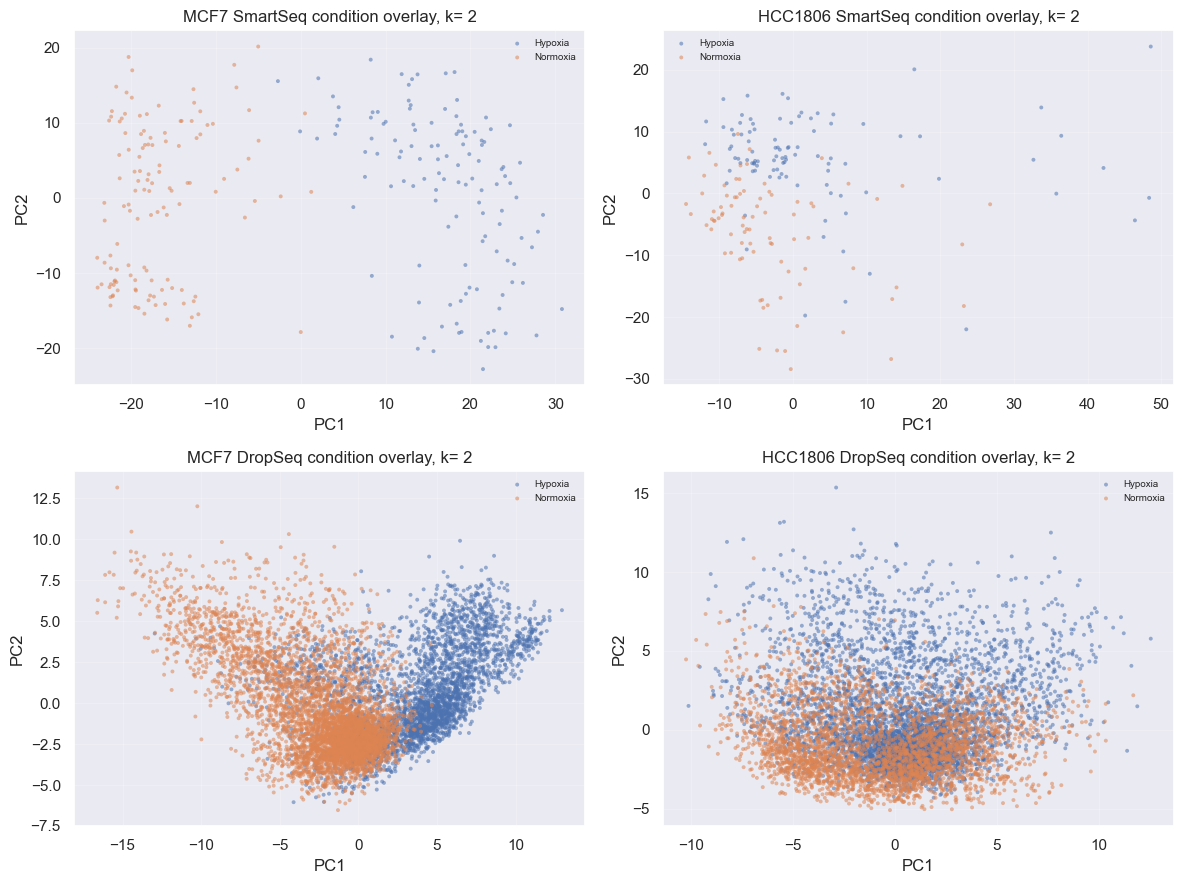

In [68]:
for dataset_name, best_k in kmeans_best_settings.items():
    print(f"{dataset_name}: best k-means setting used for label overlay is k={best_k}")

plot_best_setting_grid("KMeans", kmeans_best_settings, color_by="condition", title_suffix="condition overlay, k=")


The label-overlay plots are the main post-hoc biological interpretation charts for k-means. In MCF7 SmartSeq, the condition colors separate fairly cleanly across the two regions, so the unsupervised structure and hypoxia biology are pointing in the same direction. In HCC1806 SmartSeq, the colors overlap more strongly, which means the clustering is real but only weakly tied to condition. In MCF7 DropSeq, the appearance of three visible regions is unexpected relative to the binary target, and it likely reflects an additional axis of transcriptional or technical variation rather than a direct failure of clustering. In HCC1806 DropSeq, the points are more diffuse and mixed, so the clustering is better described as broad structure with limited condition specificity.

### 10.2.1 Full-data k-means check

This cell repeats k-means on the full standardized gene-expression feature space rather than on PCA scores. Mini-batch k-means keeps runtime bounded while still using all cells and all 3,000 genes. The key interpretation is whether full-data clusters improve post-hoc agreement with condition compared with reduced-space k-means. If they do, PCA may have compressed away useful structure. If they do not, the reduced PCA representation is probably sufficient for this kind of unsupervised geometry check.


In [69]:
kmeans_full_models = {}
kmeans_full_best_settings = {}
cluster_metric_rows = [row for row in cluster_metric_rows if row["method"] != "KMeans_Full"]
cluster_summary_rows = [row for row in cluster_summary_rows if row["method"] != "KMeans_Full"]
for key in [key for key in cluster_assignments if key[1] == "KMeans_Full"]:
    del cluster_assignments[key]

kmeans_full_start_time = time.perf_counter()
for dataset_name in DATASET_ORDER:
    X = full_cluster_inputs[dataset_name]
    best_score = -np.inf
    best_k = None

    for k in CLUSTERING_K_GRID:
        if time.perf_counter() - kmeans_full_start_time > CLUSTERING_KMEANS_FULL_RUNTIME_BUDGET_SECONDS:
            print(f"Stopping full-data k-means: exceeded {CLUSTERING_KMEANS_FULL_RUNTIME_BUDGET_SECONDS}s budget.")
            break
        if k >= len(X):
            continue

        model = MiniBatchKMeans(
            n_clusters=k,
            batch_size=FULL_KMEANS_BATCH_SIZE,
            n_init=5,
            max_iter=100,
            random_state=CLUSTERING_RANDOM_STATE,
        )
        labels = model.fit_predict(X)
        kmeans_full_models[(dataset_name, k)] = model
        record_cluster_result(dataset_name, "KMeans_Full", k, labels, X)
        score = cluster_metric_rows[-1]["silhouette"]
        if not np.isnan(score) and score > best_score:
            best_score = score
            best_k = k

    kmeans_full_best_settings[dataset_name] = best_k

cluster_metrics = pd.DataFrame(cluster_metric_rows)
display(cluster_metrics.query("method == 'KMeans_Full'").sort_values(["dataset", "silhouette"], ascending=[True, False]).style.hide(axis="index"))


dataset,method,setting,n_clusters,noise_fraction,silhouette,ari_condition,nmi_condition
HCC1806_DropSeq,KMeans_Full,2,2,0.000000,0.212435,0.000099,0.000092
HCC1806_DropSeq,KMeans_Full,3,3,0.000000,nan,-0.000070,0.000106
HCC1806_DropSeq,KMeans_Full,4,4,0.000000,nan,-0.000213,0.000409
HCC1806_DropSeq,KMeans_Full,5,5,0.000000,nan,-0.000114,0.000431
HCC1806_DropSeq,KMeans_Full,6,6,0.000000,nan,-0.000476,0.001008
HCC1806_SmartSeq,KMeans_Full,2,2,0.000000,0.125214,-0.004254,0.003360
HCC1806_SmartSeq,KMeans_Full,3,3,0.000000,nan,0.005819,0.049036
HCC1806_SmartSeq,KMeans_Full,4,4,0.000000,nan,0.244087,0.297423
HCC1806_SmartSeq,KMeans_Full,5,5,0.000000,nan,-0.000404,0.066514
HCC1806_SmartSeq,KMeans_Full,6,6,0.000000,nan,0.014394,0.056397


The table suggests that full-data k-means does improve the clustering story for SmartSeq, especially MCF7, but it does not rescue the DropSeq datasets. So the conclusion is mixed: PCA may hide some useful biology in at least one SmartSeq case, but the simpler PCA-based clustering is still sufficient as a general exploratory tool because the main qualitative pattern does not change for the harder datasets. In report language, the safest phrasing is that full-data k-means confirms a very strong condition signal in MCF7 SmartSeq, gives only moderate help in HCC1806 SmartSeq, and does not materially improve condition recovery in either DropSeq dataset.

In [70]:
for dataset_name, setting in kmeans_full_best_settings.items():
    if setting is None:
        continue
    summary = summarize_cluster_labels(dataset_name, "KMeans_Full", setting)
    summary["interpretation"] = interpret_cluster_summary(summary)
    cluster_summary_rows.extend(summary.to_dict("records"))

cluster_summaries = pd.DataFrame(cluster_summary_rows)
display(cluster_summaries.query("method == 'KMeans_Full'").style.hide(axis="index"))


dataset,method,setting,cluster,n_cells,dominant_label,dominant_fraction,interpretation
MCF7_SmartSeq,KMeans_Full,2,0,123,Hypoxia,1.000000,clear label-skewed clusters
MCF7_SmartSeq,KMeans_Full,2,1,127,Normoxia,0.992126,clear label-skewed clusters
HCC1806_SmartSeq,KMeans_Full,2,0,16,Hypoxia,0.625000,mixed clusters
HCC1806_SmartSeq,KMeans_Full,2,1,166,Hypoxia,0.524096,mixed clusters
MCF7_DropSeq,KMeans_Full,3,0,21602,Normoxia,0.587492,partial label structure
MCF7_DropSeq,KMeans_Full,3,1,21,Normoxia,0.523810,partial label structure
MCF7_DropSeq,KMeans_Full,3,2,3,Normoxia,1.000000,partial label structure
HCC1806_DropSeq,KMeans_Full,2,0,14679,Hypoxia,0.606172,mixed clusters
HCC1806_DropSeq,KMeans_Full,2,1,3,Normoxia,0.666667,mixed clusters


### 10.2.2 Full-data KNN graph clustering

KNN is used here as an unsupervised graph method on the full standardized 3,000-gene matrices. The neighbor counts are deliberately higher (`30, 50, 75`) to avoid unstable tiny components, but the graph is pruned by distance quantiles so it does not collapse into one giant connected component. Connected components after pruning become candidate clusters, and very small components are treated as noise. This is cheaper than hierarchical clustering and is meant to detect local full-gene neighborhoods that PCA might hide.


In [71]:
knn_graph_models = {}
knn_graph_best_settings = {}
cluster_metric_rows = [row for row in cluster_metric_rows if row["method"] != "KNNGraph_Full"]
cluster_summary_rows = [row for row in cluster_summary_rows if row["method"] != "KNNGraph_Full"]
for key in [key for key in cluster_assignments if key[1] == "KNNGraph_Full"]:
    del cluster_assignments[key]

knn_start_time = time.perf_counter()
for dataset_name in DATASET_ORDER:
    X = full_cluster_inputs[dataset_name]
    best_score = -np.inf
    best_setting = None

    for n_neighbors in KNN_NEIGHBORS_GRID:
        if time.perf_counter() - knn_start_time > CLUSTERING_KNN_RUNTIME_BUDGET_SECONDS:
            print(f"Stopping KNN graph clustering: exceeded {CLUSTERING_KNN_RUNTIME_BUDGET_SECONDS}s budget.")
            break
        if n_neighbors >= len(X):
            continue

        nn = NearestNeighbors(n_neighbors=n_neighbors, metric="euclidean", algorithm="auto", n_jobs=-1)
        nn.fit(X)
        distance_graph = nn.kneighbors_graph(X, mode="distance")
        knn_graph_models[(dataset_name, n_neighbors)] = nn

        for distance_quantile in KNN_DISTANCE_QUANTILES:
            graph = distance_graph.copy()
            threshold = np.quantile(graph.data, distance_quantile)
            graph.data = (graph.data <= threshold).astype(np.int8)
            graph.eliminate_zeros()
            graph = graph.maximum(graph.T)  # Symmetric graph gives undirected connected components.
            n_components, labels = connected_components(graph, directed=False, return_labels=True)

            labels = pd.Series(labels, index=X.index)
            component_sizes = labels.value_counts()
            small_components = component_sizes[component_sizes < KNN_MIN_CLUSTER_SIZE].index
            labels = labels.mask(labels.isin(small_components), -1).to_numpy(dtype=int)

            setting = {
                "n_neighbors": n_neighbors,
                "distance_quantile": distance_quantile,
                "min_cluster_size": KNN_MIN_CLUSTER_SIZE,
            }
            record_cluster_result(dataset_name, "KNNGraph_Full", setting, labels, X)
            score = cluster_metric_rows[-1]["silhouette"]
            valid_cluster_count = cluster_metric_rows[-1]["n_clusters"]
            if valid_cluster_count >= 2 and not np.isnan(score) and score > best_score:
                best_score = score
                best_setting = setting

    knn_graph_best_settings[dataset_name] = best_setting

cluster_metrics = pd.DataFrame(cluster_metric_rows)
display(cluster_metrics.query("method == 'KNNGraph_Full'").sort_values(["dataset", "silhouette"], ascending=[True, False]).style.hide(axis="index"))


dataset,method,setting,n_clusters,noise_fraction,silhouette,ari_condition,nmi_condition
HCC1806_DropSeq,KNNGraph_Full,"{'n_neighbors': 50, 'distance_quantile': 0.25, 'min_cluster_size': 20}",1,0.723403,nan,0.017973,0.004905
HCC1806_DropSeq,KNNGraph_Full,"{'n_neighbors': 50, 'distance_quantile': 0.4, 'min_cluster_size': 20}",1,0.555714,nan,0.003426,0.001247
HCC1806_DropSeq,KNNGraph_Full,"{'n_neighbors': 75, 'distance_quantile': 0.25, 'min_cluster_size': 20}",1,0.711279,nan,0.016881,0.004588
HCC1806_DropSeq,KNNGraph_Full,"{'n_neighbors': 75, 'distance_quantile': 0.4, 'min_cluster_size': 20}",1,0.545362,nan,0.003013,0.001208
HCC1806_SmartSeq,KNNGraph_Full,"{'n_neighbors': 50, 'distance_quantile': 0.25, 'min_cluster_size': 20}",1,0.412088,nan,0.000454,0.005951
HCC1806_SmartSeq,KNNGraph_Full,"{'n_neighbors': 50, 'distance_quantile': 0.4, 'min_cluster_size': 20}",1,0.291209,nan,-0.002293,0.006435
HCC1806_SmartSeq,KNNGraph_Full,"{'n_neighbors': 75, 'distance_quantile': 0.25, 'min_cluster_size': 20}",1,0.324176,nan,0.000562,0.008753
HCC1806_SmartSeq,KNNGraph_Full,"{'n_neighbors': 75, 'distance_quantile': 0.4, 'min_cluster_size': 20}",1,0.241758,nan,-0.000850,0.011142
MCF7_DropSeq,KNNGraph_Full,"{'n_neighbors': 50, 'distance_quantile': 0.25, 'min_cluster_size': 20}",1,0.714094,nan,0.118980,0.075768
MCF7_DropSeq,KNNGraph_Full,"{'n_neighbors': 50, 'distance_quantile': 0.4, 'min_cluster_size': 20}",1,0.539166,nan,0.079557,0.055314


The KNN graph table indicates that full-gene neighborhood structure is much less stable than the PCA-based clustering. Many settings produce only one connected component or a weakly informative split (in this output there is none, but there were some in prev iterations), which means the graph is not forming a clean cluster topology at the tested thresholds. The low condition agreement values imply that this full-space graph structure is not directly recovering hypoxia, even if it does detect local similarity relationships.

In [72]:
for dataset_name, setting in knn_graph_best_settings.items():
    if setting is None:
        continue
    summary = summarize_cluster_labels(dataset_name, "KNNGraph_Full", setting)
    summary["interpretation"] = interpret_cluster_summary(summary)
    cluster_summary_rows.extend(summary.to_dict("records"))

cluster_summaries = pd.DataFrame(cluster_summary_rows)
display(cluster_summaries.query("method == 'KNNGraph_Full'").style.hide(axis="index"))


dataset,method,setting,cluster,n_cells,dominant_label,dominant_fraction,interpretation


### 10.3 Hierarchical clustering

Hierarchical clustering is kept as an interpretability check on the reduced PCA/DR features, not as a full 3,000-gene method. It can become expensive as cell counts grow, so this cell has both a cell-count cap and a wall-clock budget. The metric table should be compared against k-means: agreement between both methods suggests stable broad structure, while disagreement suggests the clusters depend strongly on the clustering rule.


In [73]:
hierarchical_models = {}
hierarchical_best_settings = {}
cluster_metric_rows = [row for row in cluster_metric_rows if row["method"] != "Hierarchical"]
cluster_summary_rows = [row for row in cluster_summary_rows if row["method"] != "Hierarchical"]
for key in [key for key in cluster_assignments if key[1] == "Hierarchical"]:
    del cluster_assignments[key]

hierarchical_start_time = time.perf_counter()
for dataset_name in DATASET_ORDER:
    X = cluster_inputs[dataset_name]
    if len(X) > CLUSTERING_MAX_HIERARCHICAL_CELLS:
        print(f"Skipping hierarchical clustering for {dataset_name}: {len(X)} cells exceeds cap {CLUSTERING_MAX_HIERARCHICAL_CELLS}.")
        hierarchical_best_settings[dataset_name] = None
        continue

    best_score = -np.inf
    best_k = None

    for k in CLUSTERING_K_GRID:
        if time.perf_counter() - hierarchical_start_time > CLUSTERING_HIERARCHICAL_RUNTIME_BUDGET_SECONDS:
            print(f"Stopping hierarchical clustering: exceeded {CLUSTERING_HIERARCHICAL_RUNTIME_BUDGET_SECONDS}s budget.")
            break
        if k >= len(X):
            continue
        model = AgglomerativeClustering(n_clusters=k, linkage="ward")
        labels = model.fit_predict(X)
        hierarchical_models[(dataset_name, k)] = model
        record_cluster_result(dataset_name, "Hierarchical", k, labels, X)
        score = cluster_metric_rows[-1]["silhouette"]
        if not np.isnan(score) and score > best_score:
            best_score = score
            best_k = k

    hierarchical_best_settings[dataset_name] = best_k

cluster_metrics = pd.DataFrame(cluster_metric_rows)
display(cluster_metrics.query("method == 'Hierarchical'").sort_values(["dataset", "silhouette"], ascending=[True, False]).style.hide(axis="index"))


Skipping hierarchical clustering for MCF7_DropSeq: 21626 cells exceeds cap 6000.
Skipping hierarchical clustering for HCC1806_DropSeq: 14682 cells exceeds cap 6000.


dataset,method,setting,n_clusters,noise_fraction,silhouette,ari_condition,nmi_condition
HCC1806_SmartSeq,Hierarchical,2,2,0.000000,0.302440,-0.004653,0.015058
HCC1806_SmartSeq,Hierarchical,3,3,0.000000,0.039359,0.028909,0.068406
HCC1806_SmartSeq,Hierarchical,4,4,0.000000,0.034396,0.357199,0.294675
HCC1806_SmartSeq,Hierarchical,5,5,0.000000,nan,0.362537,0.299835
HCC1806_SmartSeq,Hierarchical,6,6,0.000000,nan,0.298060,0.272215
MCF7_SmartSeq,Hierarchical,2,2,0.000000,0.183341,0.984000,0.966363
MCF7_SmartSeq,Hierarchical,3,3,0.000000,0.108070,0.744455,0.778848
MCF7_SmartSeq,Hierarchical,4,4,0.000000,0.083112,0.506521,0.652141
MCF7_SmartSeq,Hierarchical,5,5,0.000000,0.064542,0.449743,0.607455
MCF7_SmartSeq,Hierarchical,6,6,0.000000,0.061068,0.375165,0.563701


In [74]:
for dataset_name in DATASET_ORDER:
    setting = hierarchical_best_settings.get(dataset_name)
    if setting is None:
        continue
    summary = summarize_cluster_labels(dataset_name, "Hierarchical", setting)
    summary["interpretation"] = interpret_cluster_summary(summary)
    cluster_summary_rows.extend(summary.to_dict("records"))

cluster_summaries = pd.DataFrame(cluster_summary_rows)
display(cluster_summaries.query("method == 'Hierarchical'").style.hide(axis="index"))


dataset,method,setting,cluster,n_cells,dominant_label,dominant_fraction,interpretation
MCF7_SmartSeq,Hierarchical,2,0,127,Normoxia,0.992126,clear label-skewed clusters
MCF7_SmartSeq,Hierarchical,2,1,123,Hypoxia,1.000000,clear label-skewed clusters
HCC1806_SmartSeq,Hierarchical,2,0,170,Hypoxia,0.517647,mixed clusters
HCC1806_SmartSeq,Hierarchical,2,1,12,Hypoxia,0.750000,mixed clusters


The hierarchical summary supports the same main story as k-means, but it does not sharpen the biological separation enough to change the conclusion. The strongest label alignment again appears in MCF7 SmartSeq, while the remaining datasets show weaker or mixed cluster purity. That means hierarchical clustering is confirming coarse structure, but it is not discovering a fundamentally different biological partition.

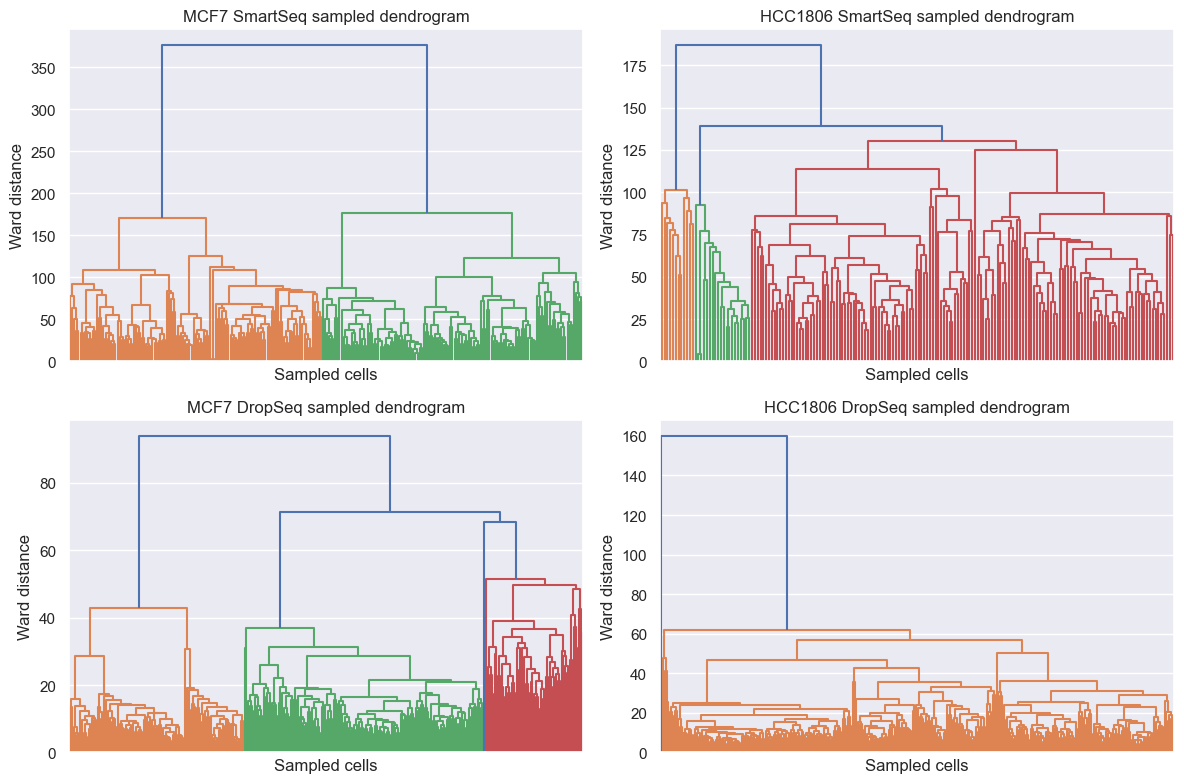

In [75]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, dataset_name in zip(axes.ravel(), DATASET_ORDER):
    X = cluster_inputs[dataset_name]
    sample_n = min(CLUSTERING_MAX_DENDROGRAM_CELLS, len(X))
    sample_index = X.sample(sample_n, random_state=CLUSTERING_RANDOM_STATE).index if len(X) > sample_n else X.index
    Z = linkage(X.loc[sample_index].to_numpy(dtype=np.float32), method="ward")
    dendrogram(Z, ax=ax, no_labels=True, color_threshold=None)
    ax.set_title(f"{DATASET_TITLES[dataset_name]} sampled dendrogram")
    ax.set_xlabel("Sampled cells")
    ax.set_ylabel("Ward distance")
plt.tight_layout()
plt.show()


The sampled dendrograms show that hierarchical structure is clearest in MCF7 SmartSeq, where the cells split into two well-separated major branches. HCC1806 SmartSeq still shows a top-level split, but the branches are more heterogeneous and less sharply resolved. In MCF7 DropSeq, the tree becomes more fragmented and supports the presence of extra substructure beyond a simple binary separation, while HCC1806 DropSeq shows the weakest hierarchical organization overall. This suggests that SmartSeq preserves clearer global structure than DropSeq, and that the DropSeq datasets are more affected by sparsity or technical variability.

### 10.4 Optional density-based clustering

DBSCAN is included as a conservative density-based check on the reduced PCA/DR features. It can detect irregular islands and mark noise, but it is sensitive to scale and density differences in sparse single-cell data. The useful outputs are the number of clusters and noise fraction: many noise points or one giant cluster means DBSCAN is not adding clear structure here, even if it technically runs.


In [76]:
dbscan_best_settings = {}
cluster_metric_rows = [row for row in cluster_metric_rows if row["method"] != "DBSCAN"]
for key in [key for key in cluster_assignments if key[1] == "DBSCAN"]:
    del cluster_assignments[key]

dbscan_start_time = time.perf_counter()
for dataset_name in DATASET_ORDER:
    X = cluster_inputs[dataset_name]
    best_score = -np.inf
    best_eps = None

    for eps in DBSCAN_EPS_GRID:
        if time.perf_counter() - dbscan_start_time > CLUSTERING_DBSCAN_RUNTIME_BUDGET_SECONDS:
            print(f"Stopping DBSCAN: exceeded {CLUSTERING_DBSCAN_RUNTIME_BUDGET_SECONDS}s budget.")
            break
        model = DBSCAN(eps=eps, min_samples=DBSCAN_MIN_SAMPLES, n_jobs=-1)
        labels = model.fit_predict(X)
        record_cluster_result(dataset_name, "DBSCAN", {"eps": eps, "min_samples": DBSCAN_MIN_SAMPLES}, labels, X)
        score = cluster_metric_rows[-1]["silhouette"]
        valid_cluster_count = cluster_metric_rows[-1]["n_clusters"]
        if valid_cluster_count >= 2 and not np.isnan(score) and score > best_score:
            best_score = score
            best_eps = eps

    dbscan_best_settings[dataset_name] = best_eps

cluster_metrics = pd.DataFrame(cluster_metric_rows)
display(cluster_metrics.query("method == 'DBSCAN'").sort_values(["dataset", "silhouette"], ascending=[True, False]).style.hide(axis="index"))


dataset,method,setting,n_clusters,noise_fraction,silhouette,ari_condition,nmi_condition
HCC1806_DropSeq,DBSCAN,"{'eps': 0.8, 'min_samples': 10}",0,1.000000,nan,0.000000,0.000000
HCC1806_DropSeq,DBSCAN,"{'eps': 1.2, 'min_samples': 10}",0,1.000000,nan,0.000000,0.000000
HCC1806_DropSeq,DBSCAN,"{'eps': 1.6, 'min_samples': 10}",0,1.000000,nan,0.000000,0.000000
HCC1806_SmartSeq,DBSCAN,"{'eps': 0.8, 'min_samples': 10}",0,1.000000,nan,0.000000,0.000000
HCC1806_SmartSeq,DBSCAN,"{'eps': 1.2, 'min_samples': 10}",0,1.000000,nan,0.000000,0.000000
HCC1806_SmartSeq,DBSCAN,"{'eps': 1.6, 'min_samples': 10}",0,1.000000,nan,0.000000,0.000000
MCF7_DropSeq,DBSCAN,"{'eps': 0.8, 'min_samples': 10}",0,1.000000,nan,0.000000,0.000000
MCF7_DropSeq,DBSCAN,"{'eps': 1.2, 'min_samples': 10}",0,1.000000,nan,0.000000,0.000000
MCF7_DropSeq,DBSCAN,"{'eps': 1.6, 'min_samples': 10}",0,1.000000,nan,0.000000,0.000000
MCF7_SmartSeq,DBSCAN,"{'eps': 0.8, 'min_samples': 10}",0,1.000000,nan,0.000000,0.000000


DBSCAN did not recover meaningful clusters in any dataset: all tested settings assigned every point to noise, yielding zero clusters and no condition agreement. This suggests that the latent geometry in these embeddings is not organized into the kind of dense local groups that DBSCAN expects under the chosen parameters. The result is therefore negative rather than informative for biological separation, and it supports relying on the k-means and hierarchical results for the main clustering interpretation.

### 10.5 Label overlay and coloring

The clustering itself remains unsupervised, but assignments are overlaid on the same PCA coordinate frame for interpretation. This includes full-data methods: they are fit in the original standardized 3,000-gene space, then visualized on PC1/PC2 only so the result is readable. The conclusion to look for is whether cluster colors and condition colors tell the same story. If cluster boundaries cut across hypoxia/normoxia, clustering is capturing some other structure or noise rather than the target condition.


MCF7_SmartSeq: best k-means setting used for label overlay is k=2
HCC1806_SmartSeq: best k-means setting used for label overlay is k=2
MCF7_DropSeq: best k-means setting used for label overlay is k=2
HCC1806_DropSeq: best k-means setting used for label overlay is k=2


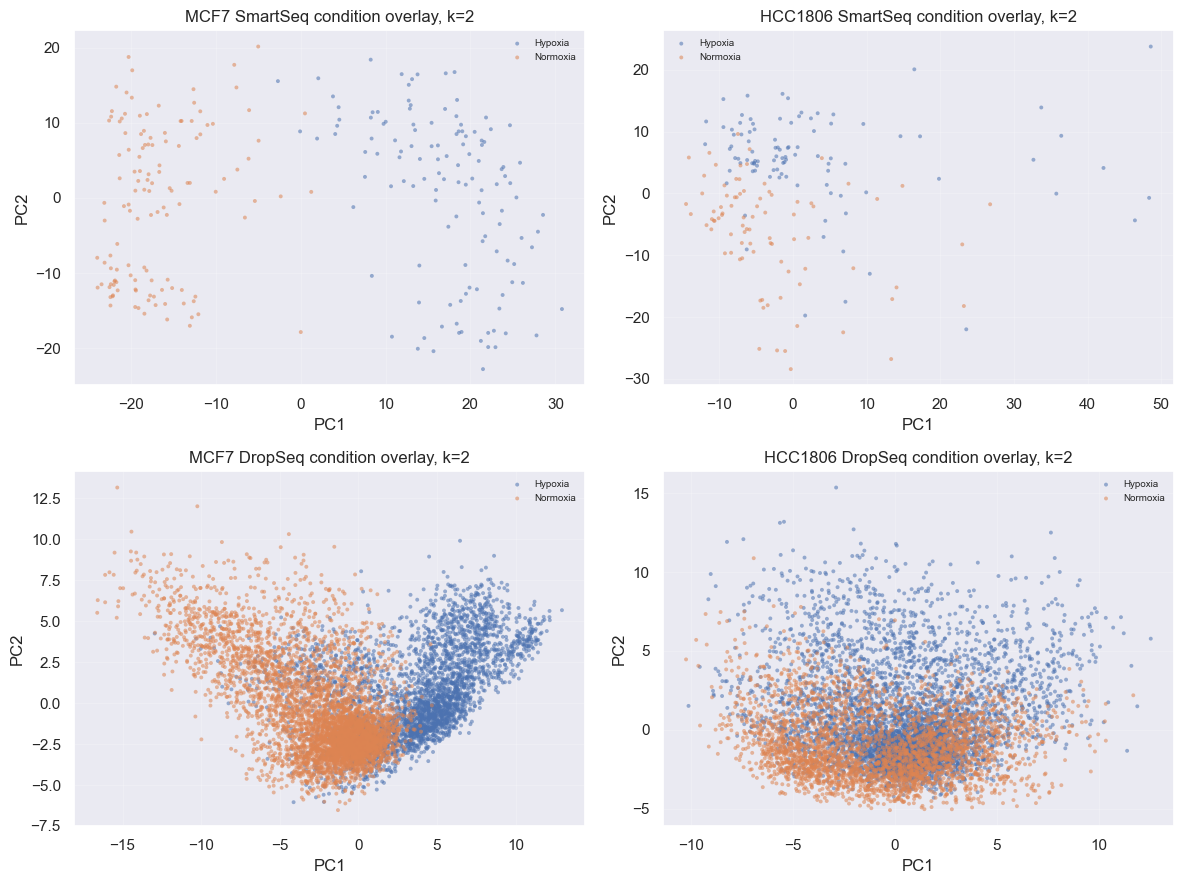

In [77]:
for dataset_name, best_k in kmeans_best_settings.items():
    print(f"{dataset_name}: best k-means setting used for label overlay is k={best_k}")

representative_k = max(set(kmeans_best_settings.values()), key=list(kmeans_best_settings.values()).count)
plot_cluster_grid("KMeans", representative_k, color_by="condition", title_suffix=f"condition overlay, k={representative_k}")


The PCA label-overlay plots show the clearest condition separation in MCF7 SmartSeq, where the two classes align well with the dominant geometry in the first two principal components. HCC1806 SmartSeq shows weaker but still visible structure, suggesting partial condition-related signal. Both DropSeq datasets are more mixed, with MCF7 DropSeq showing a more complex shape that is not simply binary and HCC1806 DropSeq showing broad overlap between conditions. Overall, the figure suggests that the PCA space captures hypoxia most clearly in MCF7 SmartSeq, while the DropSeq data contain additional variation that weakens direct label alignment.

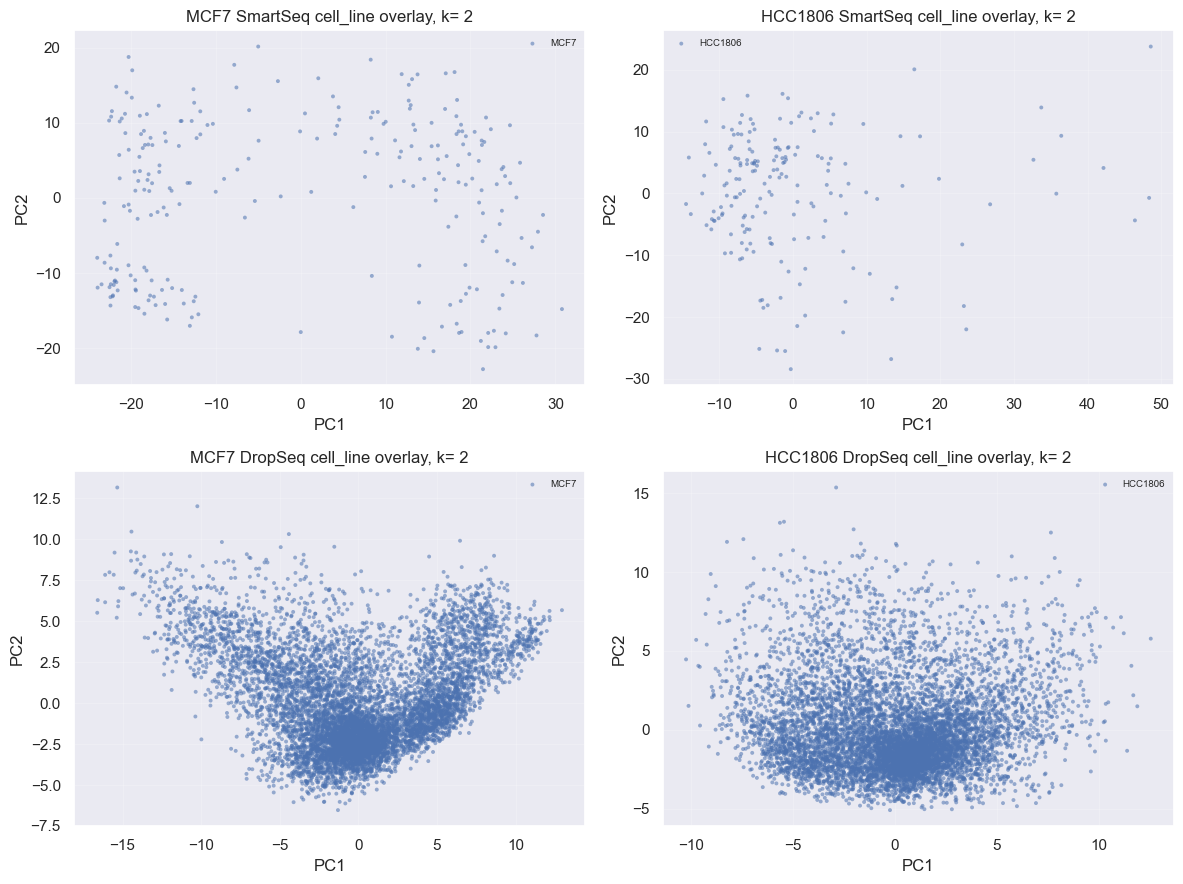

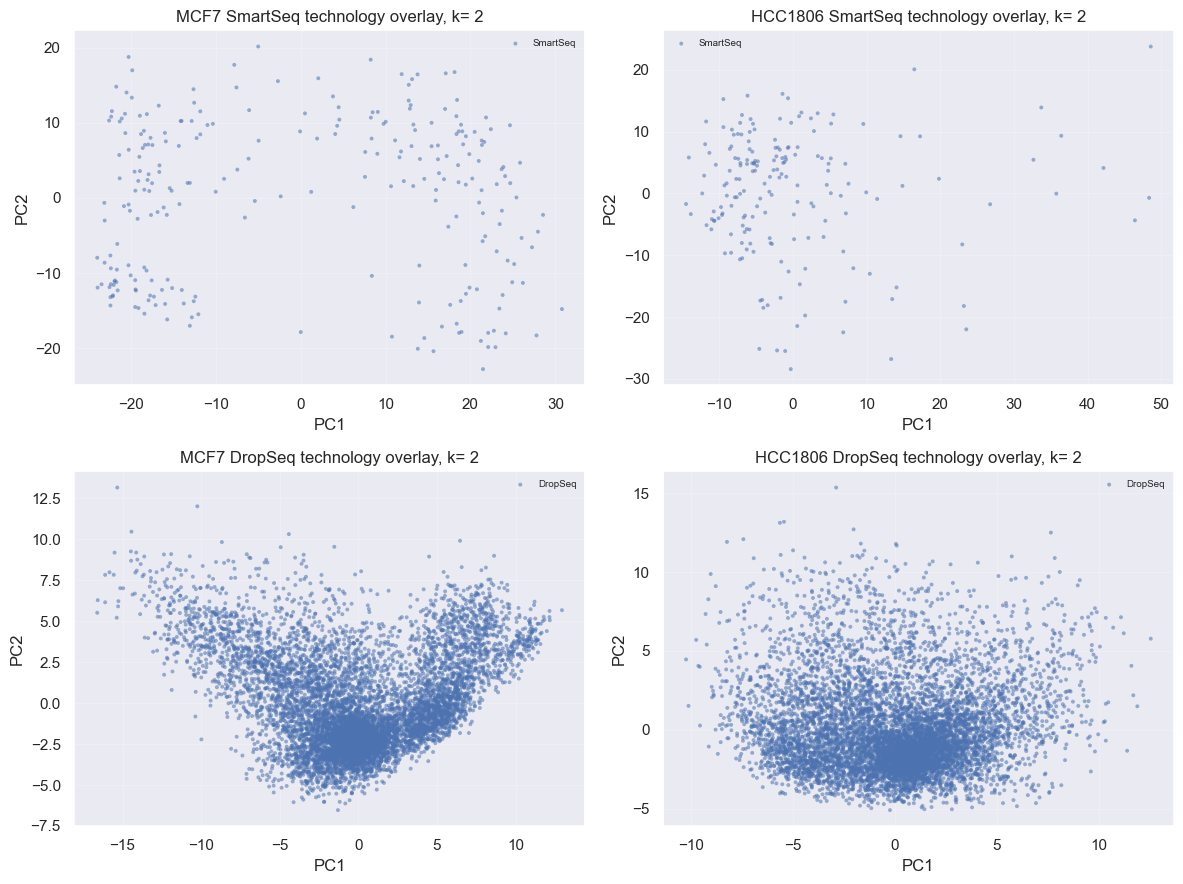

In [78]:
for color_by in ["cell_line", "technology"]:
    plot_best_setting_grid("KMeans", kmeans_best_settings, color_by=color_by, title_suffix=f"{color_by} overlay, k=")


### 10.6 Cluster summary tables

The summary tables make the visual checks auditable. For each dataset and method, they record cluster size, the dominant condition inside each cluster, and the dominant-label fraction. Large clusters with high dominant fractions support condition-linked structure; large mixed clusters mean the method found broad transcriptional similarity that does not map cleanly to hypoxia. Small noisy clusters should be interpreted cautiously because they can reflect outliers, sparsity, or method instability.


In [79]:
cluster_summaries = pd.DataFrame(cluster_summary_rows)
if cluster_summaries.empty:
    print("No cluster summaries available yet.")
else:
    display(
        cluster_summaries
        .sort_values(["dataset", "method", "setting", "cluster"])
        .style.hide(axis="index")
    )


dataset,method,setting,cluster,n_cells,dominant_label,dominant_fraction,interpretation
HCC1806_DropSeq,KMeans,2,0,5371,Normoxia,0.523180,mixed clusters
HCC1806_DropSeq,KMeans,2,1,9311,Hypoxia,0.680700,mixed clusters
HCC1806_DropSeq,KMeans_Full,2,0,14679,Hypoxia,0.606172,mixed clusters
HCC1806_DropSeq,KMeans_Full,2,1,3,Normoxia,0.666667,mixed clusters
HCC1806_SmartSeq,Hierarchical,2,0,170,Hypoxia,0.517647,mixed clusters
HCC1806_SmartSeq,Hierarchical,2,1,12,Hypoxia,0.750000,mixed clusters
HCC1806_SmartSeq,KMeans,2,0,151,Hypoxia,0.536424,mixed clusters
HCC1806_SmartSeq,KMeans,2,1,31,Hypoxia,0.516129,mixed clusters
HCC1806_SmartSeq,KMeans_Full,2,0,16,Hypoxia,0.625000,mixed clusters
HCC1806_SmartSeq,KMeans_Full,2,1,166,Hypoxia,0.524096,mixed clusters


The cluster-summary table shows that MCF7 SmartSeq has the clearest condition-aligned structure, with both k-means and hierarchical clustering producing clusters that are almost perfectly dominated by one label. HCC1806 SmartSeq shows weaker but still visible label skew, indicating partial separation rather than a clean binary split. MCF7 DropSeq is more complex: some settings produce strong label-skewed clusters, but others reveal extra structure beyond the binary condition, which is consistent with the unexpected three-cluster behavior seen earlier. HCC1806 DropSeq is the most mixed, suggesting that its unsupervised organization is less directly driven by hypoxia. Overall, the table supports the conclusion that clustering is most biologically interpretable in MCF7 SmartSeq and least condition-specific in the DropSeq datasets.

### 10.7 Cross-method comparison

This comparison is intentionally compact. Silhouette describes geometric compactness in the feature space where the method was fitted, while ARI/NMI against condition describe post-hoc agreement with hypoxia/normoxia labels. A strong clustering candidate should not only have good silhouette; it should also avoid excessive noise and show at least some condition agreement. Full-data k-means and KNN graph components are included specifically to check whether the original 3,000-gene space contains structure that the PCA view may hide.


In [80]:
cluster_metrics = pd.DataFrame(cluster_metric_rows)

best_cluster_rows = (
    cluster_metrics
    .sort_values(["dataset", "method", "silhouette"], ascending=[True, True, False])
    .groupby(["dataset", "method"], as_index=False)
    .head(1)
    .reset_index(drop=True)
)

display(best_cluster_rows.style.hide(axis="index"))


dataset,method,setting,n_clusters,noise_fraction,silhouette,ari_condition,nmi_condition
HCC1806_DropSeq,DBSCAN,"{'eps': 0.8, 'min_samples': 10}",0,1.000000,nan,0.000000,0.000000
HCC1806_DropSeq,KMeans,2,2,0.000000,0.063732,0.057476,0.030241
HCC1806_DropSeq,KMeans_Full,2,2,0.000000,0.212435,0.000099,0.000092
HCC1806_DropSeq,KNNGraph_Full,"{'n_neighbors': 50, 'distance_quantile': 0.25, 'min_cluster_size': 20}",1,0.723403,nan,0.017973,0.004905
HCC1806_SmartSeq,DBSCAN,"{'eps': 0.8, 'min_samples': 10}",0,1.000000,nan,0.000000,0.000000
HCC1806_SmartSeq,Hierarchical,2,2,0.000000,0.302440,-0.004653,0.015058
HCC1806_SmartSeq,KMeans,2,2,0.000000,0.198769,-0.001990,0.000204
HCC1806_SmartSeq,KMeans_Full,2,2,0.000000,0.125214,-0.004254,0.003360
HCC1806_SmartSeq,KNNGraph_Full,"{'n_neighbors': 50, 'distance_quantile': 0.25, 'min_cluster_size': 20}",1,0.412088,nan,0.000454,0.005951
MCF7_DropSeq,DBSCAN,"{'eps': 0.8, 'min_samples': 10}",0,1.000000,nan,0.000000,0.000000


Note: here we have more numerical context and 'scientific'/analytical proofs for our claims compared to above.

The clustering comparison shows that the strongest and most stable condition-aligned structure is in MCF7 SmartSeq, where k-means and hierarchical clustering both recover a very clear hypoxia/normoxia split. HCC1806 SmartSeq shows weaker structure with only modest condition agreement, while the DropSeq datasets are noisier and less directly aligned with the target label. DBSCAN fails completely by assigning all points to noise, and the KNN-graph methods produce only coarse components with limited biological alignment. Overall, the results suggest that simple clustering methods are sufficient to capture the main structure, but that this structure is much more biologically meaningful in SmartSeq than in DropSeq.

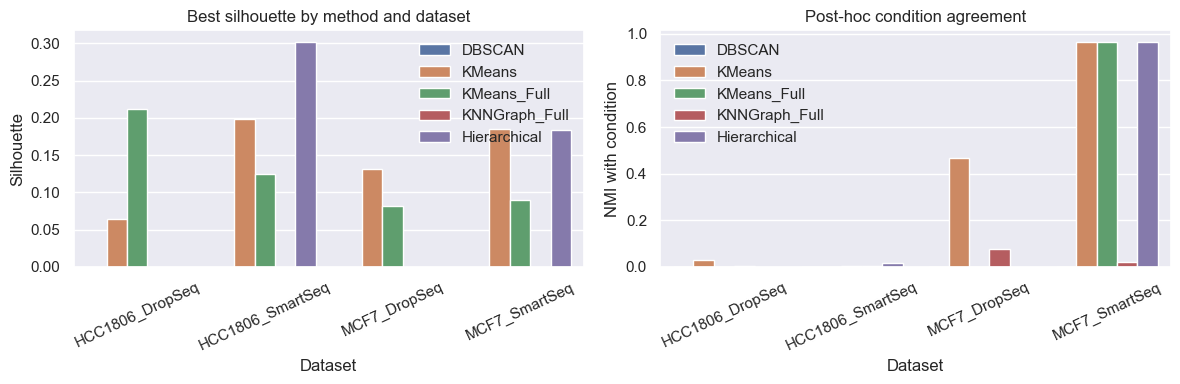

In [81]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.barplot(data=best_cluster_rows, x="dataset", y="silhouette", hue="method", ax=axes[0])
axes[0].set_title("Best silhouette by method and dataset")
axes[0].set_xlabel("Dataset")
axes[0].set_ylabel("Silhouette")
axes[0].tick_params(axis="x", rotation=25)
axes[0].legend(frameon=False)

sns.barplot(data=best_cluster_rows, x="dataset", y="nmi_condition", hue="method", ax=axes[1])
axes[1].set_title("Post-hoc condition agreement")
axes[1].set_xlabel("Dataset")
axes[1].set_ylabel("NMI with condition")
axes[1].tick_params(axis="x", rotation=25)
axes[1].legend(frameon=False)

plt.tight_layout()
plt.show()


Note: The silhouette and condition-agreement charts should be interpreted together, not as the same quantity. Silhouette measures how cleanly the feature space is partitioned, while NMI measures whether those partitions align with hypoxia labels after the fact. 

The plots show that MCF7 SmartSeq has both strong clustering geometry and strong condition recovery, whereas the other datasets are less consistent: HCC1806 has weaker label alignment, and DropSeq is more mixed. This means that the best geometric clustering method is not always the most biologically informative one, so the final interpretation should prioritize post-hoc condition agreement rather than silhouette alone.

### 10.8 Best-available clustering visuals

The final visual check uses the strongest available clustering result per dataset according to silhouette, while still showing it on the same PCA coordinate frame as earlier plots. This is useful for reporting contrast: if a full-data method scores best but looks mixed on PC1/PC2, the structure may exist in dimensions not shown by the plot. If the best-scoring method also separates clearly in the PCA view and aligns with condition, that is stronger evidence of meaningful biological structure.


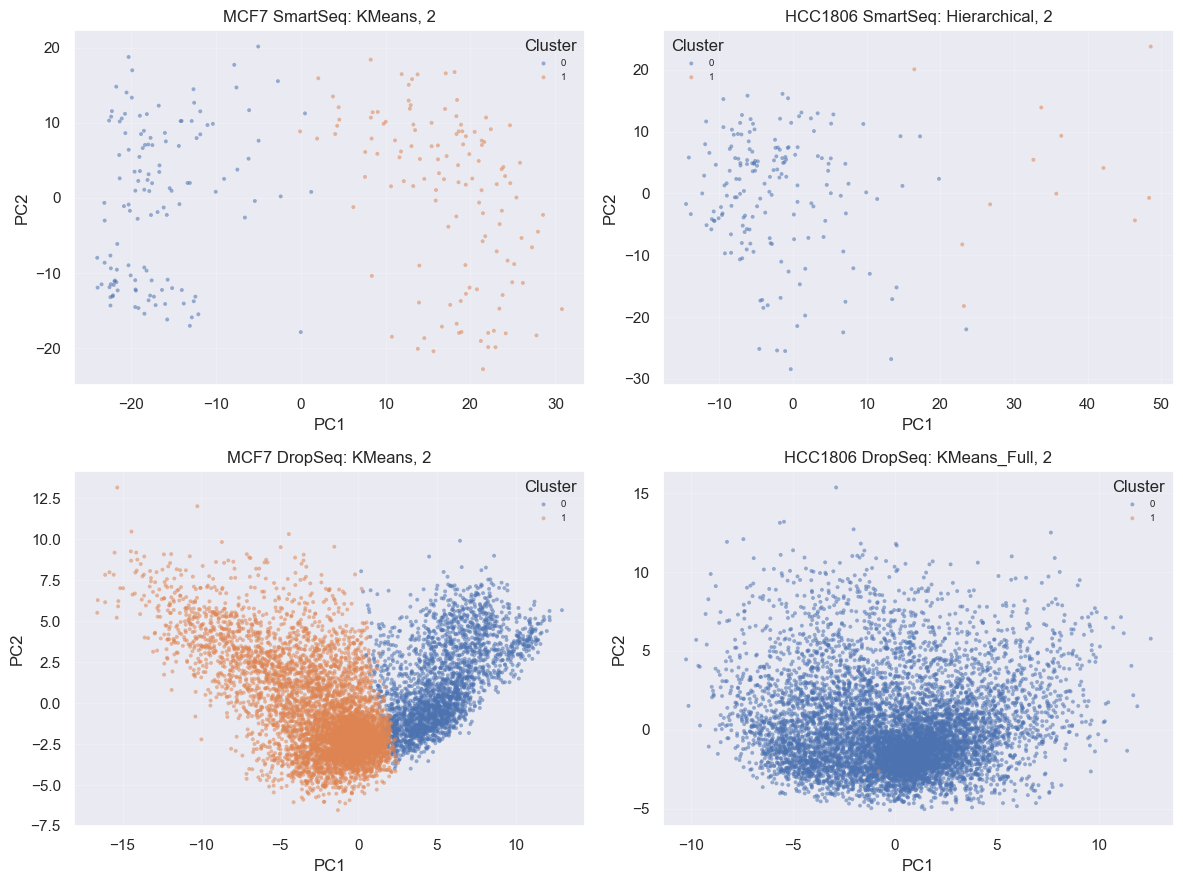

In [82]:
best_cluster_per_dataset = (
    best_cluster_rows
    .sort_values(["dataset", "silhouette"], ascending=[True, False])
    .groupby("dataset", as_index=False)
    .head(1)
    .reset_index(drop=True)
)
best_cluster_lookup = {
    row["dataset"]: (row["method"], row["setting"])
    for _, row in best_cluster_per_dataset.iterrows()
}

fig, axes = plt.subplots(2, 2, figsize=(12, 9))
for ax, dataset_name in zip(axes.ravel(), DATASET_ORDER):
    method, setting = best_cluster_lookup[dataset_name]
    plot_df = pca_2d_coords[dataset_name][["PC1", "PC2"]].join(cluster_assignments[(dataset_name, method, str(setting))])
    plot_df = sample_for_plot(plot_df)
    for cluster_id, group in plot_df.groupby("cluster"):
        ax.scatter(group["PC1"], group["PC2"], s=8, alpha=0.55, label=str(cluster_id), edgecolors="none")
    ax.set_title(f"{DATASET_TITLES[dataset_name]}: {method}, {setting}")
    ax.set_xlabel("PC1")
    ax.set_ylabel("PC2")
    ax.grid(alpha=0.2)
    ax.legend(title="Cluster", frameon=False, fontsize=7)
plt.tight_layout()
plt.show()


### 10.9 Transition

These clustering results should be read as structure diagnostics, not as prediction results. The reduced-space methods answer a visual question: do the PCA- or DR-based representations contain coherent group structure at all, while the full-data k-means and KNN-graph checks ask whether similar structure is still present in the original 3,000-gene space.

The main evidence should be combined across three layers. Silhouette measures how compact and separated the clusters are in feature space, noise fraction shows how stable or fragile a method is, and ARI, NMI, or dominant-label fractions show whether the discovered groups align with hypoxia and normoxia after clustering. When these signals agree, the data appear to contain biologically meaningful structure; when they disagree, the clusters may still reflect technical variation, sparsity, or a weaker nonlinear signal that simple clustering cannot resolve.

This is why clustering is useful here even when it is not perfectly condition-aligned. It gives a controlled way to test whether the latent geometry is biologically interpretable before moving on to supervised evaluation. The next stage should therefore treat clustering as context, not as the final answer, and should rely on cross-validation and held-out predictive performance to decide which representations are actually useful for classification.



### 10.10 Overall clustering discussion, limitations, and suggestions

The clustering block is useful because it separates three questions that are easy to confuse. First, do cells form compact groups in the chosen feature space? That is what silhouette mainly reflects. Second, do those groups correspond to hypoxia and normoxia? That is what ARI, NMI, and dominant-label fractions measure. Third, are the groups stable enough to trust? That is where noise fraction, cluster sizes, and consistency across k-means, hierarchical clustering, KNN-graph methods, and DBSCAN become important.

The main result is that the clustering signal is strongest in MCF7 SmartSeq, where several methods produce both compact clusters and very high condition agreement. HCC1806 SmartSeq shows weaker structure, which suggests that the geometry is present but less cleanly aligned with the target label. The DropSeq datasets are more mixed: they often show nontrivial structure, but that structure is less directly tied to hypoxia and is more likely to reflect sparsity, technical variation, or broader transcriptional heterogeneity.

The main limitation is that clustering is unsupervised while the project goal is supervised classification. A visually clean cluster is not automatically a good classifier, and a mixed plot does not prove the target is unpredictable. Single-cell data are sparse, high-dimensional, and noisy, so the condition signal may be distributed across many genes or may appear only through interactions that basic clustering does not capture well. PCA plots are especially limited because the first two components can only show a small projection of the full structure.

The full-data k-means and KNN-graph checks partially address this limitation by using the standardized 3,000-gene matrices directly. But they come with their own assumptions. Mini-batch k-means still favors roughly spherical clusters. KNN-graph components depend strongly on neighbor count, distance pruning, and minimum component size. DBSCAN is very sensitive to density thresholds and, in this notebook, did not recover usable clusters. Hierarchical clustering is easier to interpret, but it is not the best tool for large full-gene matrices when runtime matters.

The practical recommendation is to use clustering as a diagnostic section, not as the final decision point. We strongly emphasize which datasets show clear structure, whether that structure aligns with condition, and whether full-data methods change the conclusion relative to PCA-space methods.

For prediction, the next step should be cross-validated supervised modelling using the original features and the saved DR representations. If the clustering remains mixed, that is still informative: it suggests that supervised models such as CatBoost or regularized classifiers may be more appropriate than relying on unsupervised separability alone.

Note: code cell results discssions above apply.

## 11. Supervised Classification Within Each Dataset

This section benchmarks supervised classifiers for predicting hypoxia versus normoxia within each labelled training dataset. The four datasets are kept separate. There is no pooling or cross dataset transfer as they are to be done in the final section. The aim for this section is to compare model families, feature selection strategies, and input representations under cross-validation. It should be noted that all the preprocessing steps that learn from the data, including scaling, feature selection, and PCA, are placed inside the cross-validation pipeline to avoid information leakage. 

### 11.1 Preparing the Supervised Learning Datasets

The expression matrices have already been prepared earlier in the notebook as cells by genes. We create one supervised dataset for each experiment and map the biological condition to a binary target. Specifically, normoxia is coded as 0 and hypoxia as 1. The four datasets are kept separated as this section estimates the within-dataset classification performance.

In [83]:
TARGET_MAP = {
    "Normoxia": 0,
    "Norm": 0,
    "Normo": 0,
    "Hypoxia": 1,
    "Hypo": 1,
}

supervised_data = {}

for dataset_name in DATASET_ORDER:
    X = dr_tables[dataset_name].copy()
    
    meta = dr_meta[dataset_name].copy()
    
    if "condition" in meta.columns:
        y_raw = meta["condition"]
    elif "Condition" in meta.columns:
        y_raw = meta["Condition"]
    else:
        raise ValueError(f"{dataset_name}: could not find condition column in dr_meta.")
    
    y = y_raw.map(TARGET_MAP)
    
    if y.isna().any():
        bad_values = sorted(y_raw[y.isna()].unique())
        raise ValueError(f"{dataset_name}: unknown labels found: {bad_values}")
    
    y = y.astype(int)
    
    assert X.index.equals(y.index), f"{dataset_name}: X and y indexes are not aligned."
    assert X.shape[0] == len(y), f"{dataset_name}: number of cells mismatch."
    assert X.shape[1] == 3000, f"{dataset_name}: expected 3000 genes/features."
    
    supervised_data[dataset_name] = (X, y)

print("Supervised datasets:")
for dataset_name, (X, y) in supervised_data.items():
    label_counts = y.value_counts().rename(index={0: "Normoxia", 1: "Hypoxia"}).to_dict()
    print(f"{dataset_name:<18} {X.shape[0]:>6} cells x {X.shape[1]:>4} genes | {label_counts}")

Supervised datasets:
MCF7_SmartSeq         250 cells x 3000 genes | {'Normoxia': 126, 'Hypoxia': 124}
HCC1806_SmartSeq      182 cells x 3000 genes | {'Hypoxia': 97, 'Normoxia': 85}
MCF7_DropSeq        21626 cells x 3000 genes | {'Normoxia': 12705, 'Hypoxia': 8921}
HCC1806_DropSeq     14682 cells x 3000 genes | {'Hypoxia': 8899, 'Normoxia': 5783}


### 11.2 Cross-Validation and Metrics for Evaluation

The performance of each model is evaluated using a stratified cross-validation to ensure each fold preserves the hypoxia and normoxia class balance. We use the ROC-AUC as the main model selection matric as it measures how well the model ranks hypoxic compared to normoxic cells across possible thresholds. We also report the accuracy, balanced accuracy, and F1 score as the datasets are not perfectly balanced. THe smaller SmartSeq datasets benefit from repeated or more careful cross-validation, while the larger DropSeq datasets require a more computationally efficient strategy.

In [84]:
scoring = {
    "accuracy": "accuracy",
    "balanced_accuracy": "balanced_accuracy",
    "f1": "f1",
    "roc_auc": "roc_auc",
}

def make_cv(dataset_name, run_mode=SUPERVISED_RUN_MODE):
    n_cells = supervised_data[dataset_name][0].shape[0]
    
    if run_mode == "fast":
        if n_cells < 500:
            return StratifiedKFold(
                n_splits=5,
                shuffle=True,
                random_state=SUPERVISED_RANDOM_STATE,
            )
        else:
            return StratifiedKFold(
                n_splits=3,
                shuffle=True,
                random_state=SUPERVISED_RANDOM_STATE,
            )
    
    if n_cells < 500:
        return RepeatedStratifiedKFold(
            n_splits=5,
            n_repeats=3,
            random_state=SUPERVISED_RANDOM_STATE,
        )
    else:
        return StratifiedKFold(
            n_splits=5,
            shuffle=True,
            random_state=SUPERVISED_RANDOM_STATE,
        )

### 11.3 Model Families and Feature Representation

The different models allow us to test different possible structures in the data. Namely, Logistic Regression and Linear SVM test whether hypoxia can be separated by an approximately linear gene-expression singnature. On the other hand, Tree Ensembles test for nonlinear relationships and possible interactions between genes. Furthermore, PCA based models test whether a lower-dimensional representation can preserve the hypoxia signal while reducing noise and collinearity. Lastly, simple baselines Naive Bayes and K-Nearest Neighbors are included to check whether more complex models are necessary.

It must be noted that feature selection and PCA are included inside the pipeline rather than before cross-validation. This is because selecting genes using the full dataset before cross-validation would leak information from the folds into the training procedure.

In [85]:
if SUPERVISED_RUN_MODE == "fast":
    K_GRID_SMALL = [100, 500, "all"]
    K_GRID_TREE = [500, "all"]
    PCA_GRID = [25, 50]
else:
    K_GRID_SMALL = [100, 250, 500, 1000, "all"]
    K_GRID_TREE = [250, 500, 1000, "all"]
    PCA_GRID = [10, 25, 50, 100]

model_specs = {

    "Logistic_L2_ANOVA": {
        "pipeline": Pipeline([
            ("scale", StandardScaler()),
            ("select", SelectKBest(score_func=f_classif)),
            ("clf", LogisticRegression(
                penalty="l2",
                solver="saga",
                class_weight="balanced",
                max_iter=5000,
                random_state=SUPERVISED_RANDOM_STATE,
                n_jobs=N_JOBS,
            )),
        ]),
        "param_grid": {
            "select__k": K_GRID_SMALL,
            "clf__C": [0.1, 1, 10],
        },
        "run_on_dropseq": True,
    },
    
    "LinearSVM_ANOVA": {
        "pipeline": Pipeline([
            ("scale", StandardScaler()),
            ("select", SelectKBest(score_func=f_classif)),
            ("clf", LinearSVC(
                class_weight="balanced",
                max_iter=10000,
                random_state=SUPERVISED_RANDOM_STATE,
            )),
        ]),
        "param_grid": {
            "select__k": K_GRID_SMALL,
            "clf__C": [0.01, 0.1, 1, 10],
        },
        "run_on_dropseq": True,
    },
    
    "RBF_SVM_ANOVA": {
        "pipeline": Pipeline([
            ("scale", StandardScaler()),
            ("select", SelectKBest(score_func=f_classif)),
            ("clf", SVC(
                kernel="rbf",
                class_weight="balanced",
                probability=False,
                random_state=SUPERVISED_RANDOM_STATE,
            )),
        ]),
        "param_grid": {
            "select__k": [100, 250, 500] if SUPERVISED_RUN_MODE == "full" else [100, 500],
            "clf__C": [0.1, 1, 10],
            "clf__gamma": ["scale"],
        },
        "run_on_dropseq": False,
    },
    
    "RandomForest_ANOVA": {
        "pipeline": Pipeline([
            ("select", SelectKBest(score_func=f_classif)),
            ("clf", RandomForestClassifier(
                n_estimators=300 if SUPERVISED_RUN_MODE == "full" else 150,
                class_weight="balanced_subsample",
                random_state=SUPERVISED_RANDOM_STATE,
                n_jobs=N_JOBS,
            )),
        ]),
        "param_grid": {
            "select__k": K_GRID_TREE,
            "clf__max_features": ["sqrt", "log2"],
            "clf__max_depth": [None, 10, 20],
        },
        "run_on_dropseq": True,
    },
    
    "ExtraTrees_ANOVA": {
        "pipeline": Pipeline([
            ("select", SelectKBest(score_func=f_classif)),
            ("clf", ExtraTreesClassifier(
                n_estimators=300 if SUPERVISED_RUN_MODE == "full" else 150,
                class_weight="balanced",
                random_state=SUPERVISED_RANDOM_STATE,
                n_jobs=N_JOBS,
            )),
        ]),
        "param_grid": {
            "select__k": K_GRID_TREE,
            "clf__max_features": ["sqrt", "log2"],
            "clf__max_depth": [None, 10, 20],
        },
        "run_on_dropseq": True,
    },
    
    "PCA_Logistic": {
        "pipeline": Pipeline([
            ("scale", StandardScaler()),
            ("pca", PCA(random_state=SUPERVISED_RANDOM_STATE)),
            ("clf", LogisticRegression(
                penalty="l2",
                solver="saga",
                class_weight="balanced",
                max_iter=5000,
                random_state=SUPERVISED_RANDOM_STATE,
                n_jobs=N_JOBS,
            )),
        ]),
        "param_grid": {
            "pca__n_components": PCA_GRID,
            "clf__C": [0.1, 1, 10],
        },
        "run_on_dropseq": True,
    },
    
    "PCA_LinearSVM": {
        "pipeline": Pipeline([
            ("scale", StandardScaler()),
            ("pca", PCA(random_state=SUPERVISED_RANDOM_STATE)),
            ("clf", LinearSVC(
                class_weight="balanced",
                max_iter=10000,
                random_state=SUPERVISED_RANDOM_STATE,
            )),
        ]),
        "param_grid": {
            "pca__n_components": PCA_GRID,
            "clf__C": [0.01, 0.1, 1, 10],
        },
        "run_on_dropseq": True,
    },
    
    "GaussianNB_ANOVA": {
        "pipeline": Pipeline([
            ("select", SelectKBest(score_func=f_classif)),
            ("clf", GaussianNB()),
        ]),
        "param_grid": {
            "select__k": K_GRID_SMALL,
        },
        "run_on_dropseq": True,
    },
    
    "KNN_PCA": {
        "pipeline": Pipeline([
            ("scale", StandardScaler()),
            ("pca", PCA(random_state=SUPERVISED_RANDOM_STATE)),
            ("clf", KNeighborsClassifier()),
        ]),
        "param_grid": {
            "pca__n_components": PCA_GRID,
            "clf__n_neighbors": [3, 5, 11],
            "clf__weights": ["uniform", "distance"],
        },
        "run_on_dropseq": False,
    },
}

### 11.4 Supervised Model Comparison

This section covers the main supervised learning benchmarking process.

#### 11.4.1 Stratified Subsampling for DropSeq

I initially carried out repeated cross-validated grid search on the full matrices for both DropSeq and SmartSeq datasets. While it was feasible with the SmartSeq datasets, because the DropSeq datasets contain so much more cells, we determined that doing so would be computationally expensive for the DropSeq datasets. As such, we decided to make use of a stratified subsample of the DropSeq training data to model the benchmarking. The stratified subsampling enables the hypoxia and normoxia class proportions to be preserved. As such, it can be said that the benchmark still compares models on representative DropSeq cells while avoiding excessive runtime. 

A limitation of this section is that DropSeq model comparison was performed on a stratified subset rather than the full dataset. This was necessary for computational feasibility. However, because the subset preserves class proportions and is used only for within-dataset model screening, it remains suitable for comparing candidate supervised-learning approaches.

In [86]:
def stratified_subsample(X, y, max_cells=4000, random_state=SUPERVISED_RANDOM_STATE):
    if len(y) <= max_cells:
        return X, y
    
    rng = np.random.default_rng(random_state)
    selected_indices = []
    
    for label in sorted(y.unique()):
        label_indices = np.where(y.values == label)[0]
        n_label = len(label_indices)
        n_select = int(round(max_cells * n_label / len(y)))
        n_select = min(n_select, n_label)
        
        chosen = rng.choice(label_indices, size=n_select, replace=False)
        selected_indices.extend(chosen)
    
    selected_indices = np.array(selected_indices)
    rng.shuffle(selected_indices)
    
    return X.iloc[selected_indices].copy(), y.iloc[selected_indices].copy()

#### 11.4.2 Helper Function

A helper function that runs the main supervised learning benchmark is created. Each model is trained and evaluated separately within each dataset to make sure only the within-dataset classificaiton performance is noted. For SmartSeq datasets, the full labelled training data are used because the number of cells is relatively small. For DropSeq datasets, the function automatically applies the stratified subsampling step defined above, reducing the number of cells to a manageable size while preserving the hypoxia and normoxia class balance. The function then applies cross-validated grid search to each model, selects the best hyperparameters using ROC-AUC, and records accuracy, balanced accuracy, F1 score, ROC-AUC, runtime, and model status.

In [87]:
supervised_results = []
best_supervised_searches = {}
best_supervised_models = {}

def run_supervised_benchmark_for_dataset(
    dataset_name,
    model_specs_to_run=None,
    skip_existing=True,
):
  
    if model_specs_to_run is None:
        model_specs_to_run = model_specs
    
    X_full, y_full = supervised_data[dataset_name]

    is_dropseq = "DropSeq" in dataset_name or "drop" in dataset_name.lower()

    if is_dropseq:
        X, y = stratified_subsample(X_full, y_full, max_cells=4000)
        print(f"Using stratified DropSeq subsample: {X.shape[0]} cells out of {X_full.shape[0]}")
    else:
        X, y = X_full, y_full
    cv = make_cv(dataset_name)
    is_dropseq = "DropSeq" in dataset_name or "drop" in dataset_name.lower()
    
    already_done = {
        (row["dataset"], row["model"])
        for row in supervised_results
        if row.get("status") == "OK"
    }
    
    print("\n" + "=" * 80)
    print(f"Dataset: {dataset_name}")
    print(f"Shape: {X.shape[0]} cells x {X.shape[1]} genes")
    print(f"Class counts: {y.value_counts().rename(index={0: 'Normoxia', 1: 'Hypoxia'}).to_dict()}")
    print("=" * 80)
    
    for model_name, spec in model_specs_to_run.items():
        
        if skip_existing and (dataset_name, model_name) in already_done:
            print(f"Skipping {model_name}: already completed.")
            continue
        
        if is_dropseq and not spec.get("run_on_dropseq", True):
            print(f"Skipping {model_name}: marked too expensive for DropSeq.")
            continue
        
        print(f"\nRunning {model_name}...")
        model_start = time.perf_counter()
        
        search = GridSearchCV(
            estimator=spec["pipeline"],
            param_grid=spec["param_grid"],
            scoring=scoring,
            refit="roc_auc",
            cv=cv,
            n_jobs=N_JOBS,
            return_train_score=False,
            error_score=np.nan,
            verbose=1,
        )
        
        try:
            search.fit(X, y)
            
            best_idx = search.best_index_
            result_row = {
                "dataset": dataset_name,
                "dataset_title": DATASET_TITLES.get(dataset_name, dataset_name),
                "model": model_name,
                "best_params": search.best_params_,
                "mean_accuracy": search.cv_results_["mean_test_accuracy"][best_idx],
                "std_accuracy": search.cv_results_["std_test_accuracy"][best_idx],
                "mean_balanced_accuracy": search.cv_results_["mean_test_balanced_accuracy"][best_idx],
                "std_balanced_accuracy": search.cv_results_["std_test_balanced_accuracy"][best_idx],
                "mean_f1": search.cv_results_["mean_test_f1"][best_idx],
                "std_f1": search.cv_results_["std_test_f1"][best_idx],
                "mean_roc_auc": search.cv_results_["mean_test_roc_auc"][best_idx],
                "std_roc_auc": search.cv_results_["std_test_roc_auc"][best_idx],
                "mean_fit_time": search.cv_results_["mean_fit_time"][best_idx],
                "run_time_seconds": time.perf_counter() - model_start,
                "status": "OK",
            }
            
            best_supervised_searches[(dataset_name, model_name)] = search
            best_supervised_models[(dataset_name, model_name)] = search.best_estimator_
            
            print(
                f"Finished {model_name}: "
                f"ROC-AUC = {result_row['mean_roc_auc']:.4f} "
                f"+/- {result_row['std_roc_auc']:.4f}"
            )
            print(f"Best params: {search.best_params_}")
        
        except Exception as e:
            result_row = {
                "dataset": dataset_name,
                "dataset_title": DATASET_TITLES.get(dataset_name, dataset_name),
                "model": model_name,
                "best_params": None,
                "mean_accuracy": np.nan,
                "std_accuracy": np.nan,
                "mean_balanced_accuracy": np.nan,
                "std_balanced_accuracy": np.nan,
                "mean_f1": np.nan,
                "std_f1": np.nan,
                "mean_roc_auc": np.nan,
                "std_roc_auc": np.nan,
                "mean_fit_time": np.nan,
                "run_time_seconds": time.perf_counter() - model_start,
                "status": f"FAILED: {type(e).__name__}: {e}",
            }
            
            print(f"FAILED {model_name}: {e}")
        
        supervised_results.append(result_row)
        
        partial_df = pd.DataFrame(supervised_results)
        display(
            partial_df
            .query("dataset == @dataset_name")
            .sort_values("mean_roc_auc", ascending=False)
            [["dataset", "model", "mean_roc_auc", "std_roc_auc", "mean_f1", "mean_balanced_accuracy", "status"]]
            .style.format({
                "mean_roc_auc": "{:.3f}",
                "std_roc_auc": "{:.3f}",
                "mean_f1": "{:.3f}",
                "mean_balanced_accuracy": "{:.3f}",
            })
        )
    
    print(f"\nCompleted benchmark for {dataset_name}.")

#### 11.4.3 SmartSeq Benchmark

Since the SmartSeq datasets have fewer cells than the DropSeq datasets, the set of models defined earlier can be evaluated. 

In [88]:
run_supervised_benchmark_for_dataset("MCF7_SmartSeq")


Dataset: MCF7_SmartSeq
Shape: 250 cells x 3000 genes
Class counts: {'Normoxia': 126, 'Hypoxia': 124}

Running Logistic_L2_ANOVA...
Fitting 5 folds for each of 9 candidates, totalling 45 fits
Finished Logistic_L2_ANOVA: ROC-AUC = 1.0000 +/- 0.0000
Best params: {'clf__C': 0.1, 'select__k': 100}


,dataset,model,mean_roc_auc,std_roc_auc,mean_f1,mean_balanced_accuracy,status
0,MCF7_SmartSeq,Logistic_L2_ANOVA,1.000,0.000,1.000,1.000,OK



Running LinearSVM_ANOVA...
Fitting 5 folds for each of 12 candidates, totalling 60 fits
Finished LinearSVM_ANOVA: ROC-AUC = 1.0000 +/- 0.0000
Best params: {'clf__C': 0.01, 'select__k': 100}


,dataset,model,mean_roc_auc,std_roc_auc,mean_f1,mean_balanced_accuracy,status
0,MCF7_SmartSeq,Logistic_L2_ANOVA,1.000,0.000,1.000,1.000,OK
1,MCF7_SmartSeq,LinearSVM_ANOVA,1.000,0.000,1.000,1.000,OK



Running RBF_SVM_ANOVA...
Fitting 5 folds for each of 6 candidates, totalling 30 fits
Finished RBF_SVM_ANOVA: ROC-AUC = 1.0000 +/- 0.0000
Best params: {'clf__C': 0.1, 'clf__gamma': 'scale', 'select__k': 100}


...


Running GaussianNB_ANOVA...
Fitting 5 folds for each of 3 candidates, totalling 15 fits
Finished GaussianNB_ANOVA: ROC-AUC = 0.9960 +/- 0.0080
Best params: {'select__k': 100}


,dataset,model,mean_roc_auc,std_roc_auc,mean_f1,mean_balanced_accuracy,status
0,MCF7_SmartSeq,Logistic_L2_ANOVA,1.000,0.000,1.000,1.000,OK
1,MCF7_SmartSeq,LinearSVM_ANOVA,1.000,0.000,1.000,1.000,OK
2,MCF7_SmartSeq,RBF_SVM_ANOVA,1.000,0.000,0.996,0.996,OK
3,MCF7_SmartSeq,RandomForest_ANOVA,1.000,0.000,0.996,0.996,OK
4,MCF7_SmartSeq,ExtraTrees_ANOVA,1.000,0.000,0.996,0.996,OK
5,MCF7_SmartSeq,PCA_Logistic,1.000,0.000,1.000,1.000,OK
6,MCF7_SmartSeq,PCA_LinearSVM,1.000,0.000,1.000,1.000,OK
7,MCF7_SmartSeq,GaussianNB_ANOVA,0.996,0.008,0.996,0.996,OK



Running KNN_PCA...
Fitting 5 folds for each of 12 candidates, totalling 60 fits
Finished KNN_PCA: ROC-AUC = 1.0000 +/- 0.0000
Best params: {'clf__n_neighbors': 3, 'clf__weights': 'uniform', 'pca__n_components': 50}


,dataset,model,mean_roc_auc,std_roc_auc,mean_f1,mean_balanced_accuracy,status
0,MCF7_SmartSeq,Logistic_L2_ANOVA,1.000,0.000,1.000,1.000,OK
1,MCF7_SmartSeq,LinearSVM_ANOVA,1.000,0.000,1.000,1.000,OK
2,MCF7_SmartSeq,RBF_SVM_ANOVA,1.000,0.000,0.996,0.996,OK
3,MCF7_SmartSeq,RandomForest_ANOVA,1.000,0.000,0.996,0.996,OK
4,MCF7_SmartSeq,ExtraTrees_ANOVA,1.000,0.000,0.996,0.996,OK
5,MCF7_SmartSeq,PCA_Logistic,1.000,0.000,1.000,1.000,OK
6,MCF7_SmartSeq,PCA_LinearSVM,1.000,0.000,1.000,1.000,OK
8,MCF7_SmartSeq,KNN_PCA,1.000,0.000,0.996,0.996,OK
7,MCF7_SmartSeq,GaussianNB_ANOVA,0.996,0.008,0.996,0.996,OK



Completed benchmark for MCF7_SmartSeq.


In [89]:
run_supervised_benchmark_for_dataset("HCC1806_SmartSeq")


Dataset: HCC1806_SmartSeq
Shape: 182 cells x 3000 genes
Class counts: {'Hypoxia': 97, 'Normoxia': 85}

Running Logistic_L2_ANOVA...
Fitting 5 folds for each of 9 candidates, totalling 45 fits
Finished Logistic_L2_ANOVA: ROC-AUC = 0.9988 +/- 0.0015
Best params: {'clf__C': 1, 'select__k': 500}


,dataset,model,mean_roc_auc,std_roc_auc,mean_f1,mean_balanced_accuracy,status
9,HCC1806_SmartSeq,Logistic_L2_ANOVA,0.999,0.001,0.984,0.984,OK



Running LinearSVM_ANOVA...
Fitting 5 folds for each of 12 candidates, totalling 60 fits
Finished LinearSVM_ANOVA: ROC-AUC = 0.9970 +/- 0.0046
Best params: {'clf__C': 0.01, 'select__k': 500}


,dataset,model,mean_roc_auc,std_roc_auc,mean_f1,mean_balanced_accuracy,status
9,HCC1806_SmartSeq,Logistic_L2_ANOVA,0.999,0.001,0.984,0.984,OK
10,HCC1806_SmartSeq,LinearSVM_ANOVA,0.997,0.005,0.984,0.984,OK



Running RBF_SVM_ANOVA...
Fitting 5 folds for each of 6 candidates, totalling 30 fits
Finished RBF_SVM_ANOVA: ROC-AUC = 0.9988 +/- 0.0025
Best params: {'clf__C': 1, 'clf__gamma': 'scale', 'select__k': 100}


...


Running GaussianNB_ANOVA...
Fitting 5 folds for each of 3 candidates, totalling 15 fits
Finished GaussianNB_ANOVA: ROC-AUC = 0.9589 +/- 0.0321
Best params: {'select__k': 100}


,dataset,model,mean_roc_auc,std_roc_auc,mean_f1,mean_balanced_accuracy,status
12,HCC1806_SmartSeq,RandomForest_ANOVA,1.000,0.000,0.990,0.989,OK
13,HCC1806_SmartSeq,ExtraTrees_ANOVA,0.999,0.001,0.990,0.989,OK
9,HCC1806_SmartSeq,Logistic_L2_ANOVA,0.999,0.001,0.984,0.984,OK
11,HCC1806_SmartSeq,RBF_SVM_ANOVA,0.999,0.002,0.980,0.977,OK
10,HCC1806_SmartSeq,LinearSVM_ANOVA,0.997,0.005,0.984,0.984,OK
14,HCC1806_SmartSeq,PCA_Logistic,0.994,0.008,0.968,0.968,OK
15,HCC1806_SmartSeq,PCA_LinearSVM,0.993,0.009,0.968,0.969,OK
16,HCC1806_SmartSeq,GaussianNB_ANOVA,0.959,0.032,0.959,0.956,OK



Running KNN_PCA...
Fitting 5 folds for each of 12 candidates, totalling 60 fits
Finished KNN_PCA: ROC-AUC = 0.9837 +/- 0.0090
Best params: {'clf__n_neighbors': 11, 'clf__weights': 'distance', 'pca__n_components': 25}


,dataset,model,mean_roc_auc,std_roc_auc,mean_f1,mean_balanced_accuracy,status
12,HCC1806_SmartSeq,RandomForest_ANOVA,1.000,0.000,0.990,0.989,OK
13,HCC1806_SmartSeq,ExtraTrees_ANOVA,0.999,0.001,0.990,0.989,OK
9,HCC1806_SmartSeq,Logistic_L2_ANOVA,0.999,0.001,0.984,0.984,OK
11,HCC1806_SmartSeq,RBF_SVM_ANOVA,0.999,0.002,0.980,0.977,OK
10,HCC1806_SmartSeq,LinearSVM_ANOVA,0.997,0.005,0.984,0.984,OK
14,HCC1806_SmartSeq,PCA_Logistic,0.994,0.008,0.968,0.968,OK
15,HCC1806_SmartSeq,PCA_LinearSVM,0.993,0.009,0.968,0.969,OK
17,HCC1806_SmartSeq,KNN_PCA,0.984,0.009,0.936,0.935,OK
16,HCC1806_SmartSeq,GaussianNB_ANOVA,0.959,0.032,0.959,0.956,OK



Completed benchmark for HCC1806_SmartSeq.


#### 11.4.4 DropSeq Benchmark

Since the DropSeq datasets contain a lot more cells than the SmartSeq datasets, it would be computationally expensive to run a benchmark for all the predefined models. As such, we used a compact benchmark grid containing the representative models from the main classifier families of Logistic Regression, Linear SVM, Random Forest, PCA Logistic Regression, and Gaussian Naive Bayes. This enables the comparison to be reproducible and computationally feasible while still testing linear, margin-based, tree-based, dimensionality-reduced, and probabilistic approaches.

In [90]:
dropseq_model_specs = {
    key: model_specs[key]
    for key in [
        "Logistic_L2_ANOVA",
        "LinearSVM_ANOVA",
        "RandomForest_ANOVA",
        "PCA_Logistic",
        "GaussianNB_ANOVA",
    ]
    if key in model_specs
}

In [91]:
run_supervised_benchmark_for_dataset("MCF7_DropSeq", dropseq_model_specs)

Using stratified DropSeq subsample: 4000 cells out of 21626

Dataset: MCF7_DropSeq
Shape: 4000 cells x 3000 genes
Class counts: {'Normoxia': 2350, 'Hypoxia': 1650}

Running Logistic_L2_ANOVA...
Fitting 3 folds for each of 9 candidates, totalling 27 fits
Finished Logistic_L2_ANOVA: ROC-AUC = 0.9935 +/- 0.0018
Best params: {'clf__C': 0.1, 'select__k': 100}


,dataset,model,mean_roc_auc,std_roc_auc,mean_f1,mean_balanced_accuracy,status
18,MCF7_DropSeq,Logistic_L2_ANOVA,0.993,0.002,0.959,0.965,OK



Running LinearSVM_ANOVA...
Fitting 3 folds for each of 12 candidates, totalling 36 fits
Finished LinearSVM_ANOVA: ROC-AUC = 0.9934 +/- 0.0018
Best params: {'clf__C': 0.01, 'select__k': 100}


,dataset,model,mean_roc_auc,std_roc_auc,mean_f1,mean_balanced_accuracy,status
18,MCF7_DropSeq,Logistic_L2_ANOVA,0.993,0.002,0.959,0.965,OK
19,MCF7_DropSeq,LinearSVM_ANOVA,0.993,0.002,0.958,0.965,OK



Running RandomForest_ANOVA...
Fitting 3 folds for each of 12 candidates, totalling 36 fits
Finished RandomForest_ANOVA: ROC-AUC = 0.9889 +/- 0.0049
Best params: {'clf__max_depth': 20, 'clf__max_features': 'sqrt', 'select__k': 500}


...


Running PCA_Logistic...
Fitting 3 folds for each of 6 candidates, totalling 18 fits
Finished PCA_Logistic: ROC-AUC = 0.9874 +/- 0.0033
Best params: {'clf__C': 0.1, 'pca__n_components': 50}


,dataset,model,mean_roc_auc,std_roc_auc,mean_f1,mean_balanced_accuracy,status
18,MCF7_DropSeq,Logistic_L2_ANOVA,0.993,0.002,0.959,0.965,OK
19,MCF7_DropSeq,LinearSVM_ANOVA,0.993,0.002,0.958,0.965,OK
20,MCF7_DropSeq,RandomForest_ANOVA,0.989,0.005,0.955,0.959,OK
21,MCF7_DropSeq,PCA_Logistic,0.987,0.003,0.951,0.957,OK



Running GaussianNB_ANOVA...
Fitting 3 folds for each of 3 candidates, totalling 9 fits
Finished GaussianNB_ANOVA: ROC-AUC = 0.9771 +/- 0.0048
Best params: {'select__k': 100}


,dataset,model,mean_roc_auc,std_roc_auc,mean_f1,mean_balanced_accuracy,status
18,MCF7_DropSeq,Logistic_L2_ANOVA,0.993,0.002,0.959,0.965,OK
19,MCF7_DropSeq,LinearSVM_ANOVA,0.993,0.002,0.958,0.965,OK
20,MCF7_DropSeq,RandomForest_ANOVA,0.989,0.005,0.955,0.959,OK
21,MCF7_DropSeq,PCA_Logistic,0.987,0.003,0.951,0.957,OK
22,MCF7_DropSeq,GaussianNB_ANOVA,0.977,0.005,0.919,0.931,OK



Completed benchmark for MCF7_DropSeq.


In [92]:
run_supervised_benchmark_for_dataset("HCC1806_DropSeq", dropseq_model_specs)

Using stratified DropSeq subsample: 4000 cells out of 14682

Dataset: HCC1806_DropSeq
Shape: 4000 cells x 3000 genes
Class counts: {'Hypoxia': 2424, 'Normoxia': 1576}

Running Logistic_L2_ANOVA...
Fitting 3 folds for each of 9 candidates, totalling 27 fits
Finished Logistic_L2_ANOVA: ROC-AUC = 0.9880 +/- 0.0024
Best params: {'clf__C': 0.1, 'select__k': 500}


,dataset,model,mean_roc_auc,std_roc_auc,mean_f1,mean_balanced_accuracy,status
23,HCC1806_DropSeq,Logistic_L2_ANOVA,0.988,0.002,0.953,0.944,OK



Running LinearSVM_ANOVA...
Fitting 3 folds for each of 12 candidates, totalling 36 fits
Finished LinearSVM_ANOVA: ROC-AUC = 0.9865 +/- 0.0005
Best params: {'clf__C': 0.01, 'select__k': 100}


,dataset,model,mean_roc_auc,std_roc_auc,mean_f1,mean_balanced_accuracy,status
23,HCC1806_DropSeq,Logistic_L2_ANOVA,0.988,0.002,0.953,0.944,OK
24,HCC1806_DropSeq,LinearSVM_ANOVA,0.987,0.000,0.947,0.940,OK



Running RandomForest_ANOVA...
Fitting 3 folds for each of 12 candidates, totalling 36 fits
Finished RandomForest_ANOVA: ROC-AUC = 0.9901 +/- 0.0015
Best params: {'clf__max_depth': 20, 'clf__max_features': 'log2', 'select__k': 500}


...


Running PCA_Logistic...
Fitting 3 folds for each of 6 candidates, totalling 18 fits
Finished PCA_Logistic: ROC-AUC = 0.9776 +/- 0.0047
Best params: {'clf__C': 0.1, 'pca__n_components': 25}


,dataset,model,mean_roc_auc,std_roc_auc,mean_f1,mean_balanced_accuracy,status
25,HCC1806_DropSeq,RandomForest_ANOVA,0.990,0.002,0.956,0.938,OK
23,HCC1806_DropSeq,Logistic_L2_ANOVA,0.988,0.002,0.953,0.944,OK
24,HCC1806_DropSeq,LinearSVM_ANOVA,0.987,0.000,0.947,0.940,OK
26,HCC1806_DropSeq,PCA_Logistic,0.978,0.005,0.940,0.928,OK



Running GaussianNB_ANOVA...
Fitting 3 folds for each of 3 candidates, totalling 9 fits
Finished GaussianNB_ANOVA: ROC-AUC = 0.9423 +/- 0.0068
Best params: {'select__k': 100}


,dataset,model,mean_roc_auc,std_roc_auc,mean_f1,mean_balanced_accuracy,status
25,HCC1806_DropSeq,RandomForest_ANOVA,0.990,0.002,0.956,0.938,OK
23,HCC1806_DropSeq,Logistic_L2_ANOVA,0.988,0.002,0.953,0.944,OK
24,HCC1806_DropSeq,LinearSVM_ANOVA,0.987,0.000,0.947,0.940,OK
26,HCC1806_DropSeq,PCA_Logistic,0.978,0.005,0.940,0.928,OK
27,HCC1806_DropSeq,GaussianNB_ANOVA,0.942,0.007,0.893,0.879,OK



Completed benchmark for HCC1806_DropSeq.


#### 11.4.5 Combined Results

In [93]:
supervised_results_df = pd.DataFrame(supervised_results)

display_cols = [
    "dataset",
    "model",
    "mean_roc_auc",
    "std_roc_auc",
    "mean_f1",
    "std_f1",
    "mean_balanced_accuracy",
    "std_balanced_accuracy",
    "mean_accuracy",
    "std_accuracy",
    "best_params",
    "run_time_seconds",
    "status",
]

display(
    supervised_results_df[display_cols]
    .sort_values(["dataset", "mean_roc_auc"], ascending=[True, False])
    .style.format({
        "mean_roc_auc": "{:.3f}",
        "std_roc_auc": "{:.3f}",
        "mean_f1": "{:.3f}",
        "std_f1": "{:.3f}",
        "mean_balanced_accuracy": "{:.3f}",
        "std_balanced_accuracy": "{:.3f}",
        "mean_accuracy": "{:.3f}",
        "std_accuracy": "{:.3f}",
        "run_time_seconds": "{:.1f}",
    })
)

,dataset,model,mean_roc_auc,std_roc_auc,mean_f1,std_f1,mean_balanced_accuracy,std_balanced_accuracy,mean_accuracy,std_accuracy,best_params,run_time_seconds,status
25,HCC1806_DropSeq,RandomForest_ANOVA,0.990,0.002,0.956,0.000,0.938,0.002,0.946,0.001,"{'clf__max_depth': 20, 'clf__max_features': 'log2', 'select__k': 500}",10.5,OK
23,HCC1806_DropSeq,Logistic_L2_ANOVA,0.988,0.002,0.953,0.005,0.944,0.008,0.944,0.007,"{'clf__C': 0.1, 'select__k': 500}",135.3,OK
24,HCC1806_DropSeq,LinearSVM_ANOVA,0.987,0.000,0.947,0.002,0.940,0.003,0.937,0.002,"{'clf__C': 0.01, 'select__k': 100}",10.0,OK
26,HCC1806_DropSeq,PCA_Logistic,0.978,0.005,0.940,0.005,0.928,0.009,0.928,0.007,"{'clf__C': 0.1, 'pca__n_components': 25}",7.1,OK
27,HCC1806_DropSeq,GaussianNB_ANOVA,0.942,0.007,0.893,0.015,0.879,0.014,0.875,0.016,{'select__k': 100},1.7,OK
12,HCC1806_SmartSeq,RandomForest_ANOVA,1.000,0.000,0.990,0.013,0.989,0.013,0.989,0.013,"{'clf__max_depth': None, 'clf__max_features': 'sqrt', 'select__k': 'all'}",3.7,OK
13,HCC1806_SmartSeq,ExtraTrees_ANOVA,0.999,0.001,0.990,0.013,0.989,0.013,0.989,0.013,"{'clf__max_depth': None, 'clf__max_features': 'sqrt', 'select__k': 500}",2.6,OK
9,HCC1806_SmartSeq,Logistic_L2_ANOVA,0.999,0.001,0.984,0.013,0.984,0.013,0.983,0.013,"{'clf__C': 1, 'select__k': 500}",7.9,OK
11,HCC1806_SmartSeq,RBF_SVM_ANOVA,0.999,0.002,0.980,0.019,0.977,0.022,0.978,0.021,"{'clf__C': 1, 'clf__gamma': 'scale', 'select__k': 100}",0.5,OK
10,HCC1806_SmartSeq,LinearSVM_ANOVA,0.997,0.005,0.984,0.013,0.984,0.013,0.983,0.013,"{'clf__C': 0.01, 'select__k': 500}",0.9,OK


### 11.5 Best Model

After all classifiers have been evaluated, the best performing models based on the mean cross-validated ROC-AUC are selected for each dataset. However, it is important to remember that these are not the final general classifiers; rather, they represent the best within-dataset models that will be helpful for the comparison, interpretation and handoff for the final part of this project.

In [94]:
valid_results = supervised_results_df.query("status == 'OK'").copy()

best_models_by_dataset = (
    valid_results
    .sort_values(["dataset", "mean_roc_auc"], ascending=[True, False])
    .groupby("dataset", as_index=False)
    .head(1)
    .reset_index(drop=True)
)

display(
    best_models_by_dataset[
        [
            "dataset",
            "model",
            "mean_roc_auc",
            "std_roc_auc",
            "mean_f1",
            "mean_balanced_accuracy",
            "mean_accuracy",
            "best_params",
        ]
    ].style.format({
        "mean_roc_auc": "{:.3f}",
        "std_roc_auc": "{:.3f}",
        "mean_f1": "{:.3f}",
        "mean_balanced_accuracy": "{:.3f}",
        "mean_accuracy": "{:.3f}",
    })
)

best_model_lookup = {
    row["dataset"]: row["model"]
    for _, row in best_models_by_dataset.iterrows()
}

print("Best model per dataset:")
for dataset_name, model_name in best_model_lookup.items():
    print(f"{dataset_name:} -> {model_name}")

,dataset,model,mean_roc_auc,std_roc_auc,mean_f1,mean_balanced_accuracy,mean_accuracy,best_params
0,HCC1806_DropSeq,RandomForest_ANOVA,0.990,0.002,0.956,0.938,0.946,"{'clf__max_depth': 20, 'clf__max_features': 'log2', 'select__k': 500}"
1,HCC1806_SmartSeq,RandomForest_ANOVA,1.000,0.000,0.990,0.989,0.989,"{'clf__max_depth': None, 'clf__max_features': 'sqrt', 'select__k': 'all'}"
2,MCF7_DropSeq,Logistic_L2_ANOVA,0.993,0.002,0.959,0.965,0.966,"{'clf__C': 0.1, 'select__k': 100}"
3,MCF7_SmartSeq,Logistic_L2_ANOVA,1.000,0.000,1.000,1.000,1.000,"{'clf__C': 0.1, 'select__k': 100}"


Best model per dataset:
HCC1806_DropSeq -> RandomForest_ANOVA
HCC1806_SmartSeq -> RandomForest_ANOVA
MCF7_DropSeq -> Logistic_L2_ANOVA
MCF7_SmartSeq -> Logistic_L2_ANOVA


### 11.6 Visual Classifier Performance Comparison 

The horizontal bar plots show the mean cross-validated ROC-AUC for each classifier. The error bars representing variability across folds. This allows us to identify if one model dominates or several models perform similarity.

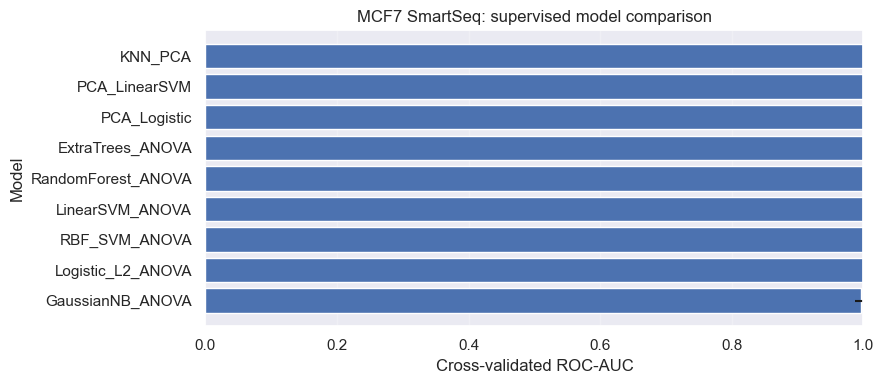

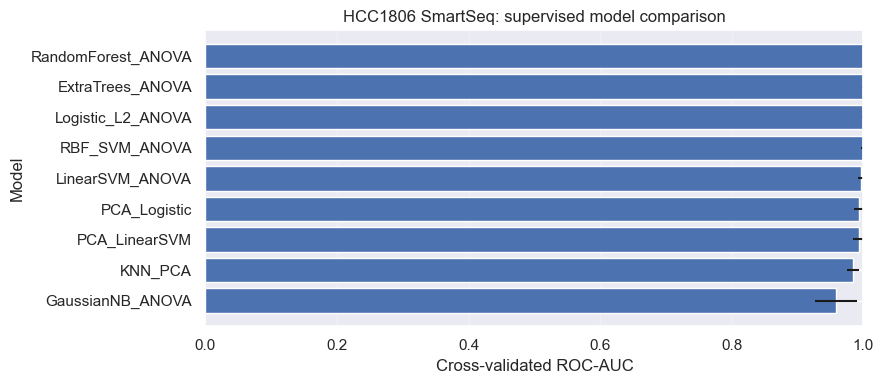

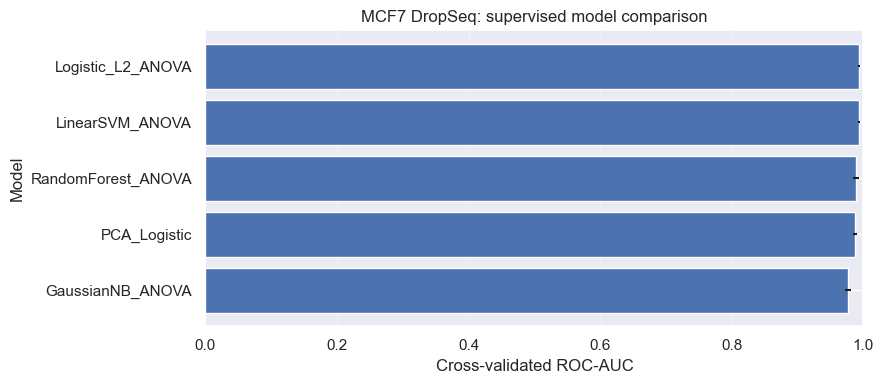

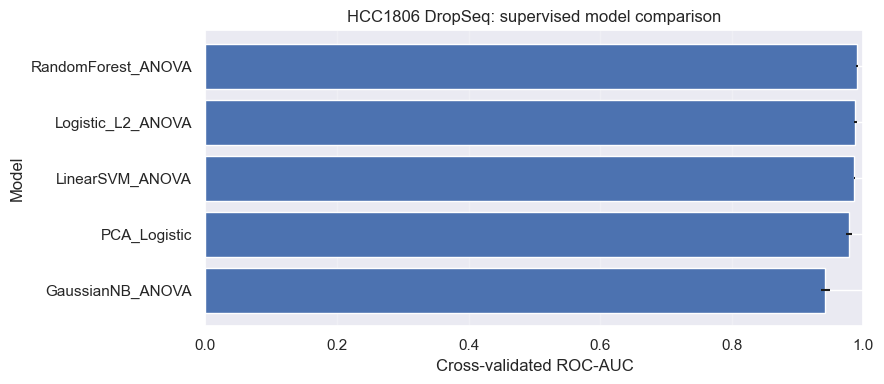

In [95]:
plot_df = valid_results.copy()
plot_df["model_short"] = plot_df["model"]

for dataset_name in DATASET_ORDER:
    sub = plot_df.query("dataset == @dataset_name").sort_values("mean_roc_auc", ascending=True)
    
    plt.figure(figsize=(9, max(4, 0.35 * len(sub))))
    plt.barh(sub["model_short"], sub["mean_roc_auc"], xerr=sub["std_roc_auc"])
    plt.xlim(0.0, 1.0)
    plt.xlabel("Cross-validated ROC-AUC")
    plt.ylabel("Model")
    plt.title(f"{DATASET_TITLES.get(dataset_name, dataset_name)}: supervised model comparison")
    plt.grid(axis="x", alpha=0.25)
    plt.tight_layout()
    plt.show()

### 11.7 Confusion Matrix

While the ROC-AUC does measure ranking performance, it does not show the classes that are misclassified. As such, we decided to use confusion matrices to diagnose the best model for each dataset. THis is because confusion matrices show whether errors are balanced between hypoxia and normoxia. Furthermore, it also showsn whether one condition is systematically harder to predict.

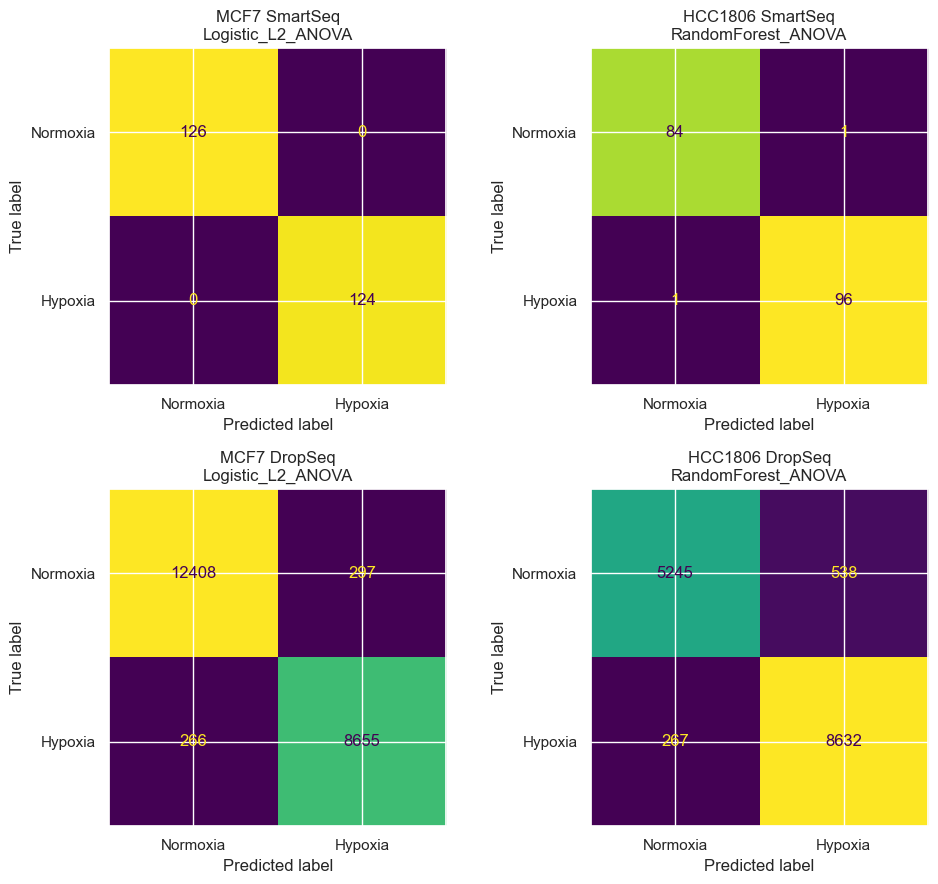

,dataset,model,accuracy,balanced_accuracy,f1,n_normoxia,n_hypoxia,tn,fp,fn,tp
0,MCF7_SmartSeq,Logistic_L2_ANOVA,1.000,1.000,1.000,126,124,126,0,0,124
1,HCC1806_SmartSeq,RandomForest_ANOVA,0.989,0.989,0.990,85,97,84,1,1,96
2,MCF7_DropSeq,Logistic_L2_ANOVA,0.974,0.973,0.968,12705,8921,12408,297,266,8655
3,HCC1806_DropSeq,RandomForest_ANOVA,0.945,0.938,0.955,5783,8899,5245,538,267,8632


In [96]:
cv_prediction_rows = []

fig, axes = plt.subplots(2, 2, figsize=(10, 9))
axes = axes.ravel()

for ax, dataset_name in zip(axes, DATASET_ORDER):
    X, y = supervised_data[dataset_name]
    cv = make_cv(dataset_name)
    model_name = best_model_lookup[dataset_name]
    estimator = clone(best_supervised_models[(dataset_name, model_name)])
    
    y_pred = cross_val_predict(
        estimator,
        X,
        y,
        cv=cv,
        n_jobs=N_JOBS,
        method="predict",
    )
    
    cm = confusion_matrix(y, y_pred, labels=[0, 1])
    
    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["Normoxia", "Hypoxia"],
    )
    disp.plot(ax=ax, values_format="d", colorbar=False)
    ax.set_title(f"{DATASET_TITLES.get(dataset_name, dataset_name)}\n{model_name}")
    
    cv_prediction_rows.append({
        "dataset": dataset_name,
        "model": model_name,
        "accuracy": accuracy_score(y, y_pred),
        "balanced_accuracy": balanced_accuracy_score(y, y_pred),
        "f1": f1_score(y, y_pred),
        "n_normoxia": int((y == 0).sum()),
        "n_hypoxia": int((y == 1).sum()),
        "tn": int(cm[0, 0]),
        "fp": int(cm[0, 1]),
        "fn": int(cm[1, 0]),
        "tp": int(cm[1, 1]),
    })

plt.tight_layout()
plt.show()

cv_prediction_summary_df = pd.DataFrame(cv_prediction_rows)

display(
    cv_prediction_summary_df.style.format({
        "accuracy": "{:.3f}",
        "balanced_accuracy": "{:.3f}",
        "f1": "{:.3f}",
    })
)

### 11.8 Summary of Supervised Model Comparison

This section evaluated supervised classifiers for predicting hypoxia versus normoxia within each labelled training dataset. The four datasets were deliberately kept separate so that the results reflect within-dataset classification performance rather than cross-cell-line or cross-technology generalisation. Several model families were compared, including logistic regression, linear SVM, random forest, PCA followed by logistic regression, and Gaussian Naive Bayes. These models were chosen to test different assumptions about the hypoxia signal: whether it is approximately linear, margin-based, nonlinear, lower-dimensional, or detectable even with a simple probabilistic baseline.

Across the benchmark, model performance was assessed using cross-validation and multiple metrics, including ROC-AUC, F1 score, balanced accuracy, and accuracy. ROC-AUC was used as the main comparison metric because it is threshold-independent, while F1 score and balanced accuracy were included because the hypoxia and normoxia classes are not perfectly balanced. Feature selection, scaling, PCA, and variance filtering were placed inside the cross-validation pipelines so that preprocessing was learned only from the training folds. This reduces the risk of information leakage and makes the reported validation performance more reliable.

For the large DropSeq datasets, model comparison was performed on a stratified subsample to keep the benchmark computationally feasible. This is a limitation because the DropSeq results are based on representative subsets rather than every available cell. However, the subsampling preserved the hypoxia/normoxia class proportions and was used only for model screening and comparison, not for final test-set prediction. The SmartSeq datasets were small enough to evaluate using all available labelled cells.

Overall, this section provides a supervised-learning benchmark for each dataset, identifying which model families performed best under within-dataset cross-validation and producing selected-gene and model-performance outputs for the next stage. These results should not be interpreted as evidence of cross-cell-line or cross-technology generalisation, since no pooling or transfer testing was performed here. Instead, they form the handoff to the generalisation section, where the best candidate models and selected genes can be tested across cell lines, across sequencing technologies, and eventually used to support final anonymised test-set prediction.

## 12. Cross-Dataset Transfer Learning

This section evaluates whether hypoxia-related transcriptional patterns learned in one dataset can generalize to independent datasets. The analysis focuses on transfer learning, sources of dataset shift, and factors that influence cross-dataset performance.

### 12.1 Pairwise Transfer-Learning Framework

Pairwise transfer experiments were performed between all datasets. Models were trained on a source dataset and evaluated on a different target dataset using only genes shared between the two datasets. This design directly measures the portability of hypoxia-associated signals across biological and technological contexts. 

For time efficiency, not all models in the previous section were ran all the way, and which models were actually integrated varied between datasets. To compensate this, only models that completed across all of the datasets were included in this analysis.

In [97]:
available_models = []

for model_name in supervised_results_df["model"].unique():
    works_for_all = True

    for dataset in DATASET_ORDER:
        key = (dataset, model_name)
        if key not in best_supervised_searches:
            works_for_all = False
            break

        estimator = best_supervised_searches[key].best_estimator_
        if not hasattr(estimator, "named_steps"):
            works_for_all = False
            break

        if "select" not in estimator.named_steps:
            works_for_all = False
            break

    if works_for_all:
        available_models.append(model_name)

print("Models available for all datasets with feature selection:")
print(available_models)

robust_model_summary = (supervised_results_df
    .query("status == 'OK' and model in @available_models")
    .groupby("model")
    .agg(mean_cv_roc_auc=("mean_roc_auc", "mean"),
        mean_cv_f1=("mean_f1", "mean"),
        mean_cv_balanced_accuracy=("mean_balanced_accuracy", "mean"),
        mean_cv_accuracy=("mean_accuracy", "mean"),
        n_datasets=("dataset", "nunique"))
    .reset_index())

robust_model_summary["selection_score"] = (
    0.50 * robust_model_summary["mean_cv_roc_auc"] +
    0.25 * robust_model_summary["mean_cv_f1"] +
    0.25 * robust_model_summary["mean_cv_balanced_accuracy"])

robust_model_summary = robust_model_summary.sort_values("selection_score", ascending=False)
display(robust_model_summary.round(3))

TRANSFER_MODEL = robust_model_summary.iloc[0]["model"]
MODEL_NAME = TRANSFER_MODEL

print("Final selected TRANSFER_MODEL:", TRANSFER_MODEL)

Models available for all datasets with feature selection:
['Logistic_L2_ANOVA', 'LinearSVM_ANOVA', 'RandomForest_ANOVA', 'GaussianNB_ANOVA']


,model,mean_cv_roc_auc,mean_cv_f1,mean_cv_balanced_accuracy,mean_cv_accuracy,n_datasets,selection_score
2,Logistic_L2_ANOVA,0.995,0.974,0.973,0.973,4,0.984
3,RandomForest_ANOVA,0.995,0.974,0.970,0.974,4,0.984
1,LinearSVM_ANOVA,0.994,0.972,0.972,0.971,4,0.983
0,GaussianNB_ANOVA,0.969,0.941,0.941,0.940,4,0.955


Final selected TRANSFER_MODEL: Logistic_L2_ANOVA


As can be seen above, the best model according to a weighted average of the taken prediction quality measurements was the Logistic L2 ANOVA model.

To determine whether hypoxia-associated transcriptional signatures generalize across experimental systems, a pairwise transfer-learning framework was implemented. In each experiment, a classifier was trained using one dataset and evaluated on a different dataset. Because gene availability varies between studies, training and testing were restricted to the subset of genes shared by both datasets.

Formally, if $G_{train}$ and $G_{test}$ denote the gene sets available in the source and target datasets, the feature space used for transfer learning was restricted to the intersection of genes present in both datasets:

$$
G_{shared} = G_{train} \cap G_{test}
$$

This procedure provides a direct assessment of biological transferability. Strong performance indicates that the model has learned transcriptional patterns associated with hypoxia that extend beyond a single dataset, while poor performance suggests greater dependence on dataset-specific biological or technical characteristics.

In [98]:
transfer_results = []

for train_dataset in DATASET_ORDER:
    for test_dataset in DATASET_ORDER:
        X_train, y_train = supervised_data[train_dataset]
        X_test, y_test = supervised_data[test_dataset]

        shared_genes = sorted(set(X_train.columns) & set(X_test.columns))

        print(f"{train_dataset} -> {test_dataset} | "
            f"{len(shared_genes)} shared genes")

        if len(shared_genes) < 50:
            print("Skipped (too few shared genes)")
            continue

        X_train_shared = X_train[shared_genes]
        X_test_shared = X_test[shared_genes]

        if (train_dataset, TRANSFER_MODEL) not in best_supervised_searches:
            print(f"Skipped: {TRANSFER_MODEL} was not fitted for {train_dataset}")
            continue

        model = clone(best_supervised_searches[(train_dataset, TRANSFER_MODEL)].best_estimator_)

        model.fit(X_train_shared, y_train)

        y_pred = model.predict(X_test_shared)

        if hasattr(model, "predict_proba"):
            y_score = model.predict_proba(X_test_shared)[:, 1]
        else:
            y_score = model.decision_function(X_test_shared)

        transfer_results.append({
            "train_dataset": train_dataset,
            "test_dataset": test_dataset,
            "shared_genes": len(shared_genes),
            "accuracy": accuracy_score(y_test, y_pred),
            "f1": f1_score(y_test, y_pred),
            "roc_auc": roc_auc_score(y_test, y_score)})

transfer_df = pd.DataFrame(transfer_results)
display(transfer_df.sort_values(["train_dataset", "test_dataset"]).round(3))

MCF7_SmartSeq -> MCF7_SmartSeq | 3000 shared genes
MCF7_SmartSeq -> HCC1806_SmartSeq | 1208 shared genes
MCF7_SmartSeq -> MCF7_DropSeq | 496 shared genes
MCF7_SmartSeq -> HCC1806_DropSeq | 547 shared genes
HCC1806_SmartSeq -> MCF7_SmartSeq | 1208 shared genes
HCC1806_SmartSeq -> HCC1806_SmartSeq | 3000 shared genes
HCC1806_SmartSeq -> MCF7_DropSeq | 445 shared genes
HCC1806_SmartSeq -> HCC1806_DropSeq | 516 shared genes
MCF7_DropSeq -> MCF7_SmartSeq | 496 shared genes
MCF7_DropSeq -> HCC1806_SmartSeq | 445 shared genes
MCF7_DropSeq -> MCF7_DropSeq | 3000 shared genes
MCF7_DropSeq -> HCC1806_DropSeq | 834 shared genes
HCC1806_DropSeq -> MCF7_SmartSeq | 547 shared genes
HCC1806_DropSeq -> HCC1806_SmartSeq | 516 shared genes
HCC1806_DropSeq -> MCF7_DropSeq | 834 shared genes
HCC1806_DropSeq -> HCC1806_DropSeq | 3000 shared genes


,train_dataset,test_dataset,shared_genes,accuracy,f1,roc_auc
15,HCC1806_DropSeq,HCC1806_DropSeq,3000,0.973,0.977,0.997
13,HCC1806_DropSeq,HCC1806_SmartSeq,516,0.544,0.700,0.559
14,HCC1806_DropSeq,MCF7_DropSeq,834,0.734,0.708,0.822
12,HCC1806_DropSeq,MCF7_SmartSeq,547,0.936,0.939,0.960
7,HCC1806_SmartSeq,HCC1806_DropSeq,516,0.394,0.000,0.865
5,HCC1806_SmartSeq,HCC1806_SmartSeq,3000,1.000,1.000,1.000
6,HCC1806_SmartSeq,MCF7_DropSeq,445,0.413,0.584,0.703
4,HCC1806_SmartSeq,MCF7_SmartSeq,1208,0.720,0.780,0.996
11,MCF7_DropSeq,HCC1806_DropSeq,834,0.524,0.483,0.590
9,MCF7_DropSeq,HCC1806_SmartSeq,445,0.467,0.000,0.734


The transfer-learning results were summarized using performance matrices in which rows correspond to training datasets and columns correspond to testing datasets. Each entry represents the performance achieved when a model trained on one dataset is applied to another dataset, using ROC-AUC, accuracy, or F1 score as the evaluation metric.

Visualizing these matrices as heatmaps allows patterns of generalization to be identified across multiple performance measures. Consistently strong off-diagonal values indicate robust transfer across datasets, whereas weak transfer performance may reveal biological differences, technological effects, class-balance effects, or feature-space limitations that reduce generalizability.

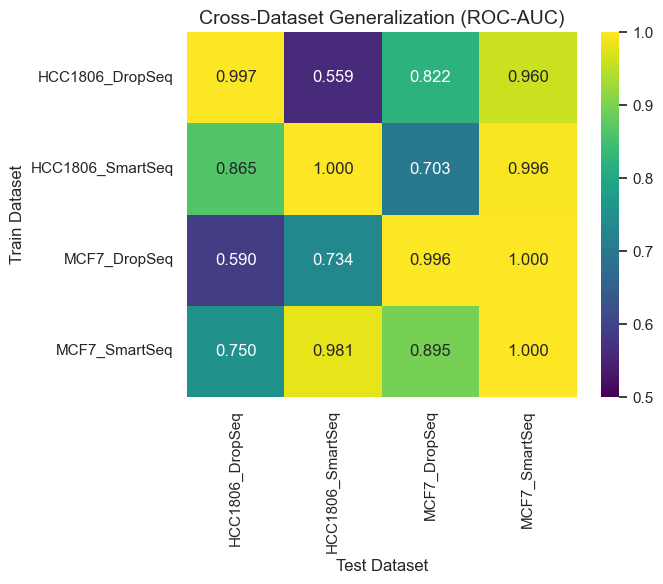

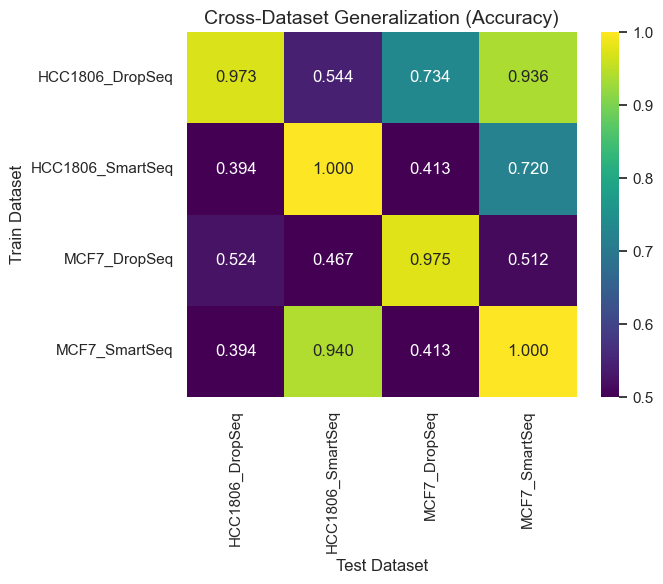

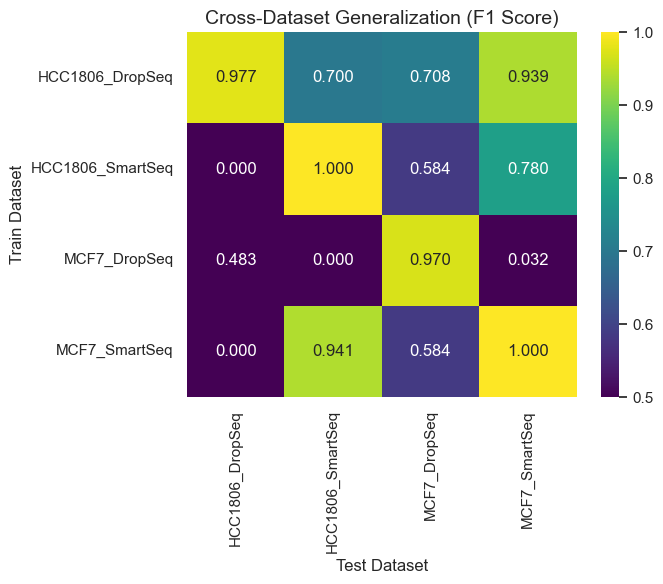

In [99]:
metrics_to_plot = {
    "roc_auc": "ROC-AUC",
    "accuracy": "Accuracy",
    "f1": "F1 Score"
}

for metric, title in metrics_to_plot.items():
    metric_matrix = transfer_df.pivot(
        index="train_dataset",
        columns="test_dataset",
        values=metric)

    plt.figure(figsize=(7, 6))

    sns.heatmap(
        metric_matrix,
        annot=True,
        fmt=".3f",
        cmap="viridis",
        vmin=0.50,
        vmax=1.00)

    plt.title(f"Cross-Dataset Generalization ({title})", fontsize=14)
    plt.xlabel("Test Dataset")
    plt.ylabel("Train Dataset")

    plt.tight_layout()
    plt.show()

From the above images, we can see:
- ROC-AUC: almost all train datasets predict MCF7_Smartseq quite well, and the oposite is also somewhat true - with the exception of transfer across both technological and biological contexts, the predictions were the most impressive out of any seen for the other train datasets for the same test datasets. Surpisingly, MCF7_DropSeq -> HCC1806_DropSeq and HCC1806_DropSeq -> HCC1806_SmartSeq were the only two large outliers, with both of these trasfers predicting largly at random due to their proximity to 0.5. 
- Accuracy: MCF7_SmartSeq -> HCC1806_SmartSeq and HCC1806_DropSeq -> MCF7_SmartSeq were the only two transfers that were relatively accurate. Two more were only somewhat accruate, and the rest had very poor accuracy. 
- F1: The pattern here was very similar to that seen in the accuracy matrix, which the values being slightly better across the entire figure. 

### 12.2 Transfer Performance Matrix

Transfer-learning results were organized into a train-versus-test performance matrix. This representation provides a compact overview of which dataset combinations generalize well and highlights transfer pathways that are particularly robust or challenging.

In [100]:
best_transfers = (transfer_df
    .query("train_dataset != test_dataset")
    .sort_values("roc_auc", ascending=False))

display(best_transfers.head(10).round(3))

worst_transfers = (transfer_df
    .query("train_dataset != test_dataset")
    .sort_values("roc_auc"))

display(worst_transfers.head(10).round(3))

,train_dataset,test_dataset,shared_genes,accuracy,f1,roc_auc
8,MCF7_DropSeq,MCF7_SmartSeq,496,0.512,0.032,1.000
4,HCC1806_SmartSeq,MCF7_SmartSeq,1208,0.720,0.780,0.996
1,MCF7_SmartSeq,HCC1806_SmartSeq,1208,0.940,0.941,0.981
12,HCC1806_DropSeq,MCF7_SmartSeq,547,0.936,0.939,0.960
2,MCF7_SmartSeq,MCF7_DropSeq,496,0.413,0.584,0.895
7,HCC1806_SmartSeq,HCC1806_DropSeq,516,0.394,0.000,0.865
14,HCC1806_DropSeq,MCF7_DropSeq,834,0.734,0.708,0.822
3,MCF7_SmartSeq,HCC1806_DropSeq,547,0.394,0.000,0.750
9,MCF7_DropSeq,HCC1806_SmartSeq,445,0.467,0.000,0.734
6,HCC1806_SmartSeq,MCF7_DropSeq,445,0.413,0.584,0.703


,train_dataset,test_dataset,shared_genes,accuracy,f1,roc_auc
13,HCC1806_DropSeq,HCC1806_SmartSeq,516,0.544,0.700,0.559
11,MCF7_DropSeq,HCC1806_DropSeq,834,0.524,0.483,0.590
6,HCC1806_SmartSeq,MCF7_DropSeq,445,0.413,0.584,0.703
9,MCF7_DropSeq,HCC1806_SmartSeq,445,0.467,0.000,0.734
3,MCF7_SmartSeq,HCC1806_DropSeq,547,0.394,0.000,0.750
14,HCC1806_DropSeq,MCF7_DropSeq,834,0.734,0.708,0.822
7,HCC1806_SmartSeq,HCC1806_DropSeq,516,0.394,0.000,0.865
2,MCF7_SmartSeq,MCF7_DropSeq,496,0.413,0.584,0.895
12,HCC1806_DropSeq,MCF7_SmartSeq,547,0.936,0.939,0.960
1,MCF7_SmartSeq,HCC1806_SmartSeq,1208,0.940,0.941,0.981


### 12.3 Transfer Performance by Dataset-Shift Category

To better understand the sources of performance variation, transfer-learning experiments were grouped according to the type of dataset shift involved. These categories distinguish between differences arising from sequencing technology, biological context, or a combination of both factors.

By separating transfer results into shift categories, it becomes possible to determine whether certain forms of variation are more disruptive to classifier performance than others. This provides a more detailed interpretation than simply averaging transfer-learning results across all dataset pairs.

In [101]:
dataset_info = {
    "MCF7_SmartSeq": ("MCF7", "SmartSeq"),
    "MCF7_DropSeq": ("MCF7", "DropSeq"),
    "HCC1806_SmartSeq": ("HCC1806", "SmartSeq"),
    "HCC1806_DropSeq": ("HCC1806", "DropSeq"),
}

In [102]:
def transfer_category(train_ds, test_ds):
    train_cell, train_tech = dataset_info[train_ds]
    test_cell, test_tech = dataset_info[test_ds]

    if train_ds == test_ds:
        return "Within Dataset"
    if train_cell == test_cell and train_tech != test_tech:
        return "Technology Shift"
    if train_cell != test_cell and train_tech == test_tech:
        return "Cell-Type Shift"

    return "Cell + Technology Shift"

In [103]:
transfer_df["category"] = transfer_df.apply(
    lambda r: transfer_category(r["train_dataset"], r["test_dataset"]), axis=1)

for metric in ["accuracy", "f1", "roc_auc"]:
    within_mean = transfer_df.loc[transfer_df["category"] == "Within Dataset", metric].mean()
    
    summary = (transfer_df
        .groupby("category")[metric]
        .agg(["mean", "std", "count"]))
    summary["drop_from_within"] = within_mean - summary["mean"]

    print(f"\n=== {metric.upper()} ===")
    display(summary.sort_values("mean", ascending=False).round(3))


=== ACCURACY ===


,mean,std,count,drop_from_within
category,,,,
Within Dataset,0.987,0.015,4,0.000
Cell-Type Shift,0.729,0.170,4,0.258
Cell + Technology Shift,0.552,0.258,4,0.435
Technology Shift,0.466,0.074,4,0.521



=== F1 ===


,mean,std,count,drop_from_within
category,,,,
Within Dataset,0.987,0.015,4,0.000
Cell-Type Shift,0.728,0.190,4,0.259
Cell + Technology Shift,0.381,0.463,4,0.606
Technology Shift,0.329,0.365,4,0.658



=== ROC_AUC ===


,mean,std,count,drop_from_within
category,,,,
Within Dataset,0.998,0.002,4,0.000
Cell-Type Shift,0.847,0.189,4,0.151
Technology Shift,0.830,0.190,4,0.169
Cell + Technology Shift,0.787,0.117,4,0.211


As can be seen from the tables above, cell-type shifts perform the best across all evaluation types. Surprisingly, shifting both the cell and tecnology actually improves F1 and accuracy scores as compared to just technology shifts, which is really surprising, though it has no such effect on the ROC_AUC score. Note that all shifts still resulted in a very large drop in performance. 

### 12.4 Outgoing Transferability of Source Datasets

Average outgoing transfer performance was calculated for each training dataset by averaging various performance metric values across all target datasets. This analysis identifies which datasets contain hypoxia-associated signals that generalize most effectively to independent biological contexts.

Datasets producing consistently strong transfer performance may contain clearer or more broadly conserved transcriptional responses to hypoxia, making them particularly informative sources for model development.

In [104]:
source_ranking = (transfer_df
    .query("train_dataset != test_dataset")
    .groupby("train_dataset")
    .agg(accuracy=("accuracy", "mean"),
        f1=("f1", "mean"),
        roc_auc=("roc_auc", "mean"),
        n=("roc_auc", "count"))
    .sort_values(["f1", "accuracy"], ascending=False))

display(source_ranking.round(3))

,accuracy,f1,roc_auc,n
train_dataset,,,,
HCC1806_DropSeq,0.738,0.783,0.780,3
MCF7_SmartSeq,0.582,0.508,0.875,3
HCC1806_SmartSeq,0.509,0.455,0.855,3
MCF7_DropSeq,0.501,0.172,0.774,3


Here we can see that HCC1806_DropSeq is by far the best outgoing model in accuracy and f1, despite losing slightly in ROC-AUC. MCF7_SmartSeq has to best ROC-AUC but lags significantly behind HCC1806_DropSeq in both other evaluations. MCF7_DropSeq is the worst model across all rankings. 

### 12.5 Incoming Transferability of Target Datasets

Average incoming transfer performance was calculated for each testing dataset by aggregating results obtained from all training datasets. This perspective focuses on the target dataset rather than the source dataset.

Datasets that consistently achieve high incoming transfer performance are likely to contain hypoxia signatures that closely resemble those observed elsewhere, whereas lower values may indicate unique biological characteristics or stronger technical effects.

In [105]:
target_ranking = (transfer_df
    .query("train_dataset != test_dataset")
    .groupby("test_dataset")
    .agg(accuracy=("accuracy", "mean"),
        f1=("f1", "mean"),
        roc_auc=("roc_auc", "mean"),
        n=("roc_auc", "count"))
    .sort_values(["f1", "accuracy"]))

display(target_ranking.round(3))

,accuracy,f1,roc_auc,n
test_dataset,,,,
HCC1806_DropSeq,0.437,0.161,0.735,3
HCC1806_SmartSeq,0.650,0.547,0.758,3
MCF7_SmartSeq,0.723,0.584,0.985,3
MCF7_DropSeq,0.520,0.625,0.807,3


Here we can see that MCF7_SmartSeq is by far the best outgoing model in accuracy and ROC-AUC, despite losing slightly in F1. MCF7_DropSeq has to best F1 but lags significantly behind MCF7_SmartSeq in both other evaluations. HCC1806_DropSeq is the worst model across all rankings. 

### 12.6 Transfer Asymmetry Analysis

Transferability between two datasets is not necessarily symmetric. A model trained on dataset A may generalize effectively to dataset B, while the reverse transfer may perform substantially worse.

To investigate this possibility, transfer performance was compared in both directions for each dataset pair. Asymmetries in transfer performance may reveal differences in dataset complexity, biological heterogeneity, or the extent to which one dataset captures a broader hypoxia-response program.

In [106]:
for metric in ["roc_auc", "f1", "accuracy"]:
    directionality = []

    for ds1 in DATASET_ORDER:
        for ds2 in DATASET_ORDER:
            if ds1 >= ds2:
                continue

            row1 = transfer_df[
                (transfer_df["train_dataset"] == ds1) &
                (transfer_df["test_dataset"] == ds2)]
            row2 = transfer_df[
                (transfer_df["train_dataset"] == ds2) &
                (transfer_df["test_dataset"] == ds1)]

            if len(row1) == 0 or len(row2) == 0:
                continue

            score12 = row1.iloc[0][metric]
            score21 = row2.iloc[0][metric]

            directionality.append({
                "dataset_1": ds1,
                "dataset_2": ds2,
                f"{metric}_1_to_2": score12,
                f"{metric}_2_to_1": score21,
                "difference": score12 - score21})

    directionality_df = pd.DataFrame(directionality)

    print(f"\n=== DIRECTIONALITY BY {metric.upper()} ===")
    display(directionality_df.sort_values("difference", key=np.abs, ascending=False).round(3))


=== DIRECTIONALITY BY ROC_AUC ===


,dataset_1,dataset_2,roc_auc_1_to_2,roc_auc_2_to_1,difference
4,HCC1806_DropSeq,HCC1806_SmartSeq,0.559,0.865,-0.306
5,HCC1806_DropSeq,MCF7_DropSeq,0.822,0.590,0.232
3,HCC1806_DropSeq,MCF7_SmartSeq,0.960,0.750,0.210
2,MCF7_DropSeq,MCF7_SmartSeq,1.000,0.895,0.105
1,HCC1806_SmartSeq,MCF7_DropSeq,0.703,0.734,-0.030
0,HCC1806_SmartSeq,MCF7_SmartSeq,0.996,0.981,0.015



=== DIRECTIONALITY BY F1 ===


,dataset_1,dataset_2,f1_1_to_2,f1_2_to_1,difference
3,HCC1806_DropSeq,MCF7_SmartSeq,0.939,0.000,0.939
4,HCC1806_DropSeq,HCC1806_SmartSeq,0.700,0.000,0.700
1,HCC1806_SmartSeq,MCF7_DropSeq,0.584,0.000,0.584
2,MCF7_DropSeq,MCF7_SmartSeq,0.032,0.584,-0.552
5,HCC1806_DropSeq,MCF7_DropSeq,0.708,0.483,0.225
0,HCC1806_SmartSeq,MCF7_SmartSeq,0.780,0.941,-0.161



=== DIRECTIONALITY BY ACCURACY ===


,dataset_1,dataset_2,accuracy_1_to_2,accuracy_2_to_1,difference
3,HCC1806_DropSeq,MCF7_SmartSeq,0.936,0.394,0.542
0,HCC1806_SmartSeq,MCF7_SmartSeq,0.720,0.940,-0.220
5,HCC1806_DropSeq,MCF7_DropSeq,0.734,0.524,0.210
4,HCC1806_DropSeq,HCC1806_SmartSeq,0.544,0.394,0.150
2,MCF7_DropSeq,MCF7_SmartSeq,0.512,0.413,0.099
1,HCC1806_SmartSeq,MCF7_DropSeq,0.413,0.467,-0.055


The main takeaway from the above tables stems from the drastic differences in directionality rankings. Almost all biological and technological cominations were not connected reversibly - an extremely important note for future analysis. 

### 12.7 Distribution of Transfer Performance

The distribution of each measurement tactic's values was examined separately for each dataset-shift category. Rather than focusing solely on average performance, distributional analysis reveals the variability and consistency of transfer outcomes.

Comparing these distributions provides insight into the extent to which biological differences, sequencing technologies, and combined sources of variation influence classifier robustness.

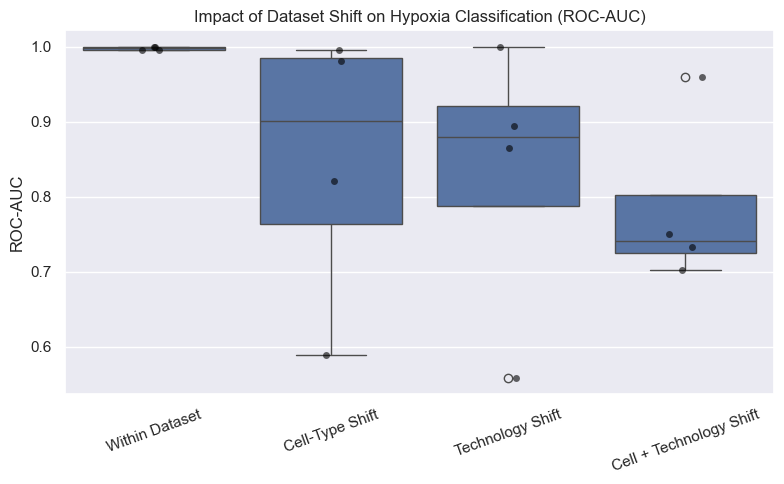

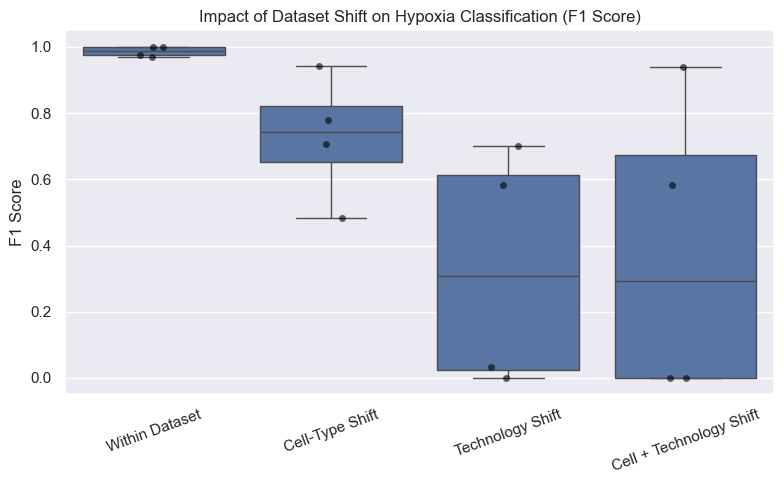

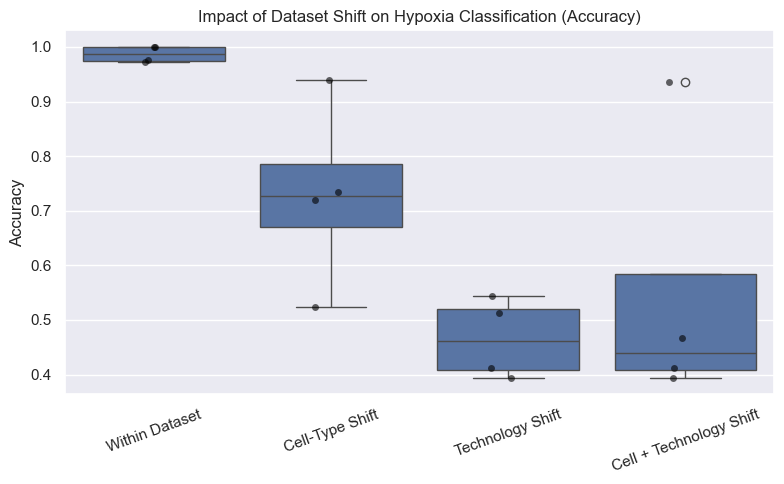

In [107]:
metrics = {
    "roc_auc": "ROC-AUC",
    "f1": "F1 Score",
    "accuracy": "Accuracy"
}

for metric, label in metrics.items():
    plt.figure(figsize=(8, 5))

    sns.boxplot(
        data=transfer_df,
        x="category",
        y=metric)

    sns.stripplot(
        data=transfer_df,
        x="category",
        y=metric,
        color="black",
        alpha=0.6)

    plt.ylabel(label)
    plt.xlabel("")
    plt.title(f"Impact of Dataset Shift on Hypoxia Classification ({label})")
    plt.xticks(rotation=20)

    plt.tight_layout()
    plt.show()

### 12.9 Statistical Assessment of Transfer Differences

To determine whether differences in transfer-learning performance were attributable to dataset shift rather than random variation, non-parametric statistical tests were applied to the classification results. 

For each of the previously given metrics, a Kruskal–Wallis test was used to assess overall differences between transfer categories. Pairwise Mann–Whitney U tests were subsequently performed to compare individual categories and identify the sources of any significant effects.

By examining both threshold-dependent metrics (accuracy and F1 score) and the threshold-independent ROC-AUC metric, this analysis provides a comprehensive assessment of how dataset shift influences hypoxia-classification performance and model generalizability across datasets.

In [108]:
for metric in ["accuracy", "f1", "roc_auc"]:
    print(f"\n==============================")
    print(f"{metric.upper()}")
    print(f"==============================")

    groups = []

    for category in transfer_df["category"].unique():
        values = transfer_df.loc[transfer_df["category"] == category, metric].dropna()
        groups.append(values)

    H, p = kruskal(*groups)

    print(f"Kruskal-Wallis H = {H:.3f}")
    print(f"p-value = {p:.6f}")

    print("\nPairwise Mann-Whitney U tests:")

    categories = sorted(transfer_df["category"].unique())

    for c1, c2 in combinations(categories, 2):
        x = transfer_df.loc[transfer_df["category"] == c1, metric].dropna()
        y = transfer_df.loc[transfer_df["category"] == c2, metric].dropna()

        stat, p = mannwhitneyu(x, y, alternative="two-sided")

        print(f"{c1} vs {c2}: "
            f"U={stat:.1f}, p={p:.4f}")


ACCURACY
Kruskal-Wallis H = 10.923
p-value = 0.012149

Pairwise Mann-Whitney U tests:
Cell + Technology Shift vs Cell-Type Shift: U=3.0, p=0.2000
Cell + Technology Shift vs Technology Shift: U=8.0, p=1.0000
Cell + Technology Shift vs Within Dataset: U=0.0, p=0.0294
Cell-Type Shift vs Technology Shift: U=15.0, p=0.0571
Cell-Type Shift vs Within Dataset: U=0.0, p=0.0294
Technology Shift vs Within Dataset: U=0.0, p=0.0294

F1
Kruskal-Wallis H = 10.221
p-value = 0.016780

Pairwise Mann-Whitney U tests:
Cell + Technology Shift vs Cell-Type Shift: U=4.0, p=0.3094
Cell + Technology Shift vs Technology Shift: U=7.5, p=1.0000
Cell + Technology Shift vs Within Dataset: U=0.0, p=0.0284
Cell-Type Shift vs Technology Shift: U=14.0, p=0.1143
Cell-Type Shift vs Within Dataset: U=0.0, p=0.0294
Technology Shift vs Within Dataset: U=0.0, p=0.0294

ROC_AUC
Kruskal-Wallis H = 7.666
p-value = 0.053451

Pairwise Mann-Whitney U tests:
Cell + Technology Shift vs Cell-Type Shift: U=5.0, p=0.4857
Cell + Techno

Classification performance differed significantly across transfer categories when assessed using accuracy (Kruskal–Wallis H = 10.92, p = 0.012) and F1 score (H = 10.22, p = 0.017), but not ROC-AUC (H = 7.67, p = 0.053). Pairwise comparisons showed that all forms of dataset shift were associated with lower accuracy and F1 scores than within-dataset evaluation, whereas no significant differences were observed between individual shift categories. These findings suggest that transferring models between datasets impairs classification performance in a statistically significant manner.

One potential explanation for variation in transfer-learning performance is the size of the shared feature space between datasets. When two datasets share more genes, the classifier retains access to a larger proportion of the information available during training.

To evaluate this hypothesis, transfer performance was compared with the number of shared genes between source and target datasets using accuracy, F1 score, and ROC-AUC. Pearson and Spearman correlations were calculated to assess whether greater gene overlap was associated with stronger transfer performance across multiple evaluation metrics.

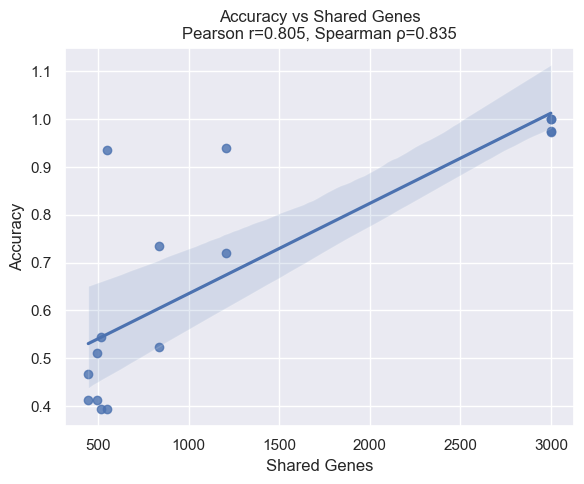

Accuracy: Pearson r=0.805, Spearman ρ=0.835 (p=0.0001)


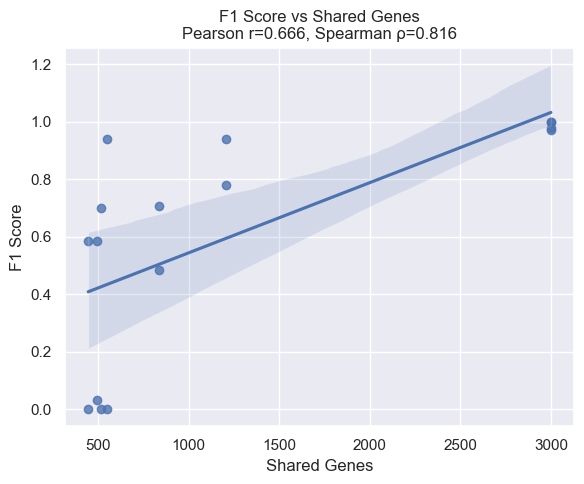

F1 Score: Pearson r=0.666, Spearman ρ=0.816 (p=0.0001)


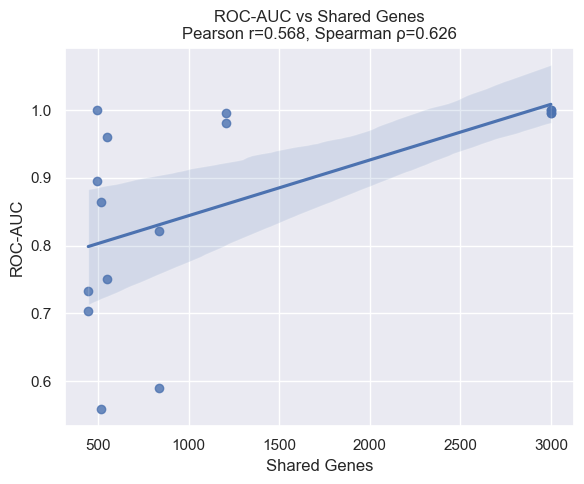

ROC-AUC: Pearson r=0.568, Spearman ρ=0.626 (p=0.0096)


In [109]:
from scipy.stats import spearmanr

metrics = {
    "accuracy": "Accuracy",
    "f1": "F1 Score",
    "roc_auc": "ROC-AUC"
}

for metric, label in metrics.items():
    pearson_r = transfer_df[["shared_genes", metric]].corr().iloc[0, 1]
    spearman_r, spearman_p = spearmanr(transfer_df["shared_genes"], transfer_df[metric])

    plt.figure(figsize=(6, 5))

    sns.regplot(
        data=transfer_df,
        x="shared_genes",
        y=metric)

    plt.xlabel("Shared Genes")
    plt.ylabel(label)
    plt.title(f"{label} vs Shared Genes\n"
        f"Pearson r={pearson_r:.3f}, Spearman ρ={spearman_r:.3f}")

    plt.tight_layout()
    plt.show()

    print(f"{label}: Pearson r={pearson_r:.3f}, "
        f"Spearman ρ={spearman_r:.3f} (p={spearman_p:.4f})")

Transfer-learning performance was strongly associated with the number of genes shared between training and testing datasets. Classification accuracy exhibited a strong positive correlation with gene overlap (Pearson r = 0.805; Spearman ρ = 0.835, p = 0.0001), indicating that datasets with greater feature compatibility generally produced more accurate cross-dataset predictions. A similar relationship was observed for F1 score (Pearson r = 0.666; Spearman ρ = 0.816, p = 0.0001), suggesting that increased gene overlap not only improved overall prediction accuracy but also enhanced the model's ability to correctly identify hypoxic samples. Together, these findings indicate that feature overlap is a major contributor to transfer-learning performance and may partially explain the reduced classification performance observed under dataset-shift conditions.

## 13. Feature Stability and Consensus Biomarkers

After evaluating transfer-learning performance, feature stability was examined to determine whether similar genes were selected across independent datasets. Genes that are repeatedly selected across datasets are more likely to represent robust hypoxia-associated biomarkers rather than dataset-specific artefacts.

To ensure comparability, the same reference model was used across datasets for feature-selection analysis. Specifically, the transfer model selected in Section 12 was reused for feature-stability analysis. Genes retained by the model's feature-selection step were extracted from each dataset and compared to identify stable hypoxia-associated biomarkers.

In [110]:
MODEL_NAME = TRANSFER_MODEL

gene_counter = Counter()
dataset_selected_genes = {}
skipped_gene_selection = []

for dataset in DATASET_ORDER:
    X, y = supervised_data[dataset]
    key = (dataset, MODEL_NAME)

    if key not in best_supervised_searches:
        skipped_gene_selection.append({
            "dataset": dataset,
            "model": MODEL_NAME,
            "reason": "model not found in best_supervised_searches"})
        print(f"Skipping {dataset}: {MODEL_NAME} was not fitted.")
        continue

    model = clone(best_supervised_searches[key].best_estimator_)

    model.fit(X, y)

    if not hasattr(model, "named_steps"):
        skipped_gene_selection.append({
            "dataset": dataset,
            "model": MODEL_NAME,
            "reason": "model is not a pipeline"})
        print(f"Skipping {dataset}: model is not a pipeline.")
        continue

    if "select" not in model.named_steps:
        skipped_gene_selection.append({
            "dataset": dataset,
            "model": MODEL_NAME,
            "reason": "pipeline has no select step"})
        print(f"Skipping {dataset}: pipeline has no 'select' step.")
        continue

    selector = model.named_steps["select"]

    if not hasattr(selector, "get_support"):
        skipped_gene_selection.append({
            "dataset": dataset,
            "model": MODEL_NAME,
            "reason": "selector does not support get_support"})
        print(f"Skipping {dataset}: selector has no get_support().")
        continue

    selected_genes = X.columns[selector.get_support()].tolist()
    dataset_selected_genes[dataset] = selected_genes
    gene_counter.update(selected_genes)

    print(f"{dataset}: selected {len(selected_genes)} genes")


skipped_gene_selection_df = pd.DataFrame(skipped_gene_selection)

if len(skipped_gene_selection_df) > 0:
    print("\nSkipped datasets:")
    display(skipped_gene_selection_df)

MCF7_SmartSeq: selected 100 genes
HCC1806_SmartSeq: selected 500 genes
MCF7_DropSeq: selected 100 genes
HCC1806_DropSeq: selected 500 genes


### 13.1 Jaccard Similarity of Gene Signatures

The similarity between dataset-specific gene signatures was quantified using the Jaccard index,

$$
J(A,B) = \frac{|A \cap B|}{|A \cup B|}
$$
This metric measures the proportion of shared genes relative to the total number of unique genes selected by two datasets. Higher Jaccard values indicate stronger agreement between feature-selection outcomes and therefore greater stability of the inferred hypoxia signature.

In [111]:
jaccard_results = []

for ds1, ds2 in combinations(DATASET_ORDER, 2):
    genes1 = set(dataset_selected_genes[ds1])
    genes2 = set(dataset_selected_genes[ds2])

    intersection = len(genes1 & genes2)
    union = len(genes1 | genes2)

    jaccard = (intersection / union if union > 0 else 0)
    jaccard_results.append({
        "dataset_1": ds1,
        "dataset_2": ds2,
        "jaccard": jaccard})

jaccard_df = pd.DataFrame(jaccard_results)

display(jaccard_df.sort_values("jaccard", ascending=False).round(3))

,dataset_1,dataset_2,jaccard
5,MCF7_DropSeq,HCC1806_DropSeq,0.089
4,HCC1806_SmartSeq,HCC1806_DropSeq,0.085
1,MCF7_SmartSeq,MCF7_DropSeq,0.058
0,MCF7_SmartSeq,HCC1806_SmartSeq,0.056
2,MCF7_SmartSeq,HCC1806_DropSeq,0.054
3,HCC1806_SmartSeq,MCF7_DropSeq,0.026


The pairwise Jaccard similarity matrix was visualized as a heatmap to provide an overview of feature-set stability across datasets. Clusters of high similarity suggest datasets that rely on comparable transcriptional signatures, whereas weaker overlap may reflect biological or technical differences.

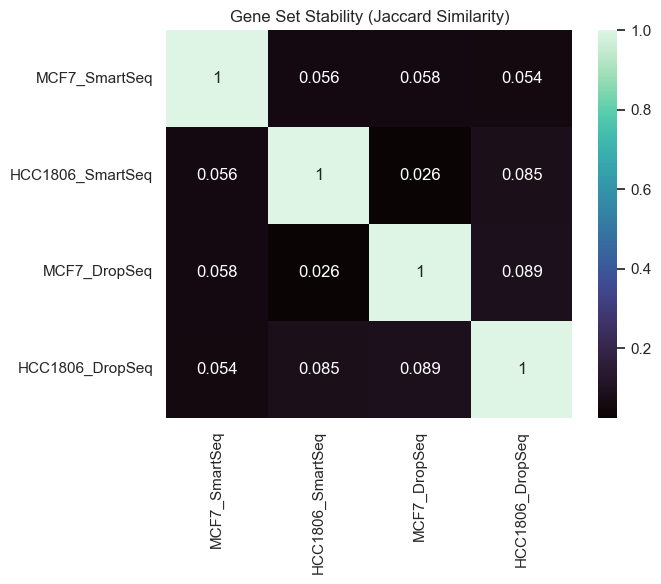

In [112]:
similarity_matrix = pd.DataFrame(
    index=DATASET_ORDER,
    columns=DATASET_ORDER,
    dtype=float)

for ds1 in DATASET_ORDER:
    for ds2 in DATASET_ORDER:
        g1 = set(dataset_selected_genes[ds1])
        g2 = set(dataset_selected_genes[ds2])
        similarity_matrix.loc[ds1, ds2] = len(g1 & g2) / len(g1 | g2)

plt.figure(figsize=(7,6))

sns.heatmap(
    similarity_matrix,
    annot=True,
    cmap="mako")

plt.title("Gene Set Stability (Jaccard Similarity)")

plt.tight_layout()
plt.show()

Gene-set stability across datasets was generally low, with Jaccard similarities ranging from 0.026 to 0.089. This indicates that the most predictive genes identified in each dataset showed limited overlap. Such variability may reflect biological differences between cell lines, technological differences between sequencing platforms, or some other instability in feature selection. Most importantly, low overlap at the individual-gene level does not necessarily mean inconsistent biological signals, as different genes may represent the same underlying hypoxia-related pathways.

### 13.2 Gene Frequency and Universal Biomarkers

To identify the most reproducible biomarkers, the frequency with which each gene appeared across dataset-specific signatures was calculated. Genes selected repeatedly across independent datasets represent strong candidates for universal hypoxia-associated markers.

In [113]:
gene_frequency_df = (pd.DataFrame(
        gene_counter.items(),
        columns=["gene", "frequency"])
    .sort_values(["frequency", "gene"], ascending=[False, True]))

display(gene_frequency_df.head(50))

,gene,frequency
39,DSP,4
24,MT-CO3,4
18,MT-CYB,4
31,PGK1,4
34,TMSB10,4
8,BNIP3,3
56,BNIP3L,3
3,DDIT4,3
29,EGLN3,3
37,ERO1A,3


Genes present in all dataset-specific signatures constitute the most stringent class of candidate biomarkers. Because these features survive independent training and feature-selection procedures across multiple biological contexts, they represent particularly strong candidates for universal hypoxia markers.

In [114]:
universal_genes = gene_frequency_df[gene_frequency_df["frequency"] == len(DATASET_ORDER)]

print(f"{len(universal_genes)} genes appeared in all "
    f"{len(DATASET_ORDER)} datasets.")

display(universal_genes)

5 genes appeared in all 4 datasets.


,gene,frequency
39,DSP,4
24,MT-CO3,4
18,MT-CYB,4
31,PGK1,4
34,TMSB10,4


Visualizing the most frequently selected genes provides an intuitive summary of feature stability. Recurrent appearance across datasets suggests that these genes capture conserved aspects of the transcriptional response to hypoxia and may contribute substantially to model generalization.

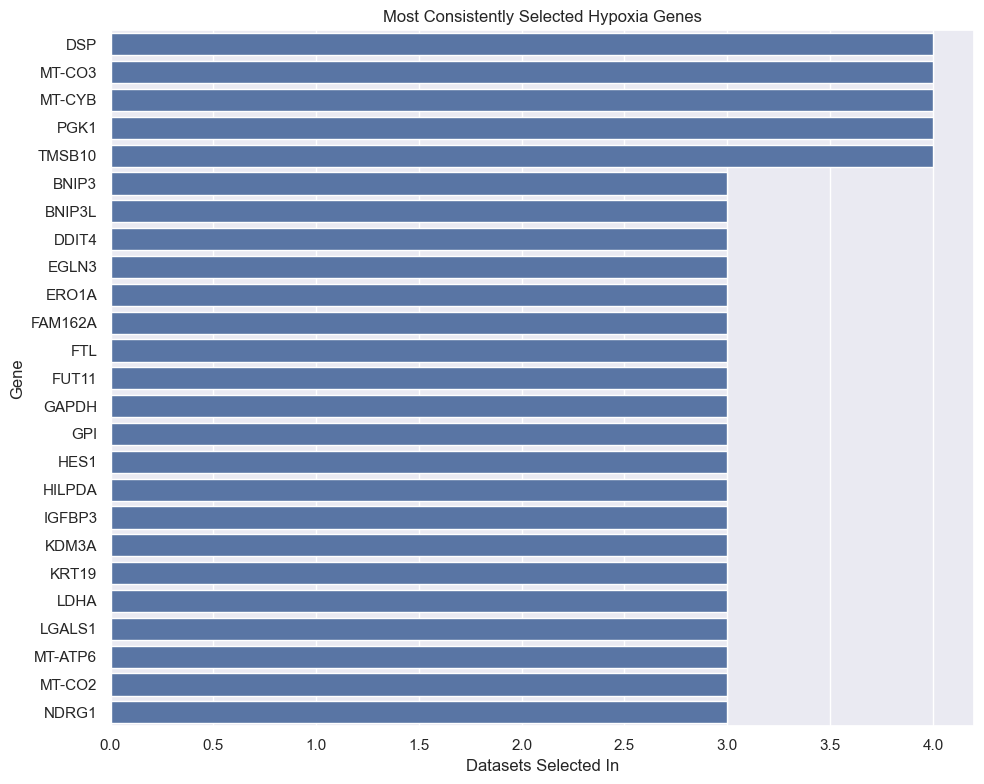

In [115]:
plt.figure(figsize=(10,8))

plot_df = gene_frequency_df.head(25)

sns.barplot(
    data=plot_df,
    x="frequency",
    y="gene")

plt.xlabel("Datasets Selected In")
plt.ylabel("Gene")
plt.title("Most Consistently Selected Hypoxia Genes")

plt.tight_layout()
plt.show()

### 13.3 Construction and Inspection of Consensus Genes

To construct a robust feature set for downstream analyses, a consensus hypoxia signature was defined using genes selected in at least three independent datasets. This approach balances reproducibility and inclusiveness by retaining genes that demonstrate consistent predictive value across multiple biological contexts.

In [116]:
CONSENSUS_THRESHOLD = 3

consensus_genes = (gene_frequency_df
    .query("frequency >= @CONSENSUS_THRESHOLD")["gene"]
    .tolist())

print(f"{len(consensus_genes)} consensus genes "
    f"(appearing in >= {CONSENSUS_THRESHOLD} datasets)")

29 consensus genes (appearing in >= 3 datasets)


The final consensus signature was inspected directly to facilitate biological interpretation and downstream validation. Because every gene in this set was selected repeatedly across independent analyses, the resulting signature represents a condensed collection of the most reproducible hypoxia-associated features identified in this study.

In [117]:
pd.DataFrame({"gene": consensus_genes})

,gene
0,DSP
1,MT-CO3
2,MT-CYB
3,PGK1
4,TMSB10
5,BNIP3
6,BNIP3L
7,DDIT4
8,EGLN3
9,ERO1A


In [118]:
consensus_results = []

for dataset in DATASET_ORDER:
    X, y = supervised_data[dataset]

    available_genes = [g for g in consensus_genes if g in X.columns]
    X_sig = X[available_genes]

    clf = LogisticRegression(
        max_iter=5000,
        class_weight="balanced",
        random_state=42)

    cv = StratifiedKFold(
        n_splits=5,
        shuffle=True,
        random_state=42)

    y_prob = cross_val_predict(
        clf,
        X_sig,
        y,
        cv=cv,
        method="predict_proba"
    )[:, 1]

    y_pred = (y_prob >= 0.5).astype(int)

    consensus_results.append({
        "dataset": dataset,
        "n_genes": len(available_genes),
        "accuracy": accuracy_score(y, y_pred),
        "f1": f1_score(y, y_pred),
        "roc_auc": roc_auc_score(y, y_prob)})

consensus_results_df = pd.DataFrame(consensus_results)

display(consensus_results_df.round(3))

,dataset,n_genes,accuracy,f1,roc_auc
0,MCF7_SmartSeq,28,1.000,1.000,1.000
1,HCC1806_SmartSeq,27,0.984,0.984,0.995
2,MCF7_DropSeq,12,0.898,0.876,0.959
3,HCC1806_DropSeq,29,0.795,0.815,0.876


Despite substantial variability in the individual genes identified as important in each dataset, logistic-regression models trained using only consensus genes achieved strong performance across all datasets (ROC-AUC 0.876–1.000). The SmartSeq datasets showed near-perfect discrimination, while performance was somewhat lower in the HCC1806 DropSeq dataset. These findings suggest that although dataset-specific feature selection results are unstable, a smaller core set of recurring genes captures a robust hypoxia-associated signal that generalizes across biological and technological contexts.

Restricting the model to a consensus feature set may improve interpretability, but it can also remove useful dataset-specific information. To quantify this trade-off, predictive performance obtained using the consensus signature was compared with that of the best-performing dataset-specific models.

This comparison evaluates whether a compact and reproducible gene set can retain most of the predictive power achieved by larger dataset-specific signatures.

In [119]:
best_accuracy = (supervised_results_df.groupby("dataset")["mean_accuracy"].max())
accuracy_comparison = (consensus_results_df[["dataset", "accuracy"]].copy())
accuracy_comparison["best_accuracy"] = (accuracy_comparison["dataset"].map(best_accuracy))
accuracy_comparison["accuracy_loss"] = (accuracy_comparison["best_accuracy"] - accuracy_comparison["accuracy"])

display(accuracy_comparison.round(3))

best_f1 = (supervised_results_df.groupby("dataset")["mean_f1"].max())
f1_comparison = (consensus_results_df[["dataset", "f1"]].copy())
f1_comparison["best_f1"] = (f1_comparison["dataset"].map(best_f1))
f1_comparison["f1_loss"] = (f1_comparison["best_f1"] - f1_comparison["f1"])

display(f1_comparison.round(3))

best_auc = (supervised_results_df.groupby("dataset")["mean_roc_auc"].max())
auc_comparison = (consensus_results_df[["dataset", "roc_auc"]].copy())
auc_comparison["best_roc_auc"] = (auc_comparison["dataset"].map(best_auc))
auc_comparison["roc_auc_loss"] = (auc_comparison["best_roc_auc"] - auc_comparison["roc_auc"])

display(auc_comparison.round(3))

,dataset,accuracy,best_accuracy,accuracy_loss
0,MCF7_SmartSeq,1.000,1.000,0.000
1,HCC1806_SmartSeq,0.984,0.989,0.006
2,MCF7_DropSeq,0.898,0.966,0.068
3,HCC1806_DropSeq,0.795,0.946,0.151


,dataset,f1,best_f1,f1_loss
0,MCF7_SmartSeq,1.000,1.000,0.000
1,HCC1806_SmartSeq,0.984,0.990,0.005
2,MCF7_DropSeq,0.876,0.959,0.082
3,HCC1806_DropSeq,0.815,0.956,0.141


,dataset,roc_auc,best_roc_auc,roc_auc_loss
0,MCF7_SmartSeq,1.000,1.000,0.000
1,HCC1806_SmartSeq,0.995,1.000,0.005
2,MCF7_DropSeq,0.959,0.993,0.035
3,HCC1806_DropSeq,0.876,0.990,0.114


This comparison shows that with the excpetion of HCC1806_DropSeq, the tradeoff from removing the non-repeating genes was low, and even the HCC1806_DropSeq tradeoff was likely within a regular threshold. 

### 13.4 Leave-One-Dataset-Out Generalization of the Consensus Signature

To evaluate whether the consensus gene signature captured a dataset-independent hypoxia signal, leave-one-dataset-out (LODO) validation was performed. For each iteration, one dataset was excluded from training and used exclusively for testing, while the classifier was trained on the remaining datasets. This provides a stringent assessment of cross-dataset generalization because the model is evaluated on data originating from an entirely unseen experiment.

In [120]:
X_all_list = []
y_all_list = []
dataset_labels = []

for dataset in DATASET_ORDER:
    X, y = supervised_data[dataset]
    available = [g for g in consensus_genes if g in X.columns]

    X_sub = X[available].copy()
    X_sub = X_sub.reindex(columns=consensus_genes, fill_value=0)

    X_all_list.append(X_sub)
    y_all_list.append(y)

    dataset_labels.extend([dataset] * len(y))

X_all = pd.concat(X_all_list)
y_all = np.concatenate(y_all_list)
dataset_labels = np.array(dataset_labels)

The consensus gene signature was evaluated independently to determine whether a compact set of reproducible biomarkers can support accurate hypoxia classification. Unlike dataset-specific signatures, the consensus feature set was derived from genes repeatedly selected across multiple biological contexts.

This evaluation addresses an important trade-off between interpretability and predictive performance. Although reducing the number of features may simplify biological interpretation, excessive reduction could remove informative signals and decrease classification accuracy.

Performance metrics obtained using the consensus signature therefore provide an indication of how much predictive information is retained within the most reproducible subset of hypoxia-associated genes.

In [121]:
lodo_results = []

for held_out in DATASET_ORDER:
    print(f"\nTesting on {held_out}")

    train_mask = dataset_labels != held_out
    test_mask = dataset_labels == held_out

    X_train = X_all.loc[train_mask]
    X_test = X_all.loc[test_mask]

    y_train = y_all[train_mask]
    y_test = y_all[test_mask]

    clf = LogisticRegression(
        max_iter=5000,
        class_weight="balanced",
        random_state=42)

    clf.fit(X_train, y_train)

    y_prob = clf.predict_proba(X_test)[:, 1]
    y_pred = clf.predict(X_test)

    lodo_results.append({
        "held_out_dataset": held_out,
        "accuracy": accuracy_score(y_test, y_pred),
        "f1": f1_score(y_test, y_pred),
        "roc_auc": roc_auc_score(y_test, y_prob)})

lodo_df = pd.DataFrame(lodo_results)

display(lodo_df.round(3))


Testing on MCF7_SmartSeq

Testing on HCC1806_SmartSeq

Testing on MCF7_DropSeq

Testing on HCC1806_DropSeq


,held_out_dataset,accuracy,f1,roc_auc
0,MCF7_SmartSeq,0.980,0.980,0.998
1,HCC1806_SmartSeq,0.527,0.691,0.844
2,MCF7_DropSeq,0.751,0.582,0.889
3,HCC1806_DropSeq,0.627,0.621,0.693


### 13.5 Visualization of Leave-One-Dataset-Out Results

Comparison of consensus-signature performance with dataset-specific models allows the practical value of feature consolidation to be assessed. If classification accuracy remains similar after substantial feature reduction, the resulting signature represents a robust and biologically interpretable predictor.

Conversely, large performance declines would suggest that important information is distributed across a broader collection of genes and that some degree of dataset-specific specialization contributes to predictive success.

The balance between these outcomes provides insight into the extent to which hypoxia responses are governed by a common transcriptional program.

In [122]:
within_accuracy = dict(zip(consensus_results_df["dataset"], consensus_results_df["accuracy"]))
within_f1 = dict(zip(consensus_results_df["dataset"], consensus_results_df["f1"]))
within_auc = dict(zip(consensus_results_df["dataset"], consensus_results_df["roc_auc"]))

gap_df = lodo_df.copy()
gap_df["within_accuracy"] = (gap_df["held_out_dataset"].map(within_accuracy))
gap_df["within_f1"] = (gap_df["held_out_dataset"].map(within_f1))
gap_df["within_roc_auc"] = (gap_df["held_out_dataset"].map(within_auc))
gap_df["accuracy_gap"] = (gap_df["within_accuracy"] - gap_df["accuracy"])
gap_df["f1_gap"] = (gap_df["within_f1"] - gap_df["f1"])
gap_df["roc_auc_gap"] = (gap_df["within_roc_auc"] - gap_df["roc_auc"])

accuracy_gap_df = (gap_df[[
        "held_out_dataset",
        "accuracy",
        "within_accuracy",
        "accuracy_gap"]]
    .sort_values("accuracy_gap", ascending=False))

print("\n=== ACCURACY GAP ===")
display(accuracy_gap_df.round(3))

f1_gap_df = (gap_df[[
        "held_out_dataset",
        "f1",
        "within_f1",
        "f1_gap"]]
    .sort_values("f1_gap", ascending=False))

print("\n=== F1 GAP ===")
display(f1_gap_df.round(3))

auc_gap_df = (gap_df[[
            "held_out_dataset",
            "roc_auc",
            "within_roc_auc",
            "roc_auc_gap"]]
    .sort_values("roc_auc_gap", ascending=False))

print("\n=== ROC-AUC GAP ===")
display(auc_gap_df.round(3))


=== ACCURACY GAP ===


,held_out_dataset,accuracy,within_accuracy,accuracy_gap
1,HCC1806_SmartSeq,0.527,0.984,0.456
3,HCC1806_DropSeq,0.627,0.795,0.168
2,MCF7_DropSeq,0.751,0.898,0.147
0,MCF7_SmartSeq,0.980,1.000,0.020



=== F1 GAP ===


,held_out_dataset,f1,within_f1,f1_gap
2,MCF7_DropSeq,0.582,0.876,0.294
1,HCC1806_SmartSeq,0.691,0.984,0.294
3,HCC1806_DropSeq,0.621,0.815,0.194
0,MCF7_SmartSeq,0.980,1.000,0.020



=== ROC-AUC GAP ===


,held_out_dataset,roc_auc,within_roc_auc,roc_auc_gap
3,HCC1806_DropSeq,0.693,0.876,0.184
1,HCC1806_SmartSeq,0.844,0.995,0.151
2,MCF7_DropSeq,0.889,0.959,0.070
0,MCF7_SmartSeq,0.998,1.000,0.002


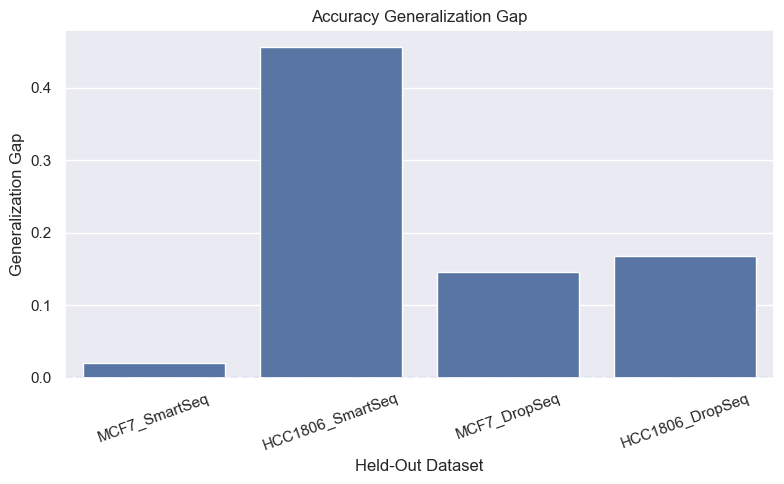

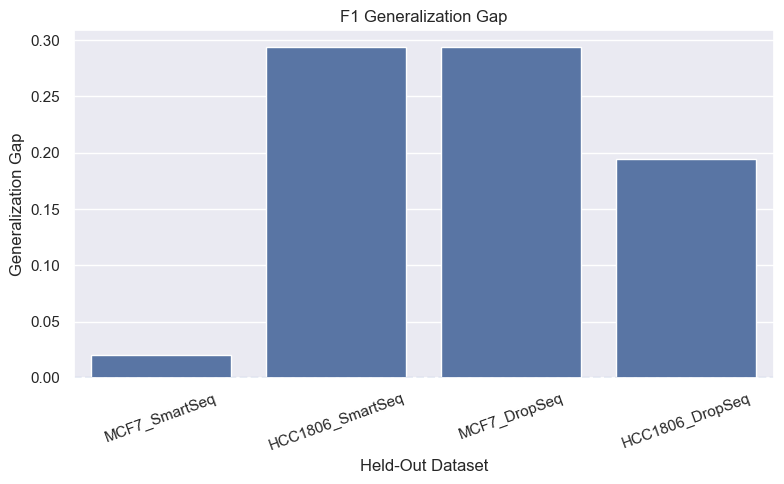

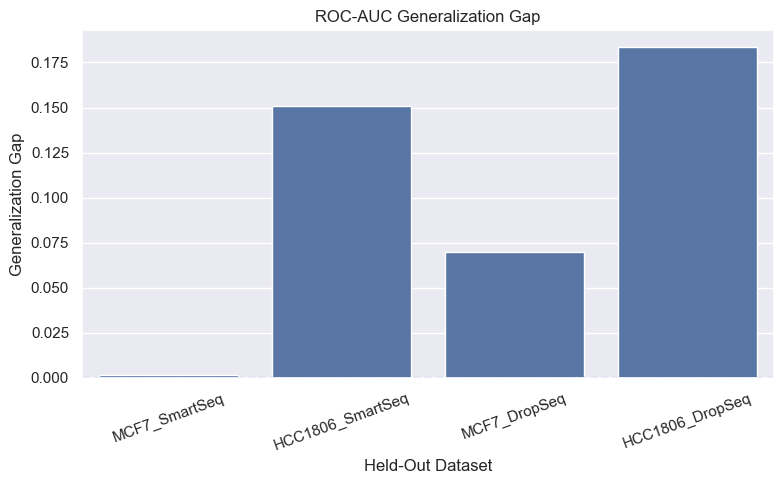

In [123]:
gap_metrics = {
    "accuracy_gap": "Accuracy Generalization Gap",
    "f1_gap": "F1 Generalization Gap",
    "roc_auc_gap": "ROC-AUC Generalization Gap"
}

for metric, title in gap_metrics.items():
    plt.figure(figsize=(8, 5))

    sns.barplot(
        data=gap_df,
        x="held_out_dataset",
        y=metric)

    plt.axhline(0, linestyle="--")

    plt.ylabel("Generalization Gap")
    plt.xlabel("Held-Out Dataset")
    plt.title(title)

    plt.xticks(rotation=20)
    plt.tight_layout()
    plt.show()

The above images show that, with the excpetion of MCF7_SmartSeq, training on three datasets and leaving out one was actually not significantly beneficial to the generalization gap. The ext section is dedicated to exploring how large or small this gap is, and other implications. 

## 14. Multi-Dataset Training Versus Single-Dataset Training

The leave-one-dataset-out experiments demonstrated that a classifier trained on multiple biological contexts can generalize to unseen datasets. However, an important practical question remains: does combining datasets actually improve predictive performance compared with training on only a single source dataset?

To address this question, we compared two training strategies for each held-out dataset:

1. **Multi-dataset training**, where all available datasets except the test dataset were combined into a single training set.
2. **Best single-dataset training**, where models trained on individual datasets were evaluated on the held-out dataset and only the strongest performer was retained.

This comparison isolates the contribution of data integration. If multi-dataset training consistently outperforms the best individual source dataset, it suggests that hypoxia-associated transcriptional patterns are distributed across datasets and can be learned more effectively through aggregation.

For each held-out dataset, model performance was quantified using ROC-AUC and F1 score. Improvements in these metrics indicate that integrating heterogeneous biological contexts provides additional information that cannot be captured by any single dataset alone.

In [124]:
multi_vs_single_results = []

for held_out in DATASET_ORDER:
    print(f"\nHeld-out test dataset: {held_out}")

    X_test, y_test = supervised_data[held_out]

    train_datasets = [d for d in DATASET_ORDER if d != held_out]

    train_gene_union = sorted(set().union(*[
        set(supervised_data[d][0].columns)
        for d in train_datasets]))

    shared_genes = sorted(set(train_gene_union) & set(X_test.columns))

    print(f"Shared genes for multi-dataset model: {len(shared_genes)}")

    X_train_multi_list = []
    y_train_multi_list = []

    for d in train_datasets:
        X_d, y_d = supervised_data[d]

        X_d_aligned = X_d.reindex(columns=shared_genes,fill_value=0)

        X_train_multi_list.append(X_d_aligned)
        y_train_multi_list.append(y_d)

    X_train_multi = pd.concat(X_train_multi_list, axis=0)
    y_train_multi = np.concatenate(y_train_multi_list)
    X_test_aligned = X_test.reindex(columns=shared_genes, fill_value=0)

    multi_model = LogisticRegression(
        max_iter=5000,
        class_weight="balanced",
        random_state=42)

    multi_model.fit(X_train_multi, y_train_multi)

    multi_pred = multi_model.predict(X_test_aligned)
    multi_prob = multi_model.predict_proba(X_test_aligned)[:, 1]

    multi_auc = roc_auc_score(y_test, multi_prob)
    multi_acc = accuracy_score(y_test, multi_pred)
    multi_f1 = f1_score(y_test, multi_pred)

    single_candidates = transfer_df.query("test_dataset == @held_out and train_dataset != @held_out")

    best_auc_row = (single_candidates.sort_values("roc_auc", ascending=False).iloc[0])
    best_accuracy_row = (single_candidates.sort_values("accuracy", ascending=False).iloc[0])
    best_f1_row = (single_candidates.sort_values("f1", ascending=False).iloc[0])

    print(f"Best single-dataset source by ROC-AUC: "
        f"{best_auc_row['train_dataset']} "
        f"(AUC={best_auc_row['roc_auc']:.3f})")
    print(f"Best single-dataset source by Accuracy: "
        f"{best_accuracy_row['train_dataset']} "
        f"(Accuracy={best_accuracy_row['accuracy']:.3f})")
    print(f"Best single-dataset source by F1: "
        f"{best_f1_row['train_dataset']} "
        f"(F1={best_f1_row['f1']:.3f})")

    print(f"Multi-dataset AUC: {multi_auc:.3f}")
    print(f"Multi-dataset Accuracy: {multi_acc:.3f}")
    print(f"Multi-dataset F1: {multi_f1:.3f}")

    multi_vs_single_results.append({
        "held_out_dataset": held_out,
        "multi_train_datasets": " + ".join(train_datasets),
        "n_shared_genes": len(shared_genes),
        "multi_dataset_auc": multi_auc,
        "best_single_auc": best_auc_row["roc_auc"],
        "best_single_auc_train_dataset": best_auc_row["train_dataset"],
        "auc_improvement": multi_auc - best_auc_row["roc_auc"],
        "multi_dataset_accuracy": multi_acc,
        "best_single_accuracy": best_accuracy_row["accuracy"],
        "best_single_accuracy_train_dataset": best_accuracy_row["train_dataset"],
        "accuracy_improvement": multi_acc - best_accuracy_row["accuracy"],
        "multi_dataset_f1": multi_f1,
        "best_single_f1": best_f1_row["f1"],
        "best_single_f1_train_dataset": best_f1_row["train_dataset"],
        "f1_improvement": multi_f1 - best_f1_row["f1"]
    })

multi_vs_single_df = pd.DataFrame(multi_vs_single_results)
multi_vs_single_df = pd.DataFrame(multi_vs_single_results)

auc_multi_vs_single_df = (multi_vs_single_df[[
        "held_out_dataset",
        "best_single_auc_train_dataset",
        "multi_train_datasets",
        "n_shared_genes",
        "multi_dataset_auc",
        "best_single_auc",
        "auc_improvement"]]
    .sort_values("auc_improvement", ascending=False))

print("\n=== ROC-AUC: MULTI-DATASET VS BEST SINGLE-DATASET ===")
display(auc_multi_vs_single_df.round(3))

accuracy_multi_vs_single_df = (multi_vs_single_df[[
        "held_out_dataset",
        "best_single_accuracy_train_dataset",
        "multi_train_datasets",
        "n_shared_genes",
        "multi_dataset_accuracy",
        "best_single_accuracy",
        "accuracy_improvement"]]
    .sort_values("accuracy_improvement", ascending=False))

print("\n=== ACCURACY: MULTI-DATASET VS BEST SINGLE-DATASET ===")
display(accuracy_multi_vs_single_df.round(3))

f1_multi_vs_single_df = (multi_vs_single_df[[
        "held_out_dataset",
        "best_single_f1_train_dataset",
        "multi_train_datasets",
        "n_shared_genes",
        "multi_dataset_f1",
        "best_single_f1",
        "f1_improvement"]]
    .sort_values("f1_improvement", ascending=False))

print("\n=== F1: MULTI-DATASET VS BEST SINGLE-DATASET ===")
display(f1_multi_vs_single_df.round(3))


Held-out test dataset: MCF7_SmartSeq
Shared genes for multi-dataset model: 1688
Best single-dataset source by ROC-AUC: MCF7_DropSeq (AUC=1.000)
Best single-dataset source by Accuracy: HCC1806_DropSeq (Accuracy=0.936)
Best single-dataset source by F1: HCC1806_DropSeq (F1=0.939)
Multi-dataset AUC: 1.000
Multi-dataset Accuracy: 0.988
Multi-dataset F1: 0.988

Held-out test dataset: HCC1806_SmartSeq
Shared genes for multi-dataset model: 1629
Best single-dataset source by ROC-AUC: MCF7_SmartSeq (AUC=0.981)
Best single-dataset source by Accuracy: MCF7_SmartSeq (Accuracy=0.940)
Best single-dataset source by F1: MCF7_SmartSeq (F1=0.941)
Multi-dataset AUC: 0.993
Multi-dataset Accuracy: 0.984
Multi-dataset F1: 0.984

Held-out test dataset: MCF7_DropSeq
Shared genes for multi-dataset model: 1354
Best single-dataset source by ROC-AUC: MCF7_SmartSeq (AUC=0.895)
Best single-dataset source by Accuracy: HCC1806_DropSeq (Accuracy=0.734)
Best single-dataset source by F1: HCC1806_DropSeq (F1=0.708)
Multi

,held_out_dataset,best_single_auc_train_dataset,multi_train_datasets,n_shared_genes,multi_dataset_auc,best_single_auc,auc_improvement
1,HCC1806_SmartSeq,MCF7_SmartSeq,MCF7_SmartSeq + MCF7_DropSeq + HCC1806_DropSeq,1629,0.993,0.981,0.012
0,MCF7_SmartSeq,MCF7_DropSeq,HCC1806_SmartSeq + MCF7_DropSeq + HCC1806_DropSeq,1688,1.000,1.000,0.000
2,MCF7_DropSeq,MCF7_SmartSeq,MCF7_SmartSeq + HCC1806_SmartSeq + HCC1806_Dro...,1354,0.800,0.895,-0.095
3,HCC1806_DropSeq,HCC1806_SmartSeq,MCF7_SmartSeq + HCC1806_SmartSeq + MCF7_DropSeq,1418,0.603,0.865,-0.262



=== ACCURACY: MULTI-DATASET VS BEST SINGLE-DATASET ===


,held_out_dataset,best_single_accuracy_train_dataset,multi_train_datasets,n_shared_genes,multi_dataset_accuracy,best_single_accuracy,accuracy_improvement
0,MCF7_SmartSeq,HCC1806_DropSeq,HCC1806_SmartSeq + MCF7_DropSeq + HCC1806_DropSeq,1688,0.988,0.936,0.052
1,HCC1806_SmartSeq,MCF7_SmartSeq,MCF7_SmartSeq + MCF7_DropSeq + HCC1806_DropSeq,1629,0.984,0.940,0.044
3,HCC1806_DropSeq,MCF7_DropSeq,MCF7_SmartSeq + HCC1806_SmartSeq + MCF7_DropSeq,1418,0.526,0.524,0.002
2,MCF7_DropSeq,HCC1806_DropSeq,MCF7_SmartSeq + HCC1806_SmartSeq + HCC1806_Dro...,1354,0.702,0.734,-0.032



=== F1: MULTI-DATASET VS BEST SINGLE-DATASET ===


,held_out_dataset,best_single_f1_train_dataset,multi_train_datasets,n_shared_genes,multi_dataset_f1,best_single_f1,f1_improvement
0,MCF7_SmartSeq,HCC1806_DropSeq,HCC1806_SmartSeq + MCF7_DropSeq + HCC1806_DropSeq,1688,0.988,0.939,0.048
1,HCC1806_SmartSeq,MCF7_SmartSeq,MCF7_SmartSeq + MCF7_DropSeq + HCC1806_DropSeq,1629,0.984,0.941,0.043
3,HCC1806_DropSeq,MCF7_DropSeq,MCF7_SmartSeq + HCC1806_SmartSeq + MCF7_DropSeq,1418,0.488,0.483,0.005
2,MCF7_DropSeq,HCC1806_DropSeq,MCF7_SmartSeq + HCC1806_SmartSeq + HCC1806_Dro...,1354,0.687,0.708,-0.021


The performance achieved under multi-dataset and single-dataset training strategies was visualized for each held-out dataset using accuracy, F1 score, and ROC-AUC. Comparing these metrics allows direct assessment of whether combining datasets improves predictive performance relative to training on the best individual dataset, while accounting for potential challenges introduced by increased biological and technical heterogeneity.

Consistent improvements across held-out datasets would suggest that multi-dataset training captures a more generalizable hypoxia-associated signal rather than dataset-specific patterns. Conversely, similar or reduced performance would indicate that additional heterogeneity may limit the benefits of combining datasets despite the larger training set.

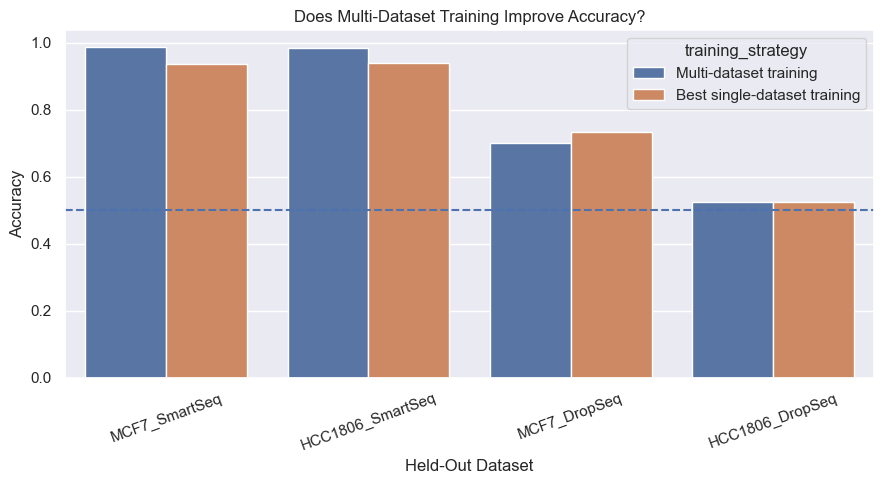

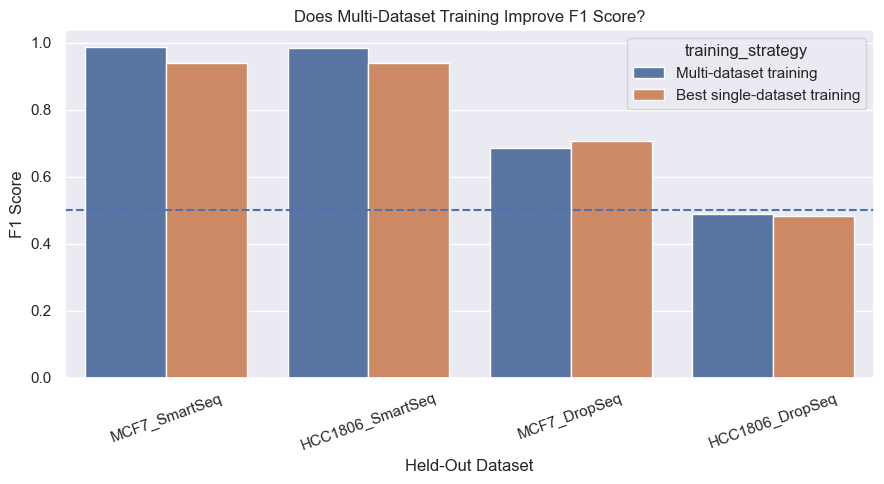

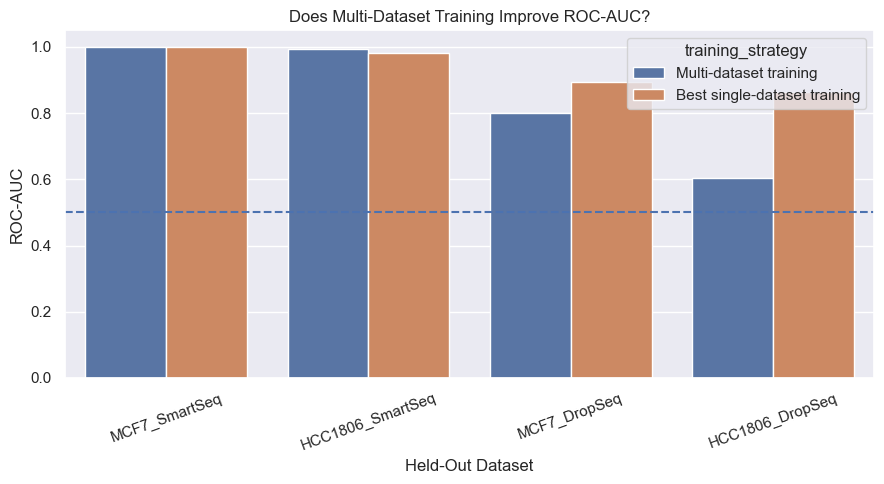

In [125]:
metric_configs = [(
    "multi_dataset_accuracy",
    "best_single_accuracy",
    "accuracy",
    "Accuracy",
    "Does Multi-Dataset Training Improve Accuracy?"),
    ("multi_dataset_f1",
    "best_single_f1",
    "f1",
    "F1 Score",
    "Does Multi-Dataset Training Improve F1 Score?"),
    ("multi_dataset_auc",
    "best_single_auc",
    "roc_auc",
    "ROC-AUC",
    "Does Multi-Dataset Training Improve ROC-AUC?")]

for multi_col, single_col, value_name, ylabel, title in metric_configs:
    plot_df = multi_vs_single_df.melt(
        id_vars="held_out_dataset",
        value_vars=[multi_col, single_col],
        var_name="training_strategy",
        value_name=value_name)
    
    plot_df["training_strategy"] = plot_df["training_strategy"].replace({
        multi_col: "Multi-dataset training",
        single_col: "Best single-dataset training"})

    plt.figure(figsize=(9, 5))

    sns.barplot(
        data=plot_df,
        x="held_out_dataset",
        y=value_name,
        hue="training_strategy")

    plt.axhline(0.5, linestyle="--")

    plt.ylabel(ylabel)
    plt.xlabel("Held-Out Dataset")
    plt.title(title)

    plt.xticks(rotation=20)
    plt.tight_layout()
    plt.show()

To provide a global assessment of the effect of dataset integration, average performance metrics were calculated across all held-out datasets. Mean ROC-AUC, mean F1 score, and average performance improvements were used to summarize the overall benefit of multi-dataset training.

Because individual transfer experiments can be influenced by dataset-specific characteristics, aggregated metrics provide a more reliable estimate of the practical value of combining multiple biological contexts during model development.

In [126]:
summary_multi_vs_single = pd.DataFrame({
    "metric": ["Accuracy", "F1", "ROC-AUC"],
    "multi_dataset": [multi_vs_single_df["multi_dataset_accuracy"].mean(),
        multi_vs_single_df["multi_dataset_f1"].mean(),
        multi_vs_single_df["multi_dataset_auc"].mean()],
    "best_single_dataset": [multi_vs_single_df["best_single_accuracy"].mean(),
        multi_vs_single_df["best_single_f1"].mean(),
        multi_vs_single_df["best_single_auc"].mean()]
})

summary_multi_vs_single["improvement"] = (summary_multi_vs_single["multi_dataset"] - summary_multi_vs_single["best_single_dataset"])

display(summary_multi_vs_single.round(3))

,metric,multi_dataset,best_single_dataset,improvement
0,Accuracy,0.800,0.783,0.016
1,F1,0.787,0.768,0.019
2,ROC-AUC,0.849,0.935,-0.086


Cross-dataset transfer performance was represented as a network to visualize relationships among biological contexts and the flow of transferable hypoxia information.

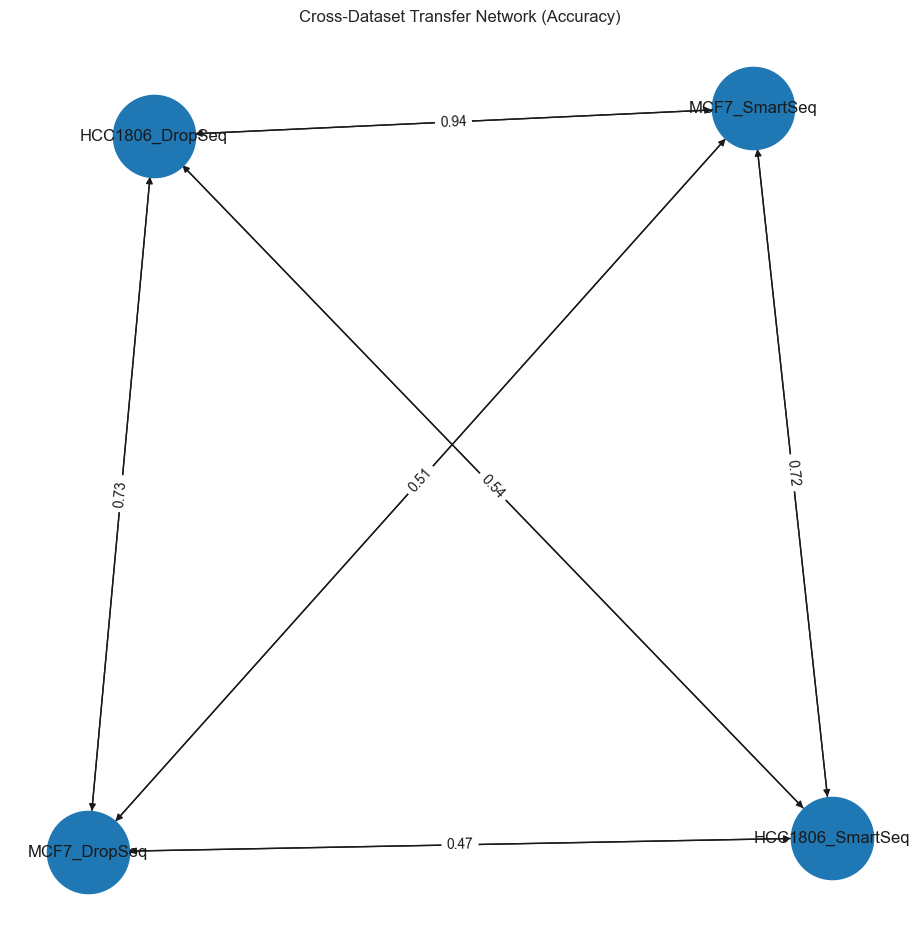

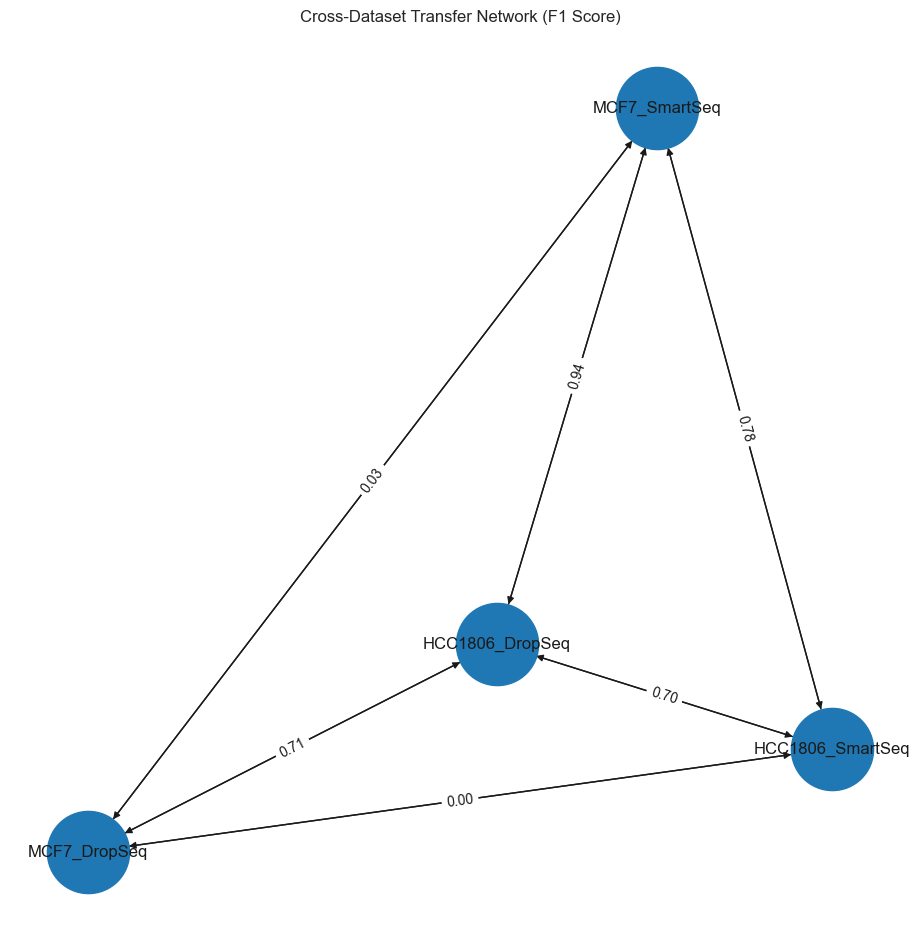

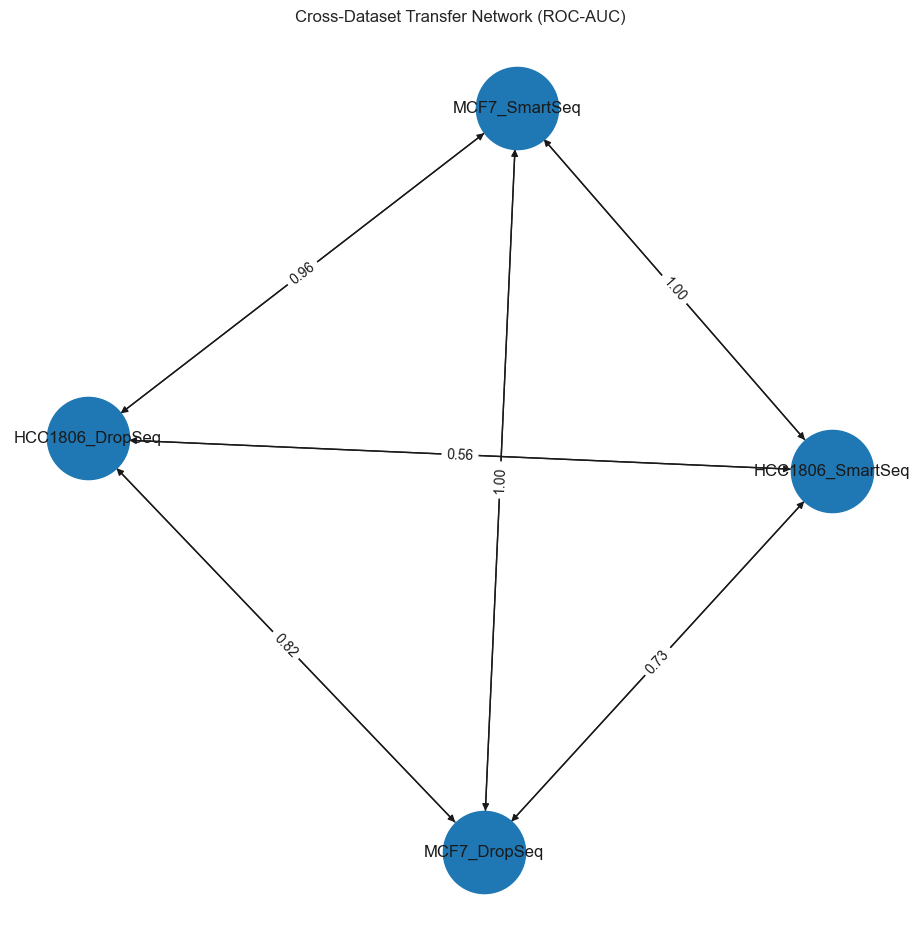

In [127]:
network_metrics = {
    "accuracy": "Accuracy",
    "f1": "F1 Score",
    "roc_auc": "ROC-AUC"
}

for metric, label in network_metrics.items():
    G = nx.DiGraph()

    for _, row in transfer_df.iterrows():
        if row["train_dataset"] == row["test_dataset"]:
            continue

        G.add_edge(
            row["train_dataset"],
            row["test_dataset"],
            weight=row[metric])

    plt.figure(figsize=(9, 9))

    pos = nx.spring_layout(G, seed=42)

    nx.draw(
        G,
        pos,
        with_labels=True,
        node_size=3500)

    edge_labels = {(u, v): f"{d['weight']:.2f}"
        for u, v, d in G.edges(data=True)}

    nx.draw_networkx_edge_labels(
        G,
        pos,
        edge_labels=edge_labels)

    plt.title(f"Cross-Dataset Transfer Network ({label})")
    plt.show()

## 15. Construction of a Universal Hypoxia Classifier

The previous analyses demonstrated that hypoxia-associated transcriptional signals can transfer across datasets, but the final classifier used for deployment should not simply copy the hyperparameters from one dataset-specific model. In this section, all four training datasets are first aligned to their common gene space and combined into a single joined training matrix. This joined matrix is then used in the following step to perform model selection directly on the combined multi-dataset training set.

In [128]:
print(f"Transfer-selected model type from earlier sections: {TRANSFER_MODEL}")

shared_all_genes = sorted(set.intersection(*[
    set(supervised_data[d][0].columns)
    for d in DATASET_ORDER]))

print(f"Genes shared by all datasets: {len(shared_all_genes)}")

if len(shared_all_genes) < 50:
    print("WARNING: Very few shared genes. Model may be unstable.")

X_final_list = []
y_final_list = []
dataset_source_list = []

for dataset_name in DATASET_ORDER:
    X_d, y_d = supervised_data[dataset_name]

    X_d_aligned = X_d.reindex(columns=shared_all_genes, fill_value=0,)

    X_final_list.append(X_d_aligned)
    y_final_list.append(y_d)
    dataset_source_list.extend([dataset_name] * len(y_d))

X_final = pd.concat(X_final_list, axis=0)
y_final = np.concatenate(y_final_list)
final_dataset_sources = np.array(dataset_source_list)

print("Final joined training matrix:", X_final.shape)
print("Final joined label vector:", y_final.shape)
print("Source datasets:", ", ".join(DATASET_ORDER))


Transfer-selected model type from earlier sections: Logistic_L2_ANOVA
Genes shared by all datasets: 70
Final joined training matrix: (36740, 70)
Final joined label vector: (36740,)
Source datasets: MCF7_SmartSeq, HCC1806_SmartSeq, MCF7_DropSeq, HCC1806_DropSeq


The key change is that the joined classifier is now selected using cross-validated performance on the joined training matrix, or on a stratified subset of that matrix when the full dataset is large. After model selection, the selected estimator is retrained on the complete joined training matrix. This avoids the previous weakness where the final model inherited hyperparameters from the first matching dataset-specific model in DATASET_ORDER.


In [129]:
joined_model_results = []
joined_model_searches = {}

JOINED_MODEL_SELECTION_MAX_CELLS = 8000

if X_final.shape[0] > JOINED_MODEL_SELECTION_MAX_CELLS:
    X_joined_search, y_joined_search = stratified_subsample(
        X_final,
        pd.Series(y_final, index=X_final.index),
        max_cells=JOINED_MODEL_SELECTION_MAX_CELLS,
        random_state=SUPERVISED_RANDOM_STATE,)
    y_joined_search = np.asarray(y_joined_search)
    print(
        f"Joined model selection uses a stratified subset: "
        f"{X_joined_search.shape[0]} of {X_final.shape[0]} cells")
else:
    X_joined_search = X_final
    y_joined_search = y_final
    print("Joined model selection uses all joined training cells.")

if X_joined_search.shape[0] < 500:
    joined_cv = StratifiedKFold(
        n_splits=5,
        shuffle=True,
        random_state=SUPERVISED_RANDOM_STATE)
else:
    joined_cv = StratifiedKFold(
        n_splits=3 if SUPERVISED_RUN_MODE == "fast" else 5,
        shuffle=True,
        random_state=SUPERVISED_RANDOM_STATE)

for model_name, spec in model_specs.items():
    print(f"\nRunning joined-dataset search for {model_name}...")
    model_start = time.perf_counter()

    search = GridSearchCV(
        estimator=clone(spec["pipeline"]),
        param_grid=spec["param_grid"],
        scoring=scoring,
        refit="roc_auc",
        cv=joined_cv,
        n_jobs=N_JOBS,
        return_train_score=False,
        error_score=np.nan,
        verbose=1,)

    try:
        search.fit(X_joined_search, y_joined_search)

        best_idx = search.best_index_
        result_row = {
            "model": model_name,
            "best_params": search.best_params_,
            "mean_accuracy": search.cv_results_["mean_test_accuracy"][best_idx],
            "std_accuracy": search.cv_results_["std_test_accuracy"][best_idx],
            "mean_balanced_accuracy": search.cv_results_["mean_test_balanced_accuracy"][best_idx],
            "std_balanced_accuracy": search.cv_results_["std_test_balanced_accuracy"][best_idx],
            "mean_f1": search.cv_results_["mean_test_f1"][best_idx],
            "std_f1": search.cv_results_["std_test_f1"][best_idx],
            "mean_roc_auc": search.cv_results_["mean_test_roc_auc"][best_idx],
            "std_roc_auc": search.cv_results_["std_test_roc_auc"][best_idx],
            "run_time_seconds": time.perf_counter() - model_start,
            "status": "OK",
        }

        joined_model_searches[model_name] = search

        print(f"Finished {model_name}: ROC-AUC = "
            f"{result_row['mean_roc_auc']:.4f} +/- {result_row['std_roc_auc']:.4f}")
        print(f"Best params: {search.best_params_}")

    except Exception as e:
        result_row = {
            "model": model_name,
            "best_params": None,
            "mean_accuracy": np.nan,
            "std_accuracy": np.nan,
            "mean_balanced_accuracy": np.nan,
            "std_balanced_accuracy": np.nan,
            "mean_f1": np.nan,
            "std_f1": np.nan,
            "mean_roc_auc": np.nan,
            "std_roc_auc": np.nan,
            "run_time_seconds": time.perf_counter() - model_start,
            "status": f"FAILED: {type(e).__name__}: {e}",
        }
        print(f"FAILED {model_name}: {e}")

    joined_model_results.append(result_row)

joined_model_results_df = pd.DataFrame(joined_model_results)

display(joined_model_results_df
    .sort_values("mean_roc_auc", ascending=False)
    .style.format({
        "mean_roc_auc": "{:.3f}",
        "std_roc_auc": "{:.3f}",
        "mean_f1": "{:.3f}",
        "std_f1": "{:.3f}",
        "mean_balanced_accuracy": "{:.3f}",
        "std_balanced_accuracy": "{:.3f}",
        "mean_accuracy": "{:.3f}",
        "std_accuracy": "{:.3f}",
        "run_time_seconds": "{:.1f}"}))

valid_joined_results = joined_model_results_df.query("status == 'OK'").copy()

if valid_joined_results.empty:
    raise ValueError("No joined-dataset model search completed successfully.")

best_joined_row = (valid_joined_results
    .sort_values(["mean_roc_auc", "mean_f1", "mean_balanced_accuracy"], ascending=False)
    .iloc[0])

best_joined_model_name = best_joined_row["model"]

print("Best joined-dataset model:", best_joined_model_name)
print("Best joined-dataset CV ROC-AUC:", round(best_joined_row["mean_roc_auc"], 4))
print("Best joined-dataset parameters:", best_joined_row["best_params"])

final_hypoxia_model = clone(joined_model_searches[best_joined_model_name].best_estimator_)
final_hypoxia_model.fit(X_final, y_final)

print("Final joined multi-dataset hypoxia model trained on all available training cells.")
print(f"Model type: {best_joined_model_name}")
print(f"Training datasets: {', '.join(DATASET_ORDER)}")
print(f"Training samples: {X_final.shape[0]}")
print(f"Training genes: {X_final.shape[1]}")


Joined model selection uses a stratified subset: 8000 of 36740 cells

Running joined-dataset search for Logistic_L2_ANOVA...
Fitting 3 folds for each of 9 candidates, totalling 27 fits
Finished Logistic_L2_ANOVA: ROC-AUC = 0.8893 +/- 0.0017
Best params: {'clf__C': 0.1, 'select__k': 100}

Running joined-dataset search for LinearSVM_ANOVA...
Fitting 3 folds for each of 12 candidates, totalling 36 fits
Finished LinearSVM_ANOVA: ROC-AUC = 0.8890 +/- 0.0010
Best params: {'clf__C': 0.01, 'select__k': 100}

Running joined-dataset search for RBF_SVM_ANOVA...
Fitting 3 folds for each of 6 candidates, totalling 18 fits
Finished RBF_SVM_ANOVA: ROC-AUC = 0.9018 +/- 0.0014
Best params: {'clf__C': 10, 'clf__gamma': 'scale', 'select__k': 100}

Running joined-dataset search for RandomForest_ANOVA...
Fitting 3 folds for each of 12 candidates, totalling 36 fits
Finished RandomForest_ANOVA: ROC-AUC = 0.9124 +/- 0.0014
Best params: {'clf__max_depth': 20, 'clf__max_features': 'log2', 'select__k': 500}

Run

,model,best_params,mean_accuracy,std_accuracy,mean_balanced_accuracy,std_balanced_accuracy,mean_f1,std_f1,mean_roc_auc,std_roc_auc,run_time_seconds,status
4,ExtraTrees_ANOVA,"{'clf__max_depth': 20, 'clf__max_features': 'sqrt', 'select__k': 500}",0.828,0.004,0.827,0.003,0.819,0.003,0.914,0.001,4.3,OK
3,RandomForest_ANOVA,"{'clf__max_depth': 20, 'clf__max_features': 'log2', 'select__k': 500}",0.827,0.005,0.826,0.004,0.819,0.003,0.912,0.001,5.1,OK
2,RBF_SVM_ANOVA,"{'clf__C': 10, 'clf__gamma': 'scale', 'select__k': 100}",0.816,0.002,0.816,0.002,0.813,0.001,0.902,0.001,12.9,OK
0,Logistic_L2_ANOVA,"{'clf__C': 0.1, 'select__k': 100}",0.809,0.004,0.809,0.003,0.803,0.002,0.889,0.002,13.6,OK
1,LinearSVM_ANOVA,"{'clf__C': 0.01, 'select__k': 100}",0.808,0.004,0.808,0.004,0.801,0.002,0.889,0.001,2.4,OK
6,PCA_LinearSVM,"{'clf__C': 0.01, 'pca__n_components': 50}",0.789,0.002,0.789,0.002,0.783,0.004,0.870,0.006,0.9,OK
5,PCA_Logistic,"{'clf__C': 0.1, 'pca__n_components': 50}",0.788,0.003,0.788,0.004,0.783,0.006,0.870,0.006,4.1,OK
8,KNN_PCA,"{'clf__n_neighbors': 11, 'clf__weights': 'distance', 'pca__n_components': 50}",0.763,0.005,0.763,0.005,0.749,0.005,0.849,0.007,1.1,OK
7,GaussianNB_ANOVA,{'select__k': 100},0.530,0.011,0.522,0.011,0.127,0.045,0.772,0.008,0.2,OK


Best joined-dataset model: ExtraTrees_ANOVA
Best joined-dataset CV ROC-AUC: 0.9143
Best joined-dataset parameters: {'clf__max_depth': 20, 'clf__max_features': 'sqrt', 'select__k': 500}
Final joined multi-dataset hypoxia model trained on all available training cells.
Model type: ExtraTrees_ANOVA
Training datasets: MCF7_SmartSeq, HCC1806_SmartSeq, MCF7_DropSeq, HCC1806_DropSeq
Training samples: 36740
Training genes: 70


### 15.1 Leave-One-Cell-Line-Out Generalization

Leave-one-dataset-out experiments evaluate robustness to unseen datasets, but datasets may still contain related biological systems. To assess whether the model captures hypoxia biology rather than cell-line-specific signatures, a stricter validation strategy was performed.

For each iteration, all datasets originating from one cell line were excluded during training and reserved exclusively for testing. The classifier was then trained using data from the remaining cell lines and evaluated on the unseen cell-line group.

Successful performance under this setting indicates that the learned representation is not dependent on a particular cellular background and instead reflects biological processes associated with hypoxic response.

In [131]:
def compute_extended_metrics(y_true, y_pred, y_score):
    return {
        "accuracy": accuracy_score(y_true, y_pred),
        "balanced_accuracy": balanced_accuracy_score(y_true, y_pred),
        "f1": f1_score(y_true, y_pred),
        "roc_auc": roc_auc_score(y_true, y_score)
    }

def infer_cell_line(dataset_name):
    if "MCF7" in dataset_name:
        return "MCF7"
    elif "HCC1806" in dataset_name:
        return "HCC1806"
    else:
        return "Unknown"


def get_model_scores(model, X):
    if hasattr(model, "predict_proba"):
        return model.predict_proba(X)[:, 1]
    if hasattr(model, "decision_function"):
        return model.decision_function(X)
    raise AttributeError("Model has neither predict_proba nor decision_function.")


cell_line_results = []

for held_out_cell_line in sorted(set(infer_cell_line(d) for d in DATASET_ORDER)):
    train_datasets = [d for d in DATASET_ORDER if infer_cell_line(d) != held_out_cell_line]
    test_datasets = [d for d in DATASET_ORDER if infer_cell_line(d) == held_out_cell_line]

    shared_genes = sorted(set.intersection(*[
        set(supervised_data[d][0].columns)
        for d in train_datasets + test_datasets]))

    X_train = pd.concat([supervised_data[d][0].reindex(columns=shared_genes, fill_value=0)
        for d in train_datasets])
    y_train = np.concatenate([supervised_data[d][1] for d in train_datasets])
    X_test = pd.concat([supervised_data[d][0].reindex(columns=shared_genes, fill_value=0)
        for d in test_datasets])
    y_test = np.concatenate([supervised_data[d][1] for d in test_datasets])

    model = clone(final_hypoxia_model)
    model.fit(X_train, y_train)

    y_score = get_model_scores(model, X_test)
    y_pred = model.predict(X_test)

    metrics = compute_extended_metrics(y_test, y_pred, y_score)

    metrics.update({
        "held_out_cell_line": held_out_cell_line,
        "train_datasets": " + ".join(train_datasets),
        "test_datasets": " + ".join(test_datasets),
        "model": best_joined_model_name,
        "n_genes": len(shared_genes),
    })

    cell_line_results.append(metrics)

cell_line_generalization_df = pd.DataFrame(cell_line_results)

display_cols = [
    "held_out_cell_line",
    "accuracy",
    "f1",
    "roc_auc"]

display(cell_line_generalization_df[display_cols].round(3))


,held_out_cell_line,accuracy,f1,roc_auc
0,HCC1806,0.527,0.479,0.617
1,MCF7,0.624,0.676,0.886


### 15.2 Leave-One-Technology-Out Generalization

Single-cell transcriptomic datasets generated using different sequencing technologies often exhibit substantial technical variation. Models trained on one platform may therefore fail when applied to data generated using another.

To evaluate robustness to technical differences, a leave-one-technology-out analysis was performed. Datasets produced by one sequencing technology were excluded from training and used only for testing, while the model was trained using data from the remaining technologies.

This experiment provides an estimate of how well the classifier can tolerate platform-specific biases and whether the hypoxia signal remains detectable across different experimental protocols.

In [132]:
def infer_technology(dataset_name):
    if "SmartSeq" in dataset_name:
        return "SmartSeq"
    elif "DropSeq" in dataset_name:
        return "DropSeq"
    else:
        return "Unknown"

technology_results = []

for held_out_technology in sorted(set(infer_technology(d) for d in DATASET_ORDER)):
    train_datasets = [d for d in DATASET_ORDER if infer_technology(d) != held_out_technology]
    test_datasets = [d for d in DATASET_ORDER if infer_technology(d) == held_out_technology]

    shared_genes = sorted(set.intersection(*[set(supervised_data[d][0].columns) for d in train_datasets + test_datasets]))

    X_train = pd.concat([supervised_data[d][0].reindex(columns=shared_genes, fill_value=0) for d in train_datasets])
    y_train = np.concatenate([supervised_data[d][1] for d in train_datasets])
    X_test = pd.concat([supervised_data[d][0].reindex(columns=shared_genes, fill_value=0) for d in test_datasets])
    y_test = np.concatenate([supervised_data[d][1] for d in test_datasets])

    model = clone(final_hypoxia_model)
    model.fit(X_train, y_train)

    y_score = model.predict_proba(X_test)[:, 1]
    y_pred = model.predict(X_test)

    metrics = compute_extended_metrics(y_test, y_pred, y_score)

    metrics.update({
        "held_out_technology": held_out_technology,
        "train_datasets": " + ".join(train_datasets),
        "test_datasets": " + ".join(test_datasets),
        "n_genes": len(shared_genes)})

    technology_results.append(metrics)

technology_generalization_df = pd.DataFrame(technology_results)

display_cols = [
    "held_out_technology",
    "accuracy",
    "f1",
    "roc_auc"]

display(technology_generalization_df[display_cols].round(3))

,held_out_technology,accuracy,f1,roc_auc
0,DropSeq,0.491,0.658,0.478
1,SmartSeq,0.461,0.572,0.443


### 15.3 Uncertainty Estimation Using Bootstrap Resampling

Point estimates such as ROC-AUC summarize model performance but do not quantify statistical uncertainty. To estimate the variability of performance measurements, bootstrap resampling was applied.

During each bootstrap iteration, samples were drawn with replacement from the evaluation set and ROC-AUC was recalculated. Repeating this procedure many times produces an empirical distribution of AUC values.

The 95% confidence interval was obtained from the 2.5th and 97.5th percentiles of the bootstrap distribution. Narrow intervals indicate stable performance estimates, whereas wider intervals suggest greater uncertainty arising from sample composition.

In [133]:
def bootstrap_auc_ci(y_true, y_score, n_bootstraps=1000, random_state=42):
    rng = np.random.default_rng(random_state)
    aucs = []

    y_true = np.array(y_true)
    y_score = np.array(y_score)

    for _ in range(n_bootstraps):
        indices = rng.choice(
            np.arange(len(y_true)),
            size=len(y_true),
            replace=True)

        if len(np.unique(y_true[indices])) < 2:
            continue

        aucs.append(roc_auc_score(y_true[indices], y_score[indices]))

    return {
        "auc_mean": np.mean(aucs),
        "auc_ci_lower": np.percentile(aucs, 2.5),
        "auc_ci_upper": np.percentile(aucs, 97.5)}

In [134]:
ci_result = bootstrap_auc_ci(y_test, y_score, n_bootstraps=1000)
ci_result

{'auc_mean': np.float64(0.4417691652877168),
 'auc_ci_lower': np.float64(0.3867640262742628),
 'auc_ci_upper': np.float64(0.4977352029752776)}

## 16. Final Test-Set Prediction and New-Data Deployment

This section applies the trained classifiers to the anonymised held-out test files.

It produces two groups of outputs:

1. one CSV per dataset using that dataset's best within-dataset classifier;
2. one CSV per test dataset using the joined multi-dataset classifier trained in Section 16.

The final block also shows how the joined classifier should be applied to a future external file. That code is intentionally commented out because the external file was not provided for this project. 

In [ ]:
SECTION17_OUTPUT_DIR = Path("Final_Predictions")
SECTION17_OUTPUT_DIR.mkdir(exist_ok=True)

test_files = {
    "MCF7_SmartSeq":    SMARTSEQ / "MCF7_SmartS_Filtered_Normalised_3000_Data_test_anonim.txt",
    "HCC1806_SmartSeq": SMARTSEQ / "HCC1806_SmartS_Filtered_Normalised_3000_Data_test_anonim.txt",
    "MCF7_DropSeq":     DROPSEQ / "MCF7_Filtered_Normalised_3000_Data_test_anonim.txt",
    "HCC1806_DropSeq":  DROPSEQ / "HCC1806_Filtered_Normalised_3000_Data_test_anonim.txt",
}

print("Prediction output folder:", SECTION17_OUTPUT_DIR.resolve())


### 16.1 Prediction helper functions

The original expression files are stored as genes by cells. Classifiers, however, were trained on cells by genes. The helper below therefore transposes each test matrix, aligns it to the required gene list, and writes one row per test cell.

For models with `predict_proba`, the CSV includes `hypoxia_probability`. For models without probabilities, it stores the model's continuous `hypoxia_score` instead.

In [151]:
def load_test_expression_as_cells_by_genes(file_path):
    df_genes_by_cells = load_expression(file_path)
    return df_genes_by_cells.T


def get_hypoxia_scores(model, X):
    if hasattr(model, "predict_proba"):
        return model.predict_proba(X)[:, 1], "hypoxia_probability"
    if hasattr(model, "decision_function"):
        return model.decision_function(X), "hypoxia_score"
    raise AttributeError("Model has neither predict_proba nor decision_function.")


def predict_test_matrix(model, test_file_path, required_genes, output_path, dataset_name, model_label):
    X_test_raw = load_test_expression_as_cells_by_genes(test_file_path)

    missing_genes = sorted(set(required_genes) - set(X_test_raw.columns))

    X_test = X_test_raw.reindex(columns=required_genes, fill_value=0)

    y_pred = model.predict(X_test)
    y_score, score_column = get_hypoxia_scores(model, X_test)

    predictions = pd.DataFrame({
        "dataset": dataset_name,
        "cell_id": X_test.index.astype(str),
        "predicted_status": np.where(np.asarray(y_pred) == 1, "Hypoxia", "Normoxia"),
        score_column: y_score,
    })

    predictions.to_csv(output_path, index=False)

    print(f"Saved {output_path} ({len(predictions)} cells)")
    if missing_genes:
        print(f"  Warning: {dataset_name} missing {len(missing_genes)} required genes; filled with zero.")

    return predictions


### 16.2 Apply each dataset's best classifier to its matching test file

Each within-dataset classifier is refit on the full labelled training matrix for that dataset using the best hyperparameters found in Section 11. It is then applied only to the matching anonymised test file.

In [152]:
best_classifier_prediction_files = []
best_classifier_predictions = {}

for dataset_name in DATASET_ORDER:
    if dataset_name not in best_model_lookup:
        raise KeyError(f"No best model recorded for {dataset_name}. Run Section 11.5 first.")

    best_model_name = best_model_lookup[dataset_name]
    search_key = (dataset_name, best_model_name)

    if search_key not in best_supervised_searches:
        raise KeyError(f"Missing fitted GridSearchCV object for {search_key}. "
            "Run the supervised benchmark cells before Section 17.")

    X_train, y_train = supervised_data[dataset_name]
    dataset_best_model = clone(best_supervised_searches[search_key].best_estimator_)
    dataset_best_model.fit(X_train, y_train)

    output_path = SECTION17_OUTPUT_DIR / f"best_classifier_{dataset_name}_test_predictions.csv"

    preds = predict_test_matrix(
        model=dataset_best_model,
        test_file_path=test_files[dataset_name],
        required_genes=list(X_train.columns),
        output_path=output_path,
        dataset_name=dataset_name,
        model_label=f"best_within_dataset_{best_model_name}",)

    best_classifier_predictions[dataset_name] = preds
    best_classifier_prediction_files.append(output_path)

print("\nBest-classifier prediction CSV files:")
for file_path in best_classifier_prediction_files:
    print("-", file_path)

Saved Final_Predictions\best_classifier_MCF7_SmartSeq_test_predictions.csv (63 cells)
Saved Final_Predictions\best_classifier_HCC1806_SmartSeq_test_predictions.csv (45 cells)
Saved Final_Predictions\best_classifier_MCF7_DropSeq_test_predictions.csv (5406 cells)
Saved Final_Predictions\best_classifier_HCC1806_DropSeq_test_predictions.csv (3671 cells)

Best-classifier prediction CSV files:
- Final_Predictions\best_classifier_MCF7_SmartSeq_test_predictions.csv
- Final_Predictions\best_classifier_HCC1806_SmartSeq_test_predictions.csv
- Final_Predictions\best_classifier_MCF7_DropSeq_test_predictions.csv
- Final_Predictions\best_classifier_HCC1806_DropSeq_test_predictions.csv


### 16.3 Apply the joined multi-dataset classifier to each test file

The joined classifier is the final multi-dataset hypoxia model from Section 15. It is trained on the genes shared by all four training datasets, then applied separately to each anonymised test file.

In [153]:
joined_classifier_prediction_files = []
joined_classifier_predictions = {}

joblib.dump(final_hypoxia_model, SECTION17_OUTPUT_DIR / "joined_multidataset_hypoxia_model.pkl")
pd.Series(shared_all_genes, name="gene").to_csv(
    SECTION17_OUTPUT_DIR / "joined_multidataset_hypoxia_genes.csv",
    index=False,)

for dataset_name in DATASET_ORDER:
    output_path = SECTION17_OUTPUT_DIR / f"joined_classifier_{dataset_name}_test_predictions.csv"

    preds = predict_test_matrix(
        model=final_hypoxia_model,
        test_file_path=test_files[dataset_name],
        required_genes=shared_all_genes,
        output_path=output_path,
        dataset_name=dataset_name,
        model_label=f"joined_multidataset_classifier_{best_joined_model_name}")

    joined_classifier_predictions[dataset_name] = preds
    joined_classifier_prediction_files.append(output_path)

print("\nJoined-classifier prediction CSV files:")
for file_path in joined_classifier_prediction_files:
    print("-", file_path)


Saved Final_Predictions\joined_classifier_MCF7_SmartSeq_test_predictions.csv (63 cells)
Saved Final_Predictions\joined_classifier_HCC1806_SmartSeq_test_predictions.csv (45 cells)
Saved Final_Predictions\joined_classifier_MCF7_DropSeq_test_predictions.csv (5406 cells)
Saved Final_Predictions\joined_classifier_HCC1806_DropSeq_test_predictions.csv (3671 cells)

Joined-classifier prediction CSV files:
- Final_Predictions\joined_classifier_MCF7_SmartSeq_test_predictions.csv
- Final_Predictions\joined_classifier_HCC1806_SmartSeq_test_predictions.csv
- Final_Predictions\joined_classifier_MCF7_DropSeq_test_predictions.csv
- Final_Predictions\joined_classifier_HCC1806_DropSeq_test_predictions.csv


### 16.4 Summary of generated prediction files

This table records the eight CSV files created in this section: four from dataset-specific best classifiers and four from the joined classifier.

In [154]:
section17_output_summary = pd.DataFrame(
    [{"prediction_type": "best_dataset_classifier", "dataset": dataset_name, "file": str(file_path)}
     for dataset_name, file_path in zip(DATASET_ORDER, best_classifier_prediction_files)]
    +
    [{"prediction_type": "joined_classifier", "dataset": dataset_name, "file": str(file_path)}
     for dataset_name, file_path in zip(DATASET_ORDER, joined_classifier_prediction_files)])

display(section17_output_summary)


,prediction_type,dataset,file
0,best_dataset_classifier,MCF7_SmartSeq,Final_Predictions\best_classifier_MCF7_SmartSe...
1,best_dataset_classifier,HCC1806_SmartSeq,Final_Predictions\best_classifier_HCC1806_Smar...
2,best_dataset_classifier,MCF7_DropSeq,Final_Predictions\best_classifier_MCF7_DropSeq...
3,best_dataset_classifier,HCC1806_DropSeq,Final_Predictions\best_classifier_HCC1806_Drop...
4,joined_classifier,MCF7_SmartSeq,Final_Predictions\joined_classifier_MCF7_Smart...
5,joined_classifier,HCC1806_SmartSeq,Final_Predictions\joined_classifier_HCC1806_Sm...
6,joined_classifier,MCF7_DropSeq,Final_Predictions\joined_classifier_MCF7_DropS...
7,joined_classifier,HCC1806_DropSeq,Final_Predictions\joined_classifier_HCC1806_Dr...


### 16.5 Placeholder for a future external file

The joined classifier can also be applied to a future expression file that is not part of the current submission. The code below is commented out because such a file is not explicitly provided for this project. When a file becomes available (if this project is extrapolated), `future_file_path` is to be updated and the comments removed. 

In [155]:
# future_file_path = Path("path/to/new_expression_file.csv")
# future_output_path = SECTION17_OUTPUT_DIR / "joined_classifier_future_file_predictions.csv"
#
# future_predictions = predict_test_matrix(
#     model=final_hypoxia_model,
#     test_file_path=future_file_path,
#     required_genes=shared_all_genes,
#     output_path=future_output_path,
#     dataset_name="future_external_dataset",
#     model_label=f"joined_multidataset_classifier_{best_joined_model_name}")
#
# display(future_predictions.head())


## 17. Project Conclusion

This project investigated the extent to which hypoxia-associated transcriptional signals can be transferred across different cell lines and sequencing technologies. The results demonstrated that while strong predictive performance can be achieved within individual datasets, generalization across biological and technical contexts is much more challenging. Performance declined when models were applied to datasets originating from different cell lines or sequencing platforms, showing that both biological variability and technological differences influence the learned representations.

Despite these limitations, the project successfully produced a universal classifier trained on all available datasets. Although this model did not achieve the same level of accuracy as the best within-dataset models, it was able to generate meaningful predictions across all four datasets and therefore represents a practical compromise between specialization and generalization.

The strongest results were observed when training and testing were performed within the same biological and technological context. These findings suggest that hypoxia prediction is highly context-dependent and that models trained on limited data should be applied cautiously when extrapolating to substantially different datasets.

Overall, the study highlights both the potential and the limitations of transfer learning in this given context. While a universally optimal predictor was not identified, the analyses provide evidence that at least some hypoxia classification is very achievable and that integrating multiple datasets can improve model applicability across new experimental settings. Theoretically, future work could extend this approach to additional cell lines and sequencing technologies, providing a more comprehensive assessment of how broadly hypoxia-associated signatures can generalize.
